# Join of the dastasets

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")
procedures_df = pd.read_csv("../../data/processed/procedure_code_summary.csv")

# Make the join between processed datasets
joined_df = pd.merge(
    hd_df,
    lab_events_df,
    on='hadm_id',
    how='left',
    suffixes=('_hd', '_le')
)

joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)

joined_df = pd.merge(
    joined_df,
    procedures_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_proc')
)

# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates().reset_index(drop=True)

In [4]:
# Extract numeric part of ICD codes and convert to integer

import re
def extract_icd_num(x):
    if pd.isnull(x):
        return x
    s = str(x)
    nums = re.findall(r"\d+", s)
    return int(nums[0]) if nums else pd.NA

joined_df['icd_code_joined'] = joined_df['icd_code_joined'].apply(extract_icd_num).astype('Int64')
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,F,75,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,50,Heart failure,F,75,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,50,Heart failure,F,75,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,50,Heart failure,F,75,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,50,Heart failure,F,75,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5389238,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5389239,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5389240,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5389241,19998600,21593455,35,Nonrheumatic aortic valve disorders,M,83,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Encode gender as 0 (male) / 1 (female)

joined_df['gender'] = joined_df['gender'].apply(lambda x: 1 if x == 'F' else 0)
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5389238,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5389239,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5389240,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5389241,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


NUMBER OF MISSING (none) VALUES PER COLUMN:

icd_code_proc               421902
number_unique_procedures    421902
chartdate                   195239
qc_flag                     195239
interpretation              195239
dilution_value              195239
dilution_comparison         195239
dilution_text               195239
ab_name                     195239
org_name                    195239
test_name                   195239
spec_type_desc              195239
charttime_micro             195239
valuenum_norm                   12
analysis_batch_id               12
examination_group               12
fluid                           12
label                           12
flag                            12
valueuom                        12
valuenum                        12
charttime_joined                12
hadm_id                          0
age                              0
gender                           0
long_title                       0
icd_code_joined                  0
subject_id

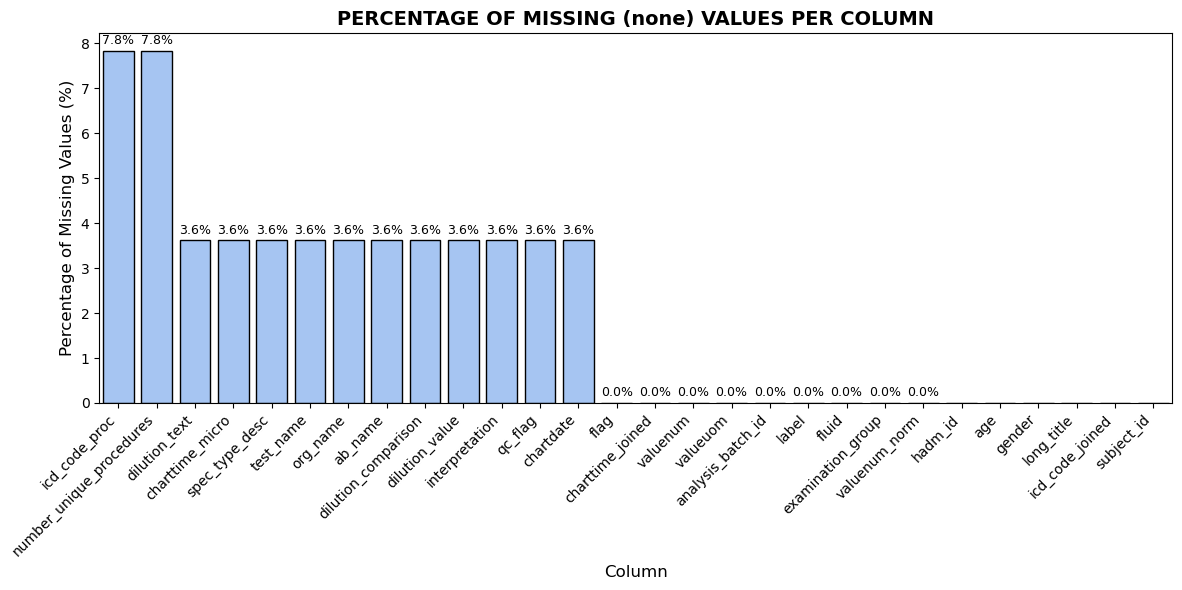


=== PERCENTAGE OF MISSING VALUES ===

icd_code_proc               7.828595
number_unique_procedures    7.828595
dilution_text               3.622754
charttime_micro             3.622754
spec_type_desc              3.622754
test_name                   3.622754
org_name                    3.622754
ab_name                     3.622754
dilution_comparison         3.622754
dilution_value              3.622754
interpretation              3.622754
qc_flag                     3.622754
chartdate                   3.622754
flag                        0.000223
charttime_joined            0.000223
valuenum                    0.000223
valueuom                    0.000223
analysis_batch_id           0.000223
label                       0.000223
fluid                       0.000223
examination_group           0.000223
valuenum_norm               0.000223
hadm_id                     0.000000
age                         0.000000
gender                      0.000000
long_title                  0.000000

In [6]:
# Compute and plot percentage of missing values per column

print("NUMBER OF MISSING (none) VALUES PER COLUMN:\n")
none_counts = joined_df.isna().sum().sort_values(ascending=False)
print(none_counts)


total_rows = len(joined_df)

none_percentages = (none_counts / total_rows * 100).sort_values(ascending=False)

none_df = none_percentages.reset_index()
none_df.columns = ["column", "percentage"]

fig, ax = plt.subplots(figsize=(12,6))
sns.barplot(data=none_df, x="column", y="percentage", color="#99c2ff", edgecolor="black")

plt.title("PERCENTAGE OF MISSING (none) VALUES PER COLUMN", fontsize=14, fontweight='bold')
plt.xlabel("Column", fontsize=12)
plt.ylabel("Percentage of Missing Values (%)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

for i, v in enumerate(none_df["percentage"]):
    if v > 0: 
        ax.text(i, v + max(none_df["percentage"]) * 0.01, 
                f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

plt.show()

print("\n=== PERCENTAGE OF MISSING VALUES ===\n")
print(none_percentages)

In [7]:
# Inspect missing 'valuenum' entries and count affected patients

joined_df[joined_df['valuenum'].isnull()]
joined_df['valuenum'].isna().sum()
# print the number of patients who have at least one missing lab test value
patients_with_missing_lab_tests = joined_df[joined_df['valuenum'].isnull()]['subject_id'].nunique()
print(f"Number of patients with at least one missing lab test value: {patients_with_missing_lab_tests}")

Number of patients with at least one missing lab test value: 10


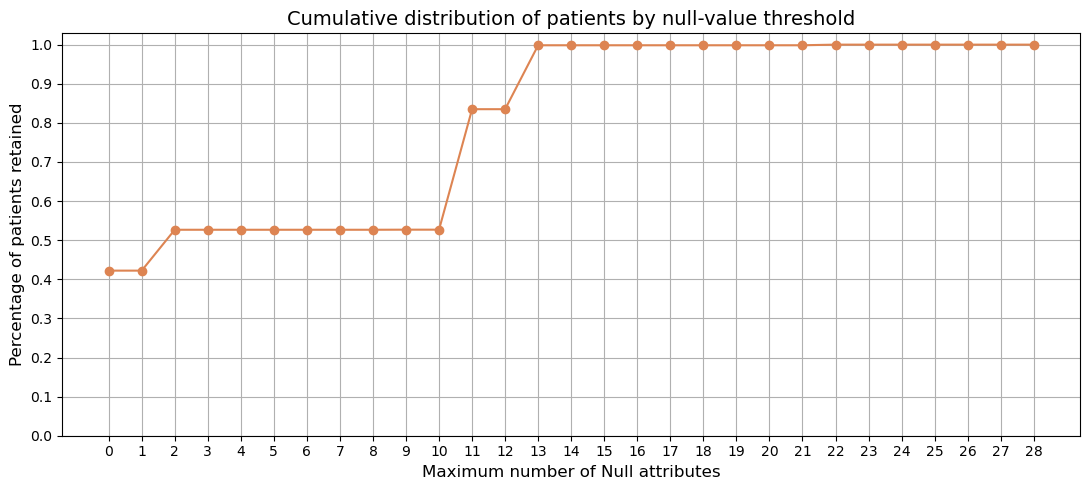

In [8]:
# Compute cumulative patient retention vs null-value threshold and plot

# Dictionary to store the cumulative percentage of patients
temp_pazienti = {}

# Total unique patients in the dataset
totale_pazienti = joined_df["subject_id"].nunique()

# Loop over thresholds from 0 to number of columns
for threshold in range(0, len(joined_df.columns)+1):
    # Mask: rows with at most 'threshold' null values
    mask = (joined_df.isnull().sum(axis=1)) <= threshold

    # Unique patients that would remain
    pazienti_mantenuti = joined_df[mask]["subject_id"].nunique()

    # Percentage of patients retained
    temp_pazienti[threshold] = pazienti_mantenuti / totale_pazienti

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(list(temp_pazienti.keys()), list(temp_pazienti.values()), marker='o', color="#dd8452")

ax.set_xticks(range(0, len(joined_df.columns)+1, 1))
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.grid(True)
ax.set_xlabel("Maximum number of Null attributes", fontsize=12)
ax.set_ylabel("Percentage of patients retained", fontsize=12)
ax.set_title("Cumulative distribution of patients by null-value threshold", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
# Apply null-value threshold and report patients/rows removed

# Current threshold
threshold = 13

# Mask: rows with more than threshold null values
mask_drop = joined_df.isnull().sum(axis=1) > threshold

# Apply the mask to get the cleaned dataframe
df_cleaned = joined_df[~mask_drop]

# TOTAL patients before cleaning
pazienti_before = joined_df["subject_id"].nunique()

# Patients REMAINING after cleaning
pazienti_after = df_cleaned["subject_id"].nunique()

# Patients LOST completely (no rows left)
pazienti_persi = pazienti_before - pazienti_after

# Percentage of total
percentuale_persi = (pazienti_persi / pazienti_before) * 100

print(f"Total patients before: {pazienti_before}")
print(f"Patients remaining after: {pazienti_after}")
print(f"Patients lost completely: {pazienti_persi} ({percentuale_persi:.2f}%)")

# Additional info
righe_before = len(joined_df)
righe_after = len(df_cleaned)
righe_perse = righe_before - righe_after
print(f"\nTotal rows before: {righe_before}")
print(f"Rows removed: {righe_perse} ({(righe_perse/righe_before)*100:.2f}%)")
print(f"Rows remaining: {righe_after}")

Total patients before: 4392
Patients remaining after: 4385
Patients lost completely: 7 (0.16%)

Total rows before: 5389243
Rows removed: 9 (0.00%)
Rows remaining: 5389234


In [10]:
# Define drop function, drop rows by threshold, and fill common NaNs

def drop_rows_with_nulls(df, threshold, ignore_cols=[]):
    """
    Remove rows that have more than 'threshold' null values,
    ignoring columns specified in 'ignore_cols'.
    """
    cols_to_check = [col for col in df.columns if col not in ignore_cols]
    min_non_nulls = len(cols_to_check) - threshold
    df_cleaned = df.dropna(thresh=min_non_nulls, subset=cols_to_check).copy()
    return df_cleaned

joined_df = drop_rows_with_nulls(joined_df, threshold=13)

# Define fill values
fill_values = {
    'valueuom': "NO_UOM",
    'flag': -1,
    'label': "NO_LAB_LABEL",
    'fluid': "NO_FLUID",
    'examination_group': "NO_EXAM_GROUP",
    'analysis_batch_id': "NO_BATCH_ID",
    'number_unique_procedures': 0,
    'icd_code_proc': "NO_PROCEDURES"
}


joined_df = joined_df.fillna(fill_values)

joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5389238,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
5389239,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
5389240,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
5389241,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES


In [11]:
# Report remaining missing 'valuenum' and list affected subject(s)

# print empty values of 'valuenum' after cleaning
joined_df[joined_df['valuenum'].isnull()]
joined_df['valuenum'].isna().sum()
print(f"Number of missing values in 'valuenum': {joined_df['valuenum'].isna().sum()}")

# print the number of patients who have at least one missing lab test value
patients_with_missing_lab_tests = joined_df[joined_df['valuenum'].isnull()]['subject_id'].nunique()
print(f"Number of patients with at least one missing lab test value: {patients_with_missing_lab_tests}")

# print the subject_id(s) with missing valuenum
subjectnan = joined_df[joined_df['valuenum'].isnull()]['subject_id'].unique()
print(subjectnan)

# print the rows for the first such subject_id (for inspection)
print(joined_df[joined_df['subject_id'] == subjectnan[0]])

Number of missing values in 'valuenum': 3
Number of patients with at least one missing lab test value: 1
[17737493]
         subject_id   hadm_id  icd_code_joined  \
4184130    17737493  20810369               34   
4184131    17737493  20810369               34   
4184132    17737493  20810369               34   

                                  long_title  gender  age charttime_joined  \
4184130  Nonrheumatic mitral valve disorders       0   71              NaN   
4184131  Nonrheumatic mitral valve disorders       0   71              NaN   
4184132  Nonrheumatic mitral valve disorders       0   71              NaN   

         valuenum valueuom  flag  ...               test_name  \
4184130       NaN   NO_UOM  -1.0  ...  BLOOD CULTURE, ROUTINE   
4184131       NaN   NO_UOM  -1.0  ...           URINE CULTURE   
4184132       NaN   NO_UOM  -1.0  ...  BLOOD CULTURE, ROUTINE   

                org_name         ab_name dilution_text  dilution_comparison  \
4184130  NO_ORG_DETECTED  NO_A

We have only one patient with valuenum missing; to guarantee a reliable laboratory-based representation we remove this patient.

In [12]:
# Remove subject(s) without numeric 'valuenum'

joined_df = joined_df[joined_df['subject_id'] != subjectnan[0]]
joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,1.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,85.80,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5389238,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
5389239,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
5389240,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
5389241,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES


In [13]:
# Show number of unique patients remaining

joined_df['subject_id'].nunique()

4384

In [14]:
# Fill microbiology-related missing fields for patients without tests

# Filling the missing values for those who did not have a microbio test done
joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")
joined_df

#If NO_MICROBIO, fill the microbio_test fields 
micro_bio_cols = ['org_name', 'ab_name', 'dilution_text','dilution_comparison','dilution_value', 'interpretation', 'qc_flag']

micro_bio_mask = joined_df['spec_type_desc'] == "NO_MICROBIO"

#Fill orgname with NOT_ORG_DETECTED
joined_df.loc[micro_bio_mask, 'org_name'] = joined_df.loc[micro_bio_mask, 'org_name'].fillna(value = "NO_ORG_DETECTED")

#Fill test_name with NO_TEST_DONE
joined_df.loc[micro_bio_mask, 'test_name'] = joined_df.loc[micro_bio_mask, 'test_name'].fillna(value = "NO_TEST_DONE")

# Fill ab_name with NO_AB_DETECTED
joined_df.loc[micro_bio_mask, 'ab_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_AB_DETECTED")

#Fill dilution_text with "-1"
joined_df.loc[micro_bio_mask, 'dilution_text'] = joined_df.loc[micro_bio_mask, 'dilution_text'].fillna(value = "-1")

#Fill dilution_comparison with "="
joined_df.loc[micro_bio_mask, 'dilution_comparison'] = joined_df.loc[micro_bio_mask, 'dilution_comparison'].fillna(value = "=")

#Fill dilution_value with -1
joined_df.loc[micro_bio_mask, 'dilution_value'] = joined_df.loc[micro_bio_mask, 'dilution_value'].fillna(value = -1)

#Fill interpretation with NOT_INTERPRETATION
joined_df.loc[micro_bio_mask, 'interpretation'] = joined_df.loc[micro_bio_mask, 'interpretation'].fillna(value = "NO_INTERPRETATION")

#Fill qc_flag with NOT_QC_FLAG
joined_df.loc[micro_bio_mask, 'qc_flag'] = joined_df.loc[micro_bio_mask, 'qc_flag'].fillna(value = "NO_QC_FLAG")

joined_df


/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_54550/2188303324.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")


,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
1,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
2,10000980,29654838,50,Heart failure,1,75,2188-01-04 23:43:00,0.03,ng/mL,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
3,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,1.20,u,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4,10000980,29654838,50,Heart failure,1,75,2188-01-05 06:56:00,85.80,sec,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5389238,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
5389239,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,143.00,mg/dL,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
5389240,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
5389241,19998600,21593455,35,Nonrheumatic aortic valve disorders,0,83,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES


## Correlation between the cols

In [15]:
# Identify numeric columns and compute Pearson correlation

numeric_cols = du.get_numeric_cols(joined_df)
joined_df[numeric_cols].corr("pearson")

,icd_code_joined,gender,age,valuenum,flag,valuenum_norm,dilution_value,number_unique_procedures
icd_code_joined,1.000000,-0.037678,0.218811,-0.004001,0.020449,-0.034321,0.055855,-0.218018
gender,-0.037678,1.000000,0.118178,0.005635,-0.019618,0.006834,0.051188,-0.067124
age,0.218811,0.118178,1.000000,0.000342,0.024227,-0.001914,0.068804,-0.154056
valuenum,-0.004001,0.005635,0.000342,1.000000,0.025938,0.036104,-0.000069,0.002831
flag,0.020449,-0.019618,0.024227,0.025938,1.000000,0.046861,0.006169,0.073780
valuenum_norm,-0.034321,0.006834,-0.001914,0.036104,0.046861,1.000000,-0.000959,0.013185
dilution_value,0.055855,0.051188,0.068804,-0.000069,0.006169,-0.000959,1.000000,-0.048781
number_unique_procedures,-0.218018,-0.067124,-0.154056,0.002831,0.073780,0.013185,-0.048781,1.000000


In [16]:
# Compute Kendall correlation for numeric columns

joined_df[numeric_cols].corr("kendall")

,icd_code_joined,gender,age,valuenum,flag,valuenum_norm,dilution_value,number_unique_procedures
icd_code_joined,1.000000,-0.010945,0.336741,0.007568,0.015488,-0.000319,0.024523,-0.221499
gender,-0.010945,1.000000,0.076409,0.004749,-0.019618,-0.000603,0.135219,-0.077066
age,0.336741,0.076409,1.000000,0.008161,0.024142,0.008024,0.119321,-0.131166
valuenum,0.007568,0.004749,0.008161,1.000000,0.004822,0.100000,0.002965,-0.010878
flag,0.015488,-0.019618,0.024142,0.004822,1.000000,0.081660,0.011551,0.060998
valuenum_norm,-0.000319,-0.000603,0.008024,0.100000,0.081660,1.000000,-0.001590,-0.006569
dilution_value,0.024523,0.135219,0.119321,0.002965,0.011551,-0.001590,1.000000,0.025981
number_unique_procedures,-0.221499,-0.077066,-0.131166,-0.010878,0.060998,-0.006569,0.025981,1.000000


In [17]:
# Compute Spearman correlation for numeric columns

joined_df[numeric_cols].corr("spearman")

,icd_code_joined,gender,age,valuenum,flag,valuenum_norm,dilution_value,number_unique_procedures
icd_code_joined,1.000000,-0.012179,0.488063,0.010279,0.017234,-0.000316,0.029960,-0.283942
gender,-0.012179,1.000000,0.087772,0.005809,-0.019618,-0.000738,0.143826,-0.091683
age,0.488063,0.087772,1.000000,0.011480,0.027732,0.011063,0.144827,-0.189980
valuenum,0.010279,0.005809,0.011480,1.000000,0.005898,0.128970,0.003851,-0.015815
flag,0.017234,-0.019618,0.027732,0.005898,1.000000,0.099848,0.012287,0.072567
valuenum_norm,-0.000316,-0.000738,0.011063,0.128970,0.099848,1.000000,-0.002083,-0.009530
dilution_value,0.029960,0.143826,0.144827,0.003851,0.012287,-0.002083,1.000000,0.032659
number_unique_procedures,-0.283942,-0.091683,-0.189980,-0.015815,0.072567,-0.009530,0.032659,1.000000


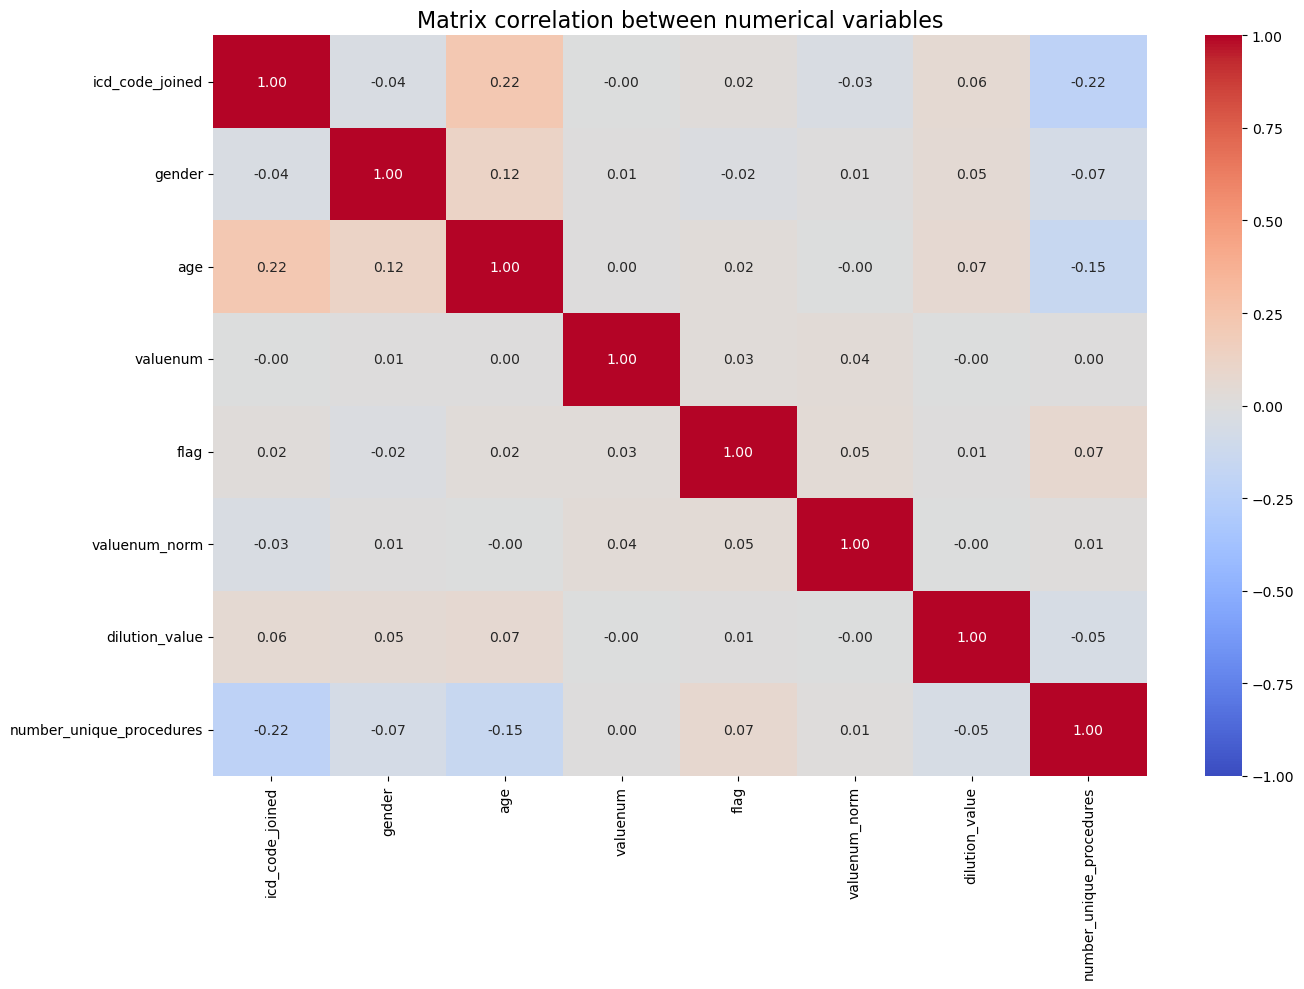

In [18]:
# Plot heatmap of numeric correlations

df_num = joined_df[numeric_cols]

corr_matrix = df_num.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrix correlation between numerical variables", fontsize=16)
plt.tight_layout()
plt.show()


# Feature creation

In [19]:
# Create base patient profile dataframe with key identifiers

# Creating the new features representing the profiles of the patients
#Taking the common attributes (subject_id,hadm_id, gender, age, ICD)
profile_cols = ['subject_id', 'hadm_id', 'gender', 'age']
profile_df = joined_df[profile_cols].drop_duplicates().reset_index(drop=True)

In [20]:
# Compute lab event counts and abnormal lab counts per admission

# Dropping duplicates based on the cols that makes a lab event unique
lab_uniq = joined_df.drop_duplicates(subset=['hadm_id','charttime_joined', 'label'])

# Number of hammission
hadm_count=profile_df[['subject_id', 'hadm_id']].drop_duplicates().groupby('subject_id')['hadm_id'].size().reset_index(name='number_of_hadm')
# Dropping duplicates based on the cols that makes a lab event unique
profile_df = pd.merge(profile_df, hadm_count, on='subject_id', how='left')


# === LAB PROFILE FEATURES === #

# Creating the feature for the lab events, if "NO_LAB_LABEL" then count is 0
lab_event_counts = lab_uniq[lab_uniq['label'] != "NO_LAB_LABEL"].groupby(['subject_id', 'hadm_id'])['label'].count().reset_index()
lab_event_counts = lab_event_counts.rename(columns={'label': 'lab_event_count'})

# Merge with profile_df
profile_df = pd.merge(profile_df, lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['lab_event_count'] = profile_df['lab_event_count'].fillna(0)
abnormal_lab_event_counts = lab_uniq[lab_uniq['flag'] == 1].groupby(['subject_id', 'hadm_id'])['flag'].count().reset_index()
abnormal_lab_event_counts = abnormal_lab_event_counts.rename(columns={'flag': 'abnormal_lab_event_count'})
profile_df = pd.merge(profile_df, abnormal_lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['abnormal_lab_event_count'] = profile_df['abnormal_lab_event_count'].fillna(0)
profile_df




,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count
0,10000980,29654838,1,75,2,45.0,18.0
1,10000980,26913865,1,75,2,124.0,51.0
2,10002013,24760295,1,69,1,40.0,15.0
3,10002155,23822395,1,69,1,287.0,111.0
4,10004457,28723315,0,66,1,21.0,7.0
...,...,...,...,...,...,...,...
4849,19998596,24860241,1,71,1,0.0,0.0
4850,19998597,23720781,1,57,1,0.0,0.0
4851,19998598,26940500,1,69,1,0.0,0.0
4852,19998599,20343031,0,59,1,0.0,0.0


In [21]:
# Compute procedure counts and derive laboratory indicator features

# === PROCEDURE PROFILE FEATURES === #

# Dropping duplicates based on the cols that makes a procedure event unique
procedure_uniq = joined_df.drop_duplicates(subset=['subject_id', 'hadm_id','icd_code_proc'])

# Count the number of unique procedures (splitting comma-separated codes) per subject_id and hadm_id
# If "NO_PROCEDURES" then count is 0
procedure_counts = (
    procedure_uniq[procedure_uniq['icd_code_proc'] != "NO_PROCEDURES"]
    .groupby(['subject_id', 'hadm_id'])['icd_code_proc']
    .apply(lambda x: sum(len(proc.split(',') ) for proc in x))
    .reset_index(name='unique_procedures_count')
)

# Merge with profile_df
profile_df = pd.merge(profile_df, procedure_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_procedures_count'] = profile_df['unique_procedures_count'].fillna(0)
profile_df


# == SOME INDICATORS ==
# We choose as indicators values with more occurrences and clinical relevance
# for each examination group evaluet also the correlation matrix to choose the most representative exams

features = {}

for exam in [
    "Glucose","Potassium","Sodium","Creatinine","Bicarbonate",
    "Calcium, Total","Urea Nitrogen","Creatinine","Troponin T",
    "NTproBNP","PTT","INR(PT)","Hemoglobin","Platelet Count",
    "White Blood Cells","Cholesterol Ratio (Total/HDL)", "pCO2"
]:
    feat = (
        lab_uniq[lab_uniq['label'] == exam]
        .groupby(['subject_id','hadm_id'])['valuenum_norm']
        .max()
        .reset_index()
        .rename(columns={'valuenum_norm': f"max_{exam.lower()}"})
    )
    features[exam] = feat

ph_feat = (
    lab_uniq[lab_uniq['label'] == "pH"]
    .groupby(['subject_id','hadm_id'])['valuenum_norm']
    .min()
    .reset_index()
    .rename(columns={'valuenum_norm': 'min_ph'})
)

features["pH"] = ph_feat

# Merge
for feat in features.values():
    profile_df = profile_df.merge(feat, on=['subject_id','hadm_id'], how='left')

profile_df = profile_df.fillna(0)

# Remove duplicates (just in case)
profile_df = profile_df.drop_duplicates().reset_index(drop=True)
profile_df


,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count,unique_procedures_count,max_glucose,max_potassium,...,max_troponin t,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_pco2,min_ph
0,10000980,29654838,1,75,2,45.0,18.0,0.0,2.266667,0.666667,...,4.0,0.0,5.286957,1.5,-0.525,0.162069,0.128571,1.000000,0.0,0.0
1,10000980,26913865,1,75,2,124.0,51.0,7.0,3.100000,0.666667,...,15.0,0.0,3.878261,2.0,-0.475,0.251724,0.328571,0.000000,0.0,0.0
2,10002013,24760295,1,69,1,40.0,15.0,2.0,10.833333,0.166667,...,13.0,0.0,4.634783,0.5,0.025,0.389655,0.714286,0.000000,0.0,0.0
3,10002155,23822395,1,69,1,287.0,111.0,8.0,2.000000,1.277778,...,399.0,0.0,5.661538,10.5,0.125,0.341379,0.500000,0.000000,1.3,0.8
4,10004457,28723315,0,66,1,21.0,7.0,0.0,0.733333,1.000000,...,0.0,0.0,0.000000,0.0,-0.075,0.396552,0.357143,1.228571,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4849,19998596,24860241,1,71,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0
4850,19998597,23720781,1,57,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0
4851,19998598,26940500,1,69,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0
4852,19998599,20343031,0,59,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.0,0.000000,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0


In [22]:
# === MICROBIO PROFILE FEATURES === #

# Dropping duplicates based on the cols that makes a microbio event unique
microbio_uniq = joined_df.drop_duplicates(subset=['hadm_id','charttime_micro', 'spec_type_desc', 'org_name', 'ab_name'])

# Counting the number of microbio tests done per subject_id and hadm_id, if "NO_MICROBIO" then count is 0, using microbio_uniq
# Deduplicazione mirata sugli eventi microbiologici
microbio_test_counts = microbio_uniq[microbio_uniq['spec_type_desc'] != "NO_MICROBIO"].groupby(['subject_id', 'hadm_id'])['spec_type_desc'].nunique().reset_index()
microbio_test_counts = microbio_test_counts.rename(columns={'spec_type_desc': 'microbio_test_count'})

# Merge
profile_df = pd.merge(profile_df, microbio_test_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['microbio_test_count'] = profile_df['microbio_test_count'].fillna(0)

# Counting the number of unique microorganisms detected per subject_id and hadm_id, if "NO_ORG_DETECTED" then count is 0, useing microbio_uniq
microbio_counts = microbio_uniq[microbio_uniq['org_name'] != "NO_ORG_DETECTED"].groupby(['subject_id', 'hadm_id'])['org_name'].nunique().reset_index()
microbio_counts = microbio_counts.rename(columns={'org_name': 'unique_microorganisms_count'})
profile_df = pd.merge(profile_df, microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_microorganisms_count'] = profile_df['unique_microorganisms_count'].fillna(0)

# Number of unique antibiotics detected per subject_id and hadm_id, if "NO_AB_DETECTED" then count is 0, using microbio_uniq
ab_count=microbio_uniq[microbio_uniq['ab_name'] != "NO_AB_DETECTED"].groupby(['subject_id', 'hadm_id'])['ab_name'].nunique().reset_index()
ab_count = ab_count.rename(columns={'ab_name': 'unique_antibiotics_count'})
profile_df = pd.merge(profile_df, ab_count, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_antibiotics_count'] = profile_df['unique_antibiotics_count'].fillna(0)



profile_df

,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count,unique_procedures_count,max_glucose,max_potassium,...,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),max_pco2,min_ph,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count
0,10000980,29654838,1,75,2,45.0,18.0,0.0,2.266667,0.666667,...,1.5,-0.525,0.162069,0.128571,1.000000,0.0,0.0,0.0,0.0,0.0
1,10000980,26913865,1,75,2,124.0,51.0,7.0,3.100000,0.666667,...,2.0,-0.475,0.251724,0.328571,0.000000,0.0,0.0,1.0,0.0,0.0
2,10002013,24760295,1,69,1,40.0,15.0,2.0,10.833333,0.166667,...,0.5,0.025,0.389655,0.714286,0.000000,0.0,0.0,0.0,0.0,0.0
3,10002155,23822395,1,69,1,287.0,111.0,8.0,2.000000,1.277778,...,10.5,0.125,0.341379,0.500000,0.000000,1.3,0.8,4.0,0.0,0.0
4,10004457,28723315,0,66,1,21.0,7.0,0.0,0.733333,1.000000,...,0.0,-0.075,0.396552,0.357143,1.228571,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4849,19998596,24860241,1,71,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
4850,19998597,23720781,1,57,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
4851,19998598,26940500,1,69,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
4852,19998599,20343031,0,59,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0.000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0


Numero di pazienti per ICD code:
20: 35
21: 1382
22: 5
24: 12
25: 630
30: 82
31: 150
33: 38
34: 49
35: 218
36: 1
40: 16
42: 33
44: 70
45: 5
46: 2
47: 128
48: 422
49: 35
50: 1295


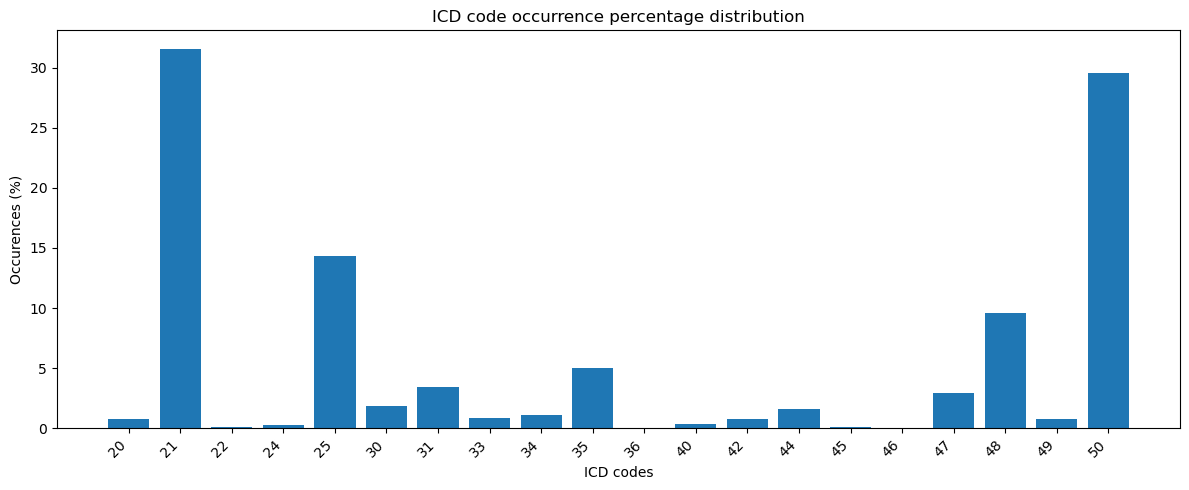

In [23]:
# Count patients per ICD code and plot percentage distribution

icd_patient = (
    joined_df[['subject_id', 'icd_code_joined']]
    .dropna(subset=['icd_code_joined'])
    .drop_duplicates()   # <-- chiave
)

icd_patient_counts = icd_patient['icd_code_joined'].value_counts().sort_index()

print("Numero di pazienti per ICD code:")
for code, cnt in icd_patient_counts.items():
    print(f"{code}: {cnt}")

icd_patient_perc = icd_patient_counts / joined_df['subject_id'].nunique() * 100

plt.figure(figsize=(12, 5))
plt.bar(icd_patient_perc.index.astype(str), icd_patient_perc.values)
plt.xlabel("ICD codes")
plt.ylabel("Occurences (%)")
plt.title("ICD code occurrence percentage distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

##### Aggregation of ICD codes into macro-categories 
In the dataset there are several ICD codes related to cardiac conditions (I20–I50).  
To avoid keeping a binary column for each ICD (with many sparse and uninformative features), we decided to group the codes into 9 clinically coherent macro-categories.  

For each patient (considering all their admissions), we therefore build 9 binary features: each feature equals 1 if the patient has at least one ICD belonging to that category, otherwise 0.

### Final features (9 columns)

- ACS_acute_ischemic = 1 if they have one of I20, I21, I22, I24
- Chronic_ischemic = 1 if they have I25
- Heart_failure = 1 if they have I50
- Valvular_nonrheumatic = 1 if they have one of I34, I35, I36
- Myocarditis_or_cardiomyopathy = 1 if they have one of I40, I42
- Pericardial_disease = 1 if they have one of I30, I31
- Endocarditis = 1 if they have I33
- Cardiac_arrest = 1 if they have I46
- Arrhythmias_or_conduction = 1 if they have one of I44, I45, I47, I48, I49


In [24]:
# Map ICD codes to macro-categories and merge into the patient profile

ICD_MACRO_MAP = {
    # Ischemic
    20: "ACS_acute_ischemic",
    21: "ACS_acute_ischemic",
    22: "ACS_acute_ischemic",
    24: "ACS_acute_ischemic",
    25: "Chronic_ischemic",

    # Heart failure
    50: "Heart_failure",

    # Structural / inflammatory
    34: "Valvular_nonrheumatic",
    35: "Valvular_nonrheumatic",
    36: "Valvular_nonrheumatic",
    40: "Myocarditis_or_cardiomyopathy",
    42: "Myocarditis_or_cardiomyopathy",
    30: "Pericardial_disease",
    31: "Pericardial_disease",
    33: "Endocarditis",

    # Arrest
    46: "Cardiac_arrest",

    # Arrhythmias / conduction (grouped)
    44: "Arrhythmias_or_conduction",
    45: "Arrhythmias_or_conduction",
    47: "Arrhythmias_or_conduction",
    48: "Arrhythmias_or_conduction",
    49: "Arrhythmias_or_conduction",
}

ICD_MACRO_COLS = [
    "ACS_acute_ischemic",
    "Chronic_ischemic",
    "Heart_failure",
    "Valvular_nonrheumatic",
    "Myocarditis_or_cardiomyopathy",
    "Pericardial_disease",
    "Endocarditis",
    "Cardiac_arrest",
    "Arrhythmias_or_conduction",
]

icd_tmp = joined_df[["subject_id", "hadm_id", "icd_code_joined"]].drop_duplicates()
icd_tmp = icd_tmp.dropna(subset=["icd_code_joined"]).copy()

icd_tmp["icd_code_joined"] = pd.to_numeric(icd_tmp["icd_code_joined"], errors="coerce").astype("Int64")
icd_tmp["icd_group"] = icd_tmp["icd_code_joined"].map(ICD_MACRO_MAP)
icd_tmp = icd_tmp.dropna(subset=["icd_group"])

icd_macro = (
    pd.crosstab([icd_tmp["subject_id"], icd_tmp["hadm_id"]], icd_tmp["icd_group"])
      .clip(upper=1)
      .reset_index()
)

profile_df = pd.merge(profile_df, icd_macro, on=["subject_id", "hadm_id"], how="left")

for col in ICD_MACRO_COLS:
    if col not in profile_df.columns:
        profile_df[col] = 0
profile_df[ICD_MACRO_COLS] = profile_df[ICD_MACRO_COLS].fillna(0).astype(int)

if "icd_code_joined" in profile_df.columns:
    profile_df = profile_df.drop(columns=["icd_code_joined"])

profile_df

,subject_id,hadm_id,gender,age,number_of_hadm,lab_event_count,abnormal_lab_event_count,unique_procedures_count,max_glucose,max_potassium,...,unique_antibiotics_count,ACS_acute_ischemic,Arrhythmias_or_conduction,Cardiac_arrest,Chronic_ischemic,Endocarditis,Heart_failure,Myocarditis_or_cardiomyopathy,Pericardial_disease,Valvular_nonrheumatic
0,10000980,29654838,1,75,2,45.0,18.0,0.0,2.266667,0.666667,...,0.0,0,0,0,0,0,1,0,0,0
1,10000980,26913865,1,75,2,124.0,51.0,7.0,3.100000,0.666667,...,0.0,1,0,0,0,0,0,0,0,0
2,10002013,24760295,1,69,1,40.0,15.0,2.0,10.833333,0.166667,...,0.0,1,0,0,0,0,0,0,0,0
3,10002155,23822395,1,69,1,287.0,111.0,8.0,2.000000,1.277778,...,0.0,1,0,0,0,0,0,0,0,0
4,10004457,28723315,0,66,1,21.0,7.0,0.0,0.733333,1.000000,...,0.0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4849,19998596,24860241,1,71,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0,1,0,0,0,0,0,0,0
4850,19998597,23720781,1,57,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0,0,0,0,0,0,0,1,0
4851,19998598,26940500,1,69,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0,1,0,0,0,0,0,0,0
4852,19998599,20343031,0,59,1,0.0,0.0,0.0,0.000000,0.000000,...,0.0,0,0,0,0,0,0,0,1,0


Number of patients per ICD macro-category:
icd_group
ACS_acute_ischemic               1430
Chronic_ischemic                  630
Heart_failure                    1295
Valvular_nonrheumatic             268
Myocarditis_or_cardiomyopathy      49
Pericardial_disease               230
Endocarditis                       38
Cardiac_arrest                      2
Arrhythmias_or_conduction         657
Name: count, dtype: int64


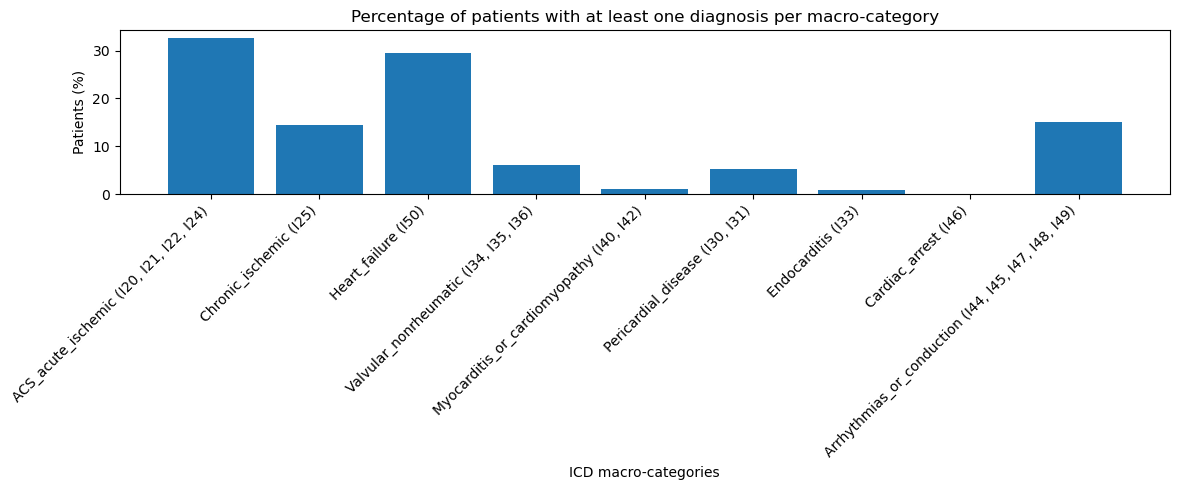

In [25]:
# Plot patient percentage by ICD macro-category

# Extended labels
ICD_MACRO_LABELS = {
    "ACS_acute_ischemic": "ACS_acute_ischemic (I20, I21, I22, I24)",
    "Chronic_ischemic": "Chronic_ischemic (I25)",
    "Heart_failure": "Heart_failure (I50)",
    "Valvular_nonrheumatic": "Valvular_nonrheumatic (I34, I35, I36)",
    "Myocarditis_or_cardiomyopathy": "Myocarditis_or_cardiomyopathy (I40, I42)",
    "Pericardial_disease": "Pericardial_disease (I30, I31)",
    "Endocarditis": "Endocarditis (I33)",
    "Cardiac_arrest": "Cardiac_arrest (I46)",
    "Arrhythmias_or_conduction": "Arrhythmias_or_conduction (I44, I45, I47, I48, I49)",
}

icd_patient_macro = (
    icd_tmp
    .drop_duplicates(subset=['subject_id', 'icd_group'])  # Keep one row per patient per macro-category
)

macro_patient_counts = (
    icd_patient_macro['icd_group']
    .value_counts()
    .reindex(ICD_MACRO_COLS, fill_value=0)
)

print("Number of patients per ICD macro-category:")
print(macro_patient_counts)

macro_patient_perc = macro_patient_counts / joined_df['subject_id'].nunique() * 100

x_labels = [ICD_MACRO_LABELS[c] for c in ICD_MACRO_COLS]

plt.figure(figsize=(12, 5))
plt.bar(range(len(ICD_MACRO_COLS)), macro_patient_perc.values)
plt.xticks(range(len(ICD_MACRO_COLS)), x_labels, rotation=45, ha="right")
plt.ylabel("Patients (%)")
plt.xlabel("ICD macro-categories")
plt.title("Percentage of patients with at least one diagnosis per macro-category")
plt.tight_layout()
plt.show()

In [26]:
# (correctness check) Patients who have MORE than one distinct ICD within the SAME macro-category

# Patient–ICD count
n_patient_icd = icd_patient_counts.sum()

# Patient–macro-category count
n_patient_macro = macro_patient_counts.sum()

print("Sum of patients per ICD:", n_patient_icd)
print("Sum of patients per macro-category:", n_patient_macro)
print("Difference:", n_patient_icd - n_patient_macro)

dup_macro = (
    icd_tmp
    .groupby(['subject_id', 'icd_group'])['icd_code_joined']
    .nunique()
    .reset_index(name='n_icd')
)

dup_macro_multi = dup_macro[dup_macro['n_icd'] > 1]

print("Patients with multiple ICDs within the same macro-category:")
print(dup_macro_multi)

print("\nNumber of patients involved:",
      dup_macro_multi['subject_id'].nunique())


Sum of patients per ICD: 4608
Sum of patients per macro-category: 4599
Difference: 9
Patients with multiple ICDs within the same macro-category:
      subject_id                  icd_group  n_icd
188     10453833  Arrhythmias_or_conduction      2
262     10653013        Pericardial_disease      2
1849    14101623         ACS_acute_ischemic      2
3677    18184558         ACS_acute_ischemic      2
3782    18406654  Arrhythmias_or_conduction      2
3877    18619444  Arrhythmias_or_conduction      2
3970    18844748        Pericardial_disease      2
4285    19544020         ACS_acute_ischemic      2
4445    19914314         ACS_acute_ischemic      2

Number of patients involved: 9


In [27]:
# Aggregate profile features per subject (final patient-level profile)

agg_dict = {col: "max" for col in ICD_MACRO_COLS}

agg_dict.update({
    "number_of_hadm": "first",
    "gender": "first",
    "age": "first",
    "lab_event_count": "sum",
    "abnormal_lab_event_count": "sum",
    "microbio_test_count": "sum",
    "unique_microorganisms_count": "sum",
    "unique_antibiotics_count": "sum",
    "unique_procedures_count": "sum",
    "max_glucose": "max",
    'max_potassium': 'max',
    'max_sodium': 'max',
    'max_creatinine': 'max',
    'max_bicarbonate': 'max',
    'max_calcium, total': 'max',
    'max_urea nitrogen': 'max',
    'max_troponin t': 'max',
    'max_ntprobnp': 'max',
    'max_ptt': 'max',
    'max_inr(pt)': 'max',
    'max_hemoglobin': 'max',
    'max_platelet count': 'max', 
    'max_white blood cells': 'max',
    'max_cholesterol ratio (total/hdl)': 'max',
    'min_ph': 'min',
    'max_pco2': 'max'
})

profile_df = profile_df.groupby("subject_id").agg(agg_dict).reset_index()
profile_df.drop_duplicates(inplace=True)

profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_troponin t,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2
0,10000980,1,0,1,0,0,0,0,0,0,...,15.0,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0
1,10002013,1,0,0,0,0,0,0,0,0,...,13.0,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0
2,10002155,1,0,0,0,0,0,0,0,0,...,399.0,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0
4,10007058,1,0,0,0,0,0,0,0,0,...,277.0,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0


In [28]:
# Brief: Compare patient counts per ICD vs macro-category and find patients with multiple ICDs in the same macro-category

profile_df["abnormal_lab_event_ratio"] = np.where(
    profile_df["lab_event_count"] > 0,
    profile_df["abnormal_lab_event_count"] / profile_df["lab_event_count"],
    0.0
)

cols_drop = [
    "abnormal_lab_event_count",
]
profile_df = profile_df.drop(columns=[c for c in cols_drop if c in profile_df.columns], errors="ignore")
#salva the profile_df1
profile_df.to_csv("../../data/processed/patient_profile.csv", index=False)

profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


# Analyses of the new features


In [29]:
# Display profile dataframe info

profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4384 entries, 0 to 4383
Data columns (total 36 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   subject_id                         4384 non-null   int64  
 1   ACS_acute_ischemic                 4384 non-null   int64  
 2   Chronic_ischemic                   4384 non-null   int64  
 3   Heart_failure                      4384 non-null   int64  
 4   Valvular_nonrheumatic              4384 non-null   int64  
 5   Myocarditis_or_cardiomyopathy      4384 non-null   int64  
 6   Pericardial_disease                4384 non-null   int64  
 7   Endocarditis                       4384 non-null   int64  
 8   Cardiac_arrest                     4384 non-null   int64  
 9   Arrhythmias_or_conduction          4384 non-null   int64  
 10  number_of_hadm                     4384 non-null   int64  
 11  gender                             4384 non-null   int64

In [30]:
# Convert to string

profile_df['subject_id'] = profile_df['subject_id'].astype(object)

In [31]:
# Show descriptive statistics for the patient profile

profile_df.describe()

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,number_of_hadm,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
count,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,...,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000,4384.000000
mean,0.326186,0.143704,0.295392,0.061131,0.011177,0.052464,0.008668,0.000456,0.149863,1.107208,...,2.743187,3.073514,3.622776,-0.162360,0.382139,0.950013,0.209078,-0.020529,0.338572,0.368127
std,0.468870,0.350830,0.456271,0.239598,0.105141,0.222985,0.092708,0.021357,0.356978,0.374773,...,15.381448,3.577754,5.922192,0.476161,0.380911,1.054388,0.473356,0.475379,0.893647,0.152256
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,-0.434783,-0.500000,-1.875000,-0.476000,-0.385714,0.000000,-4.100000,-1.200000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.339130,0.500000,-0.473684,0.128000,0.428571,0.000000,0.000000,0.000000,0.270736
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,1.234783,1.500000,-0.108187,0.313793,0.757143,0.000000,0.000000,0.000000,0.376153
75%,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,5.053846,4.000000,0.150000,0.544828,1.228571,0.000000,0.000000,0.000000,0.476190
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,...,407.881720,10.869565,109.500000,1.684211,4.089655,38.483333,5.771429,2.100000,10.900000,1.000000


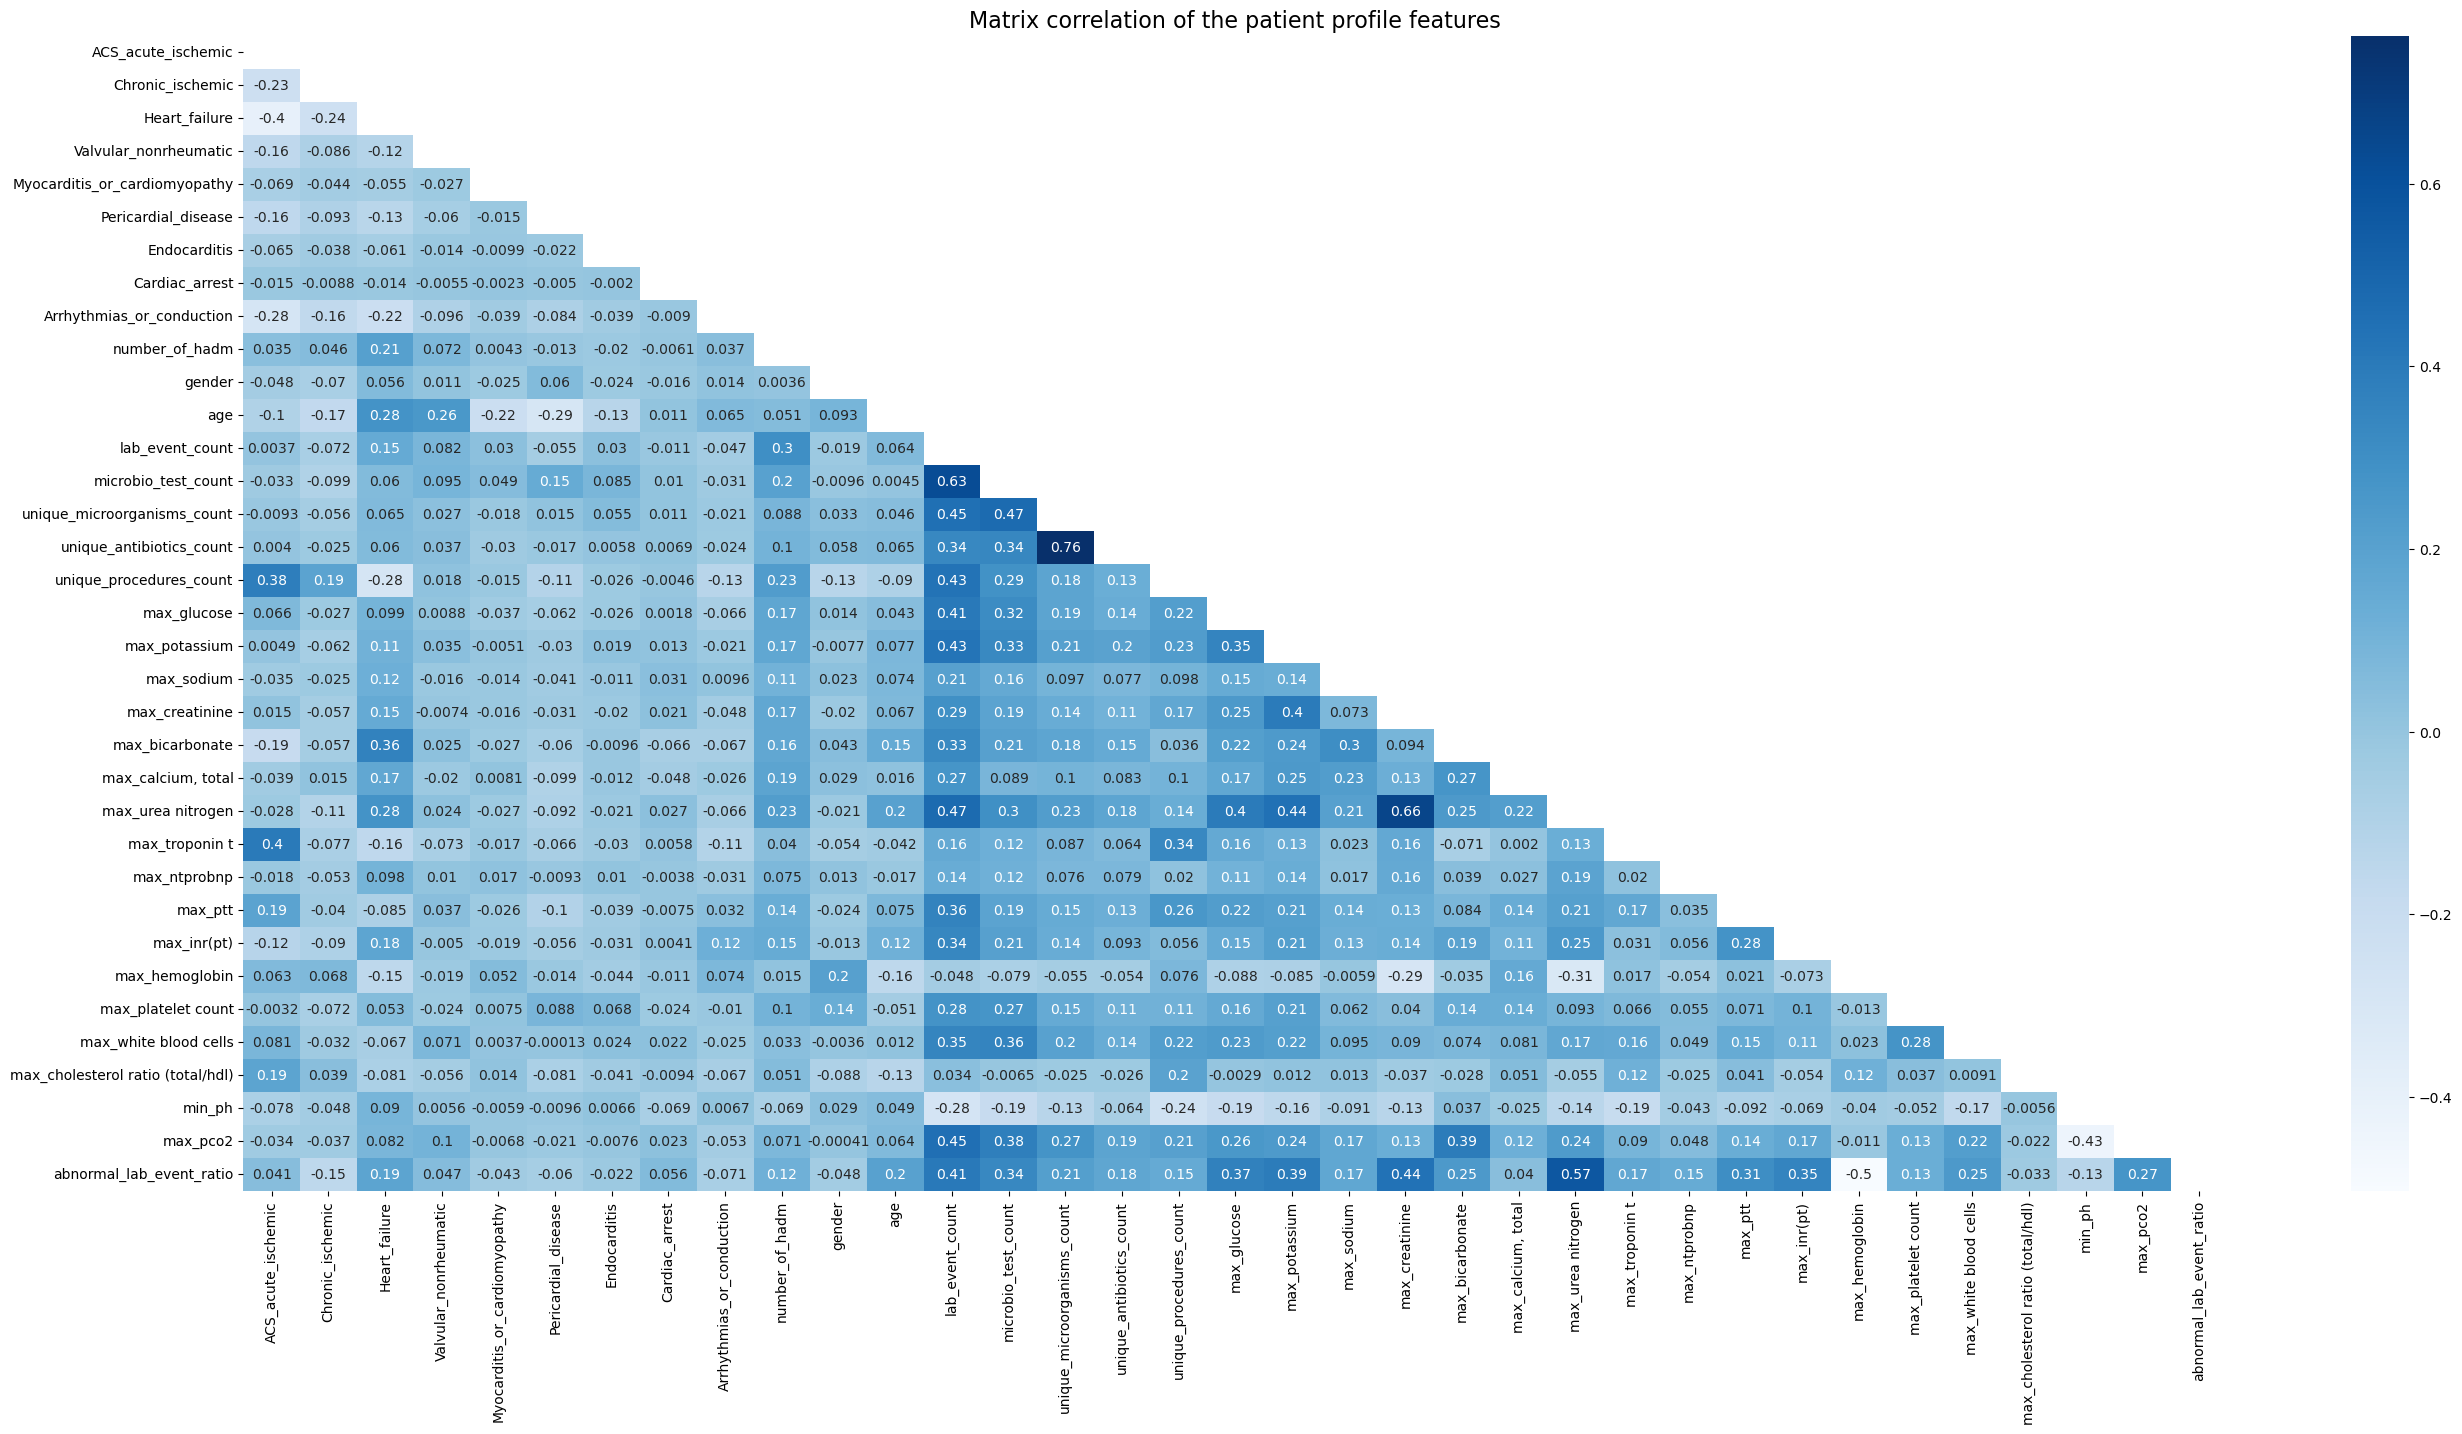

In [32]:
# Correletion

# Select only numeric columns from patient profile
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

corr_matrix = profile_num.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(32,15))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', mask=mask)
plt.title("Matrix correlation of the patient profile features", fontsize=16)
plt.show()

### Visual exploration of the new feature

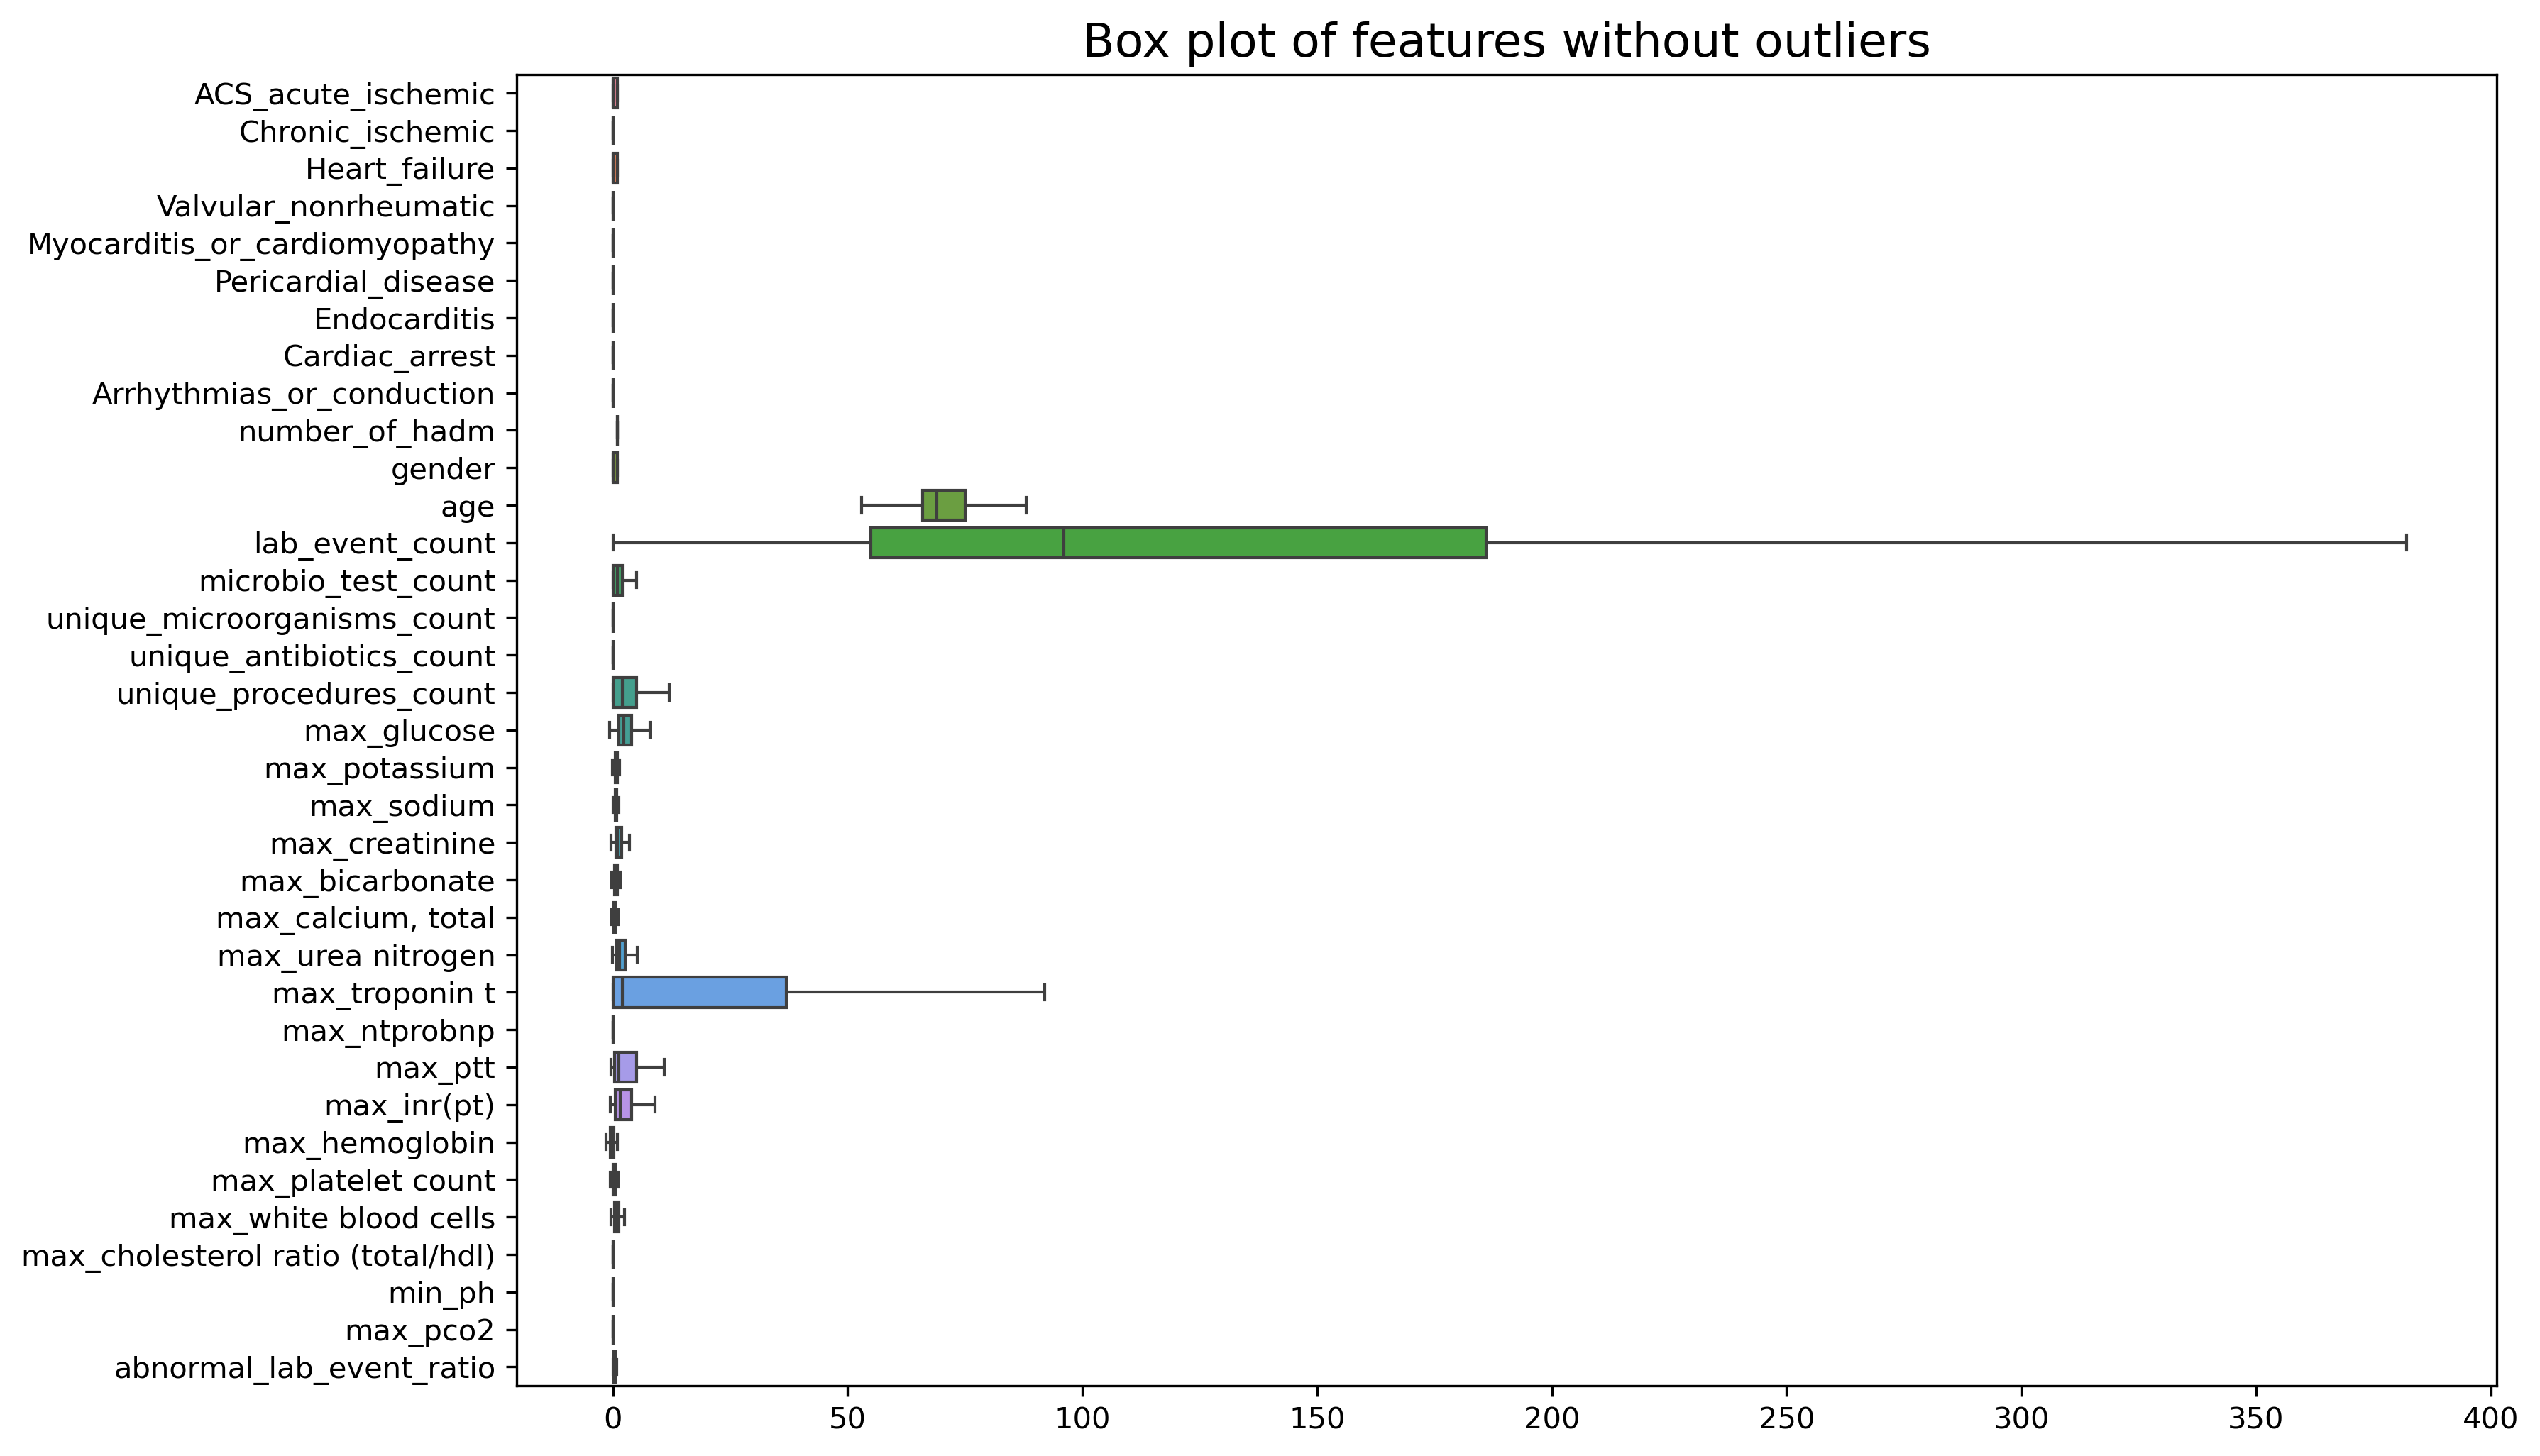

In [33]:
# Boxplot of profile numeric features excluding outliers

plt.figure(figsize=(12,8), dpi=300)
sns.boxplot(data=profile_num, orient="h", showfliers=False)
plt.title("Box plot of features without outliers", fontsize=16)
plt.show()

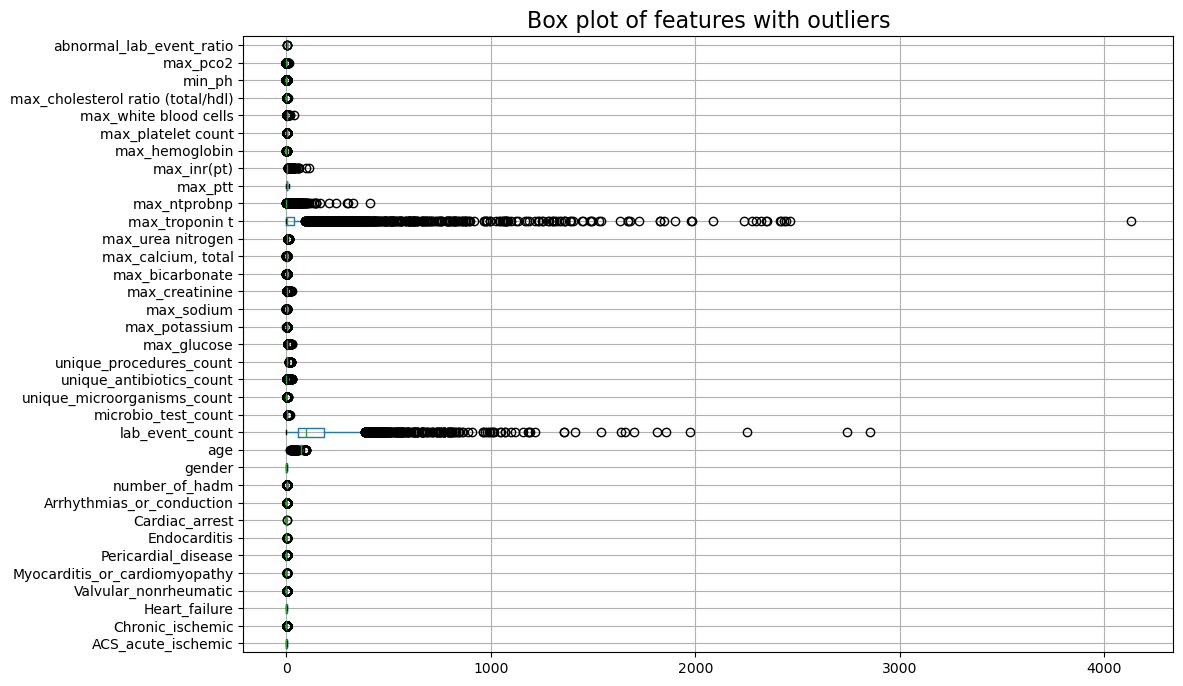

In [34]:
# Boxplot of profile numeric features including outliers

profile_num.boxplot(vert=False, figsize=(12, 8), showfliers=True)
plt.title("Box plot of features with outliers", fontsize=16)
plt.show()

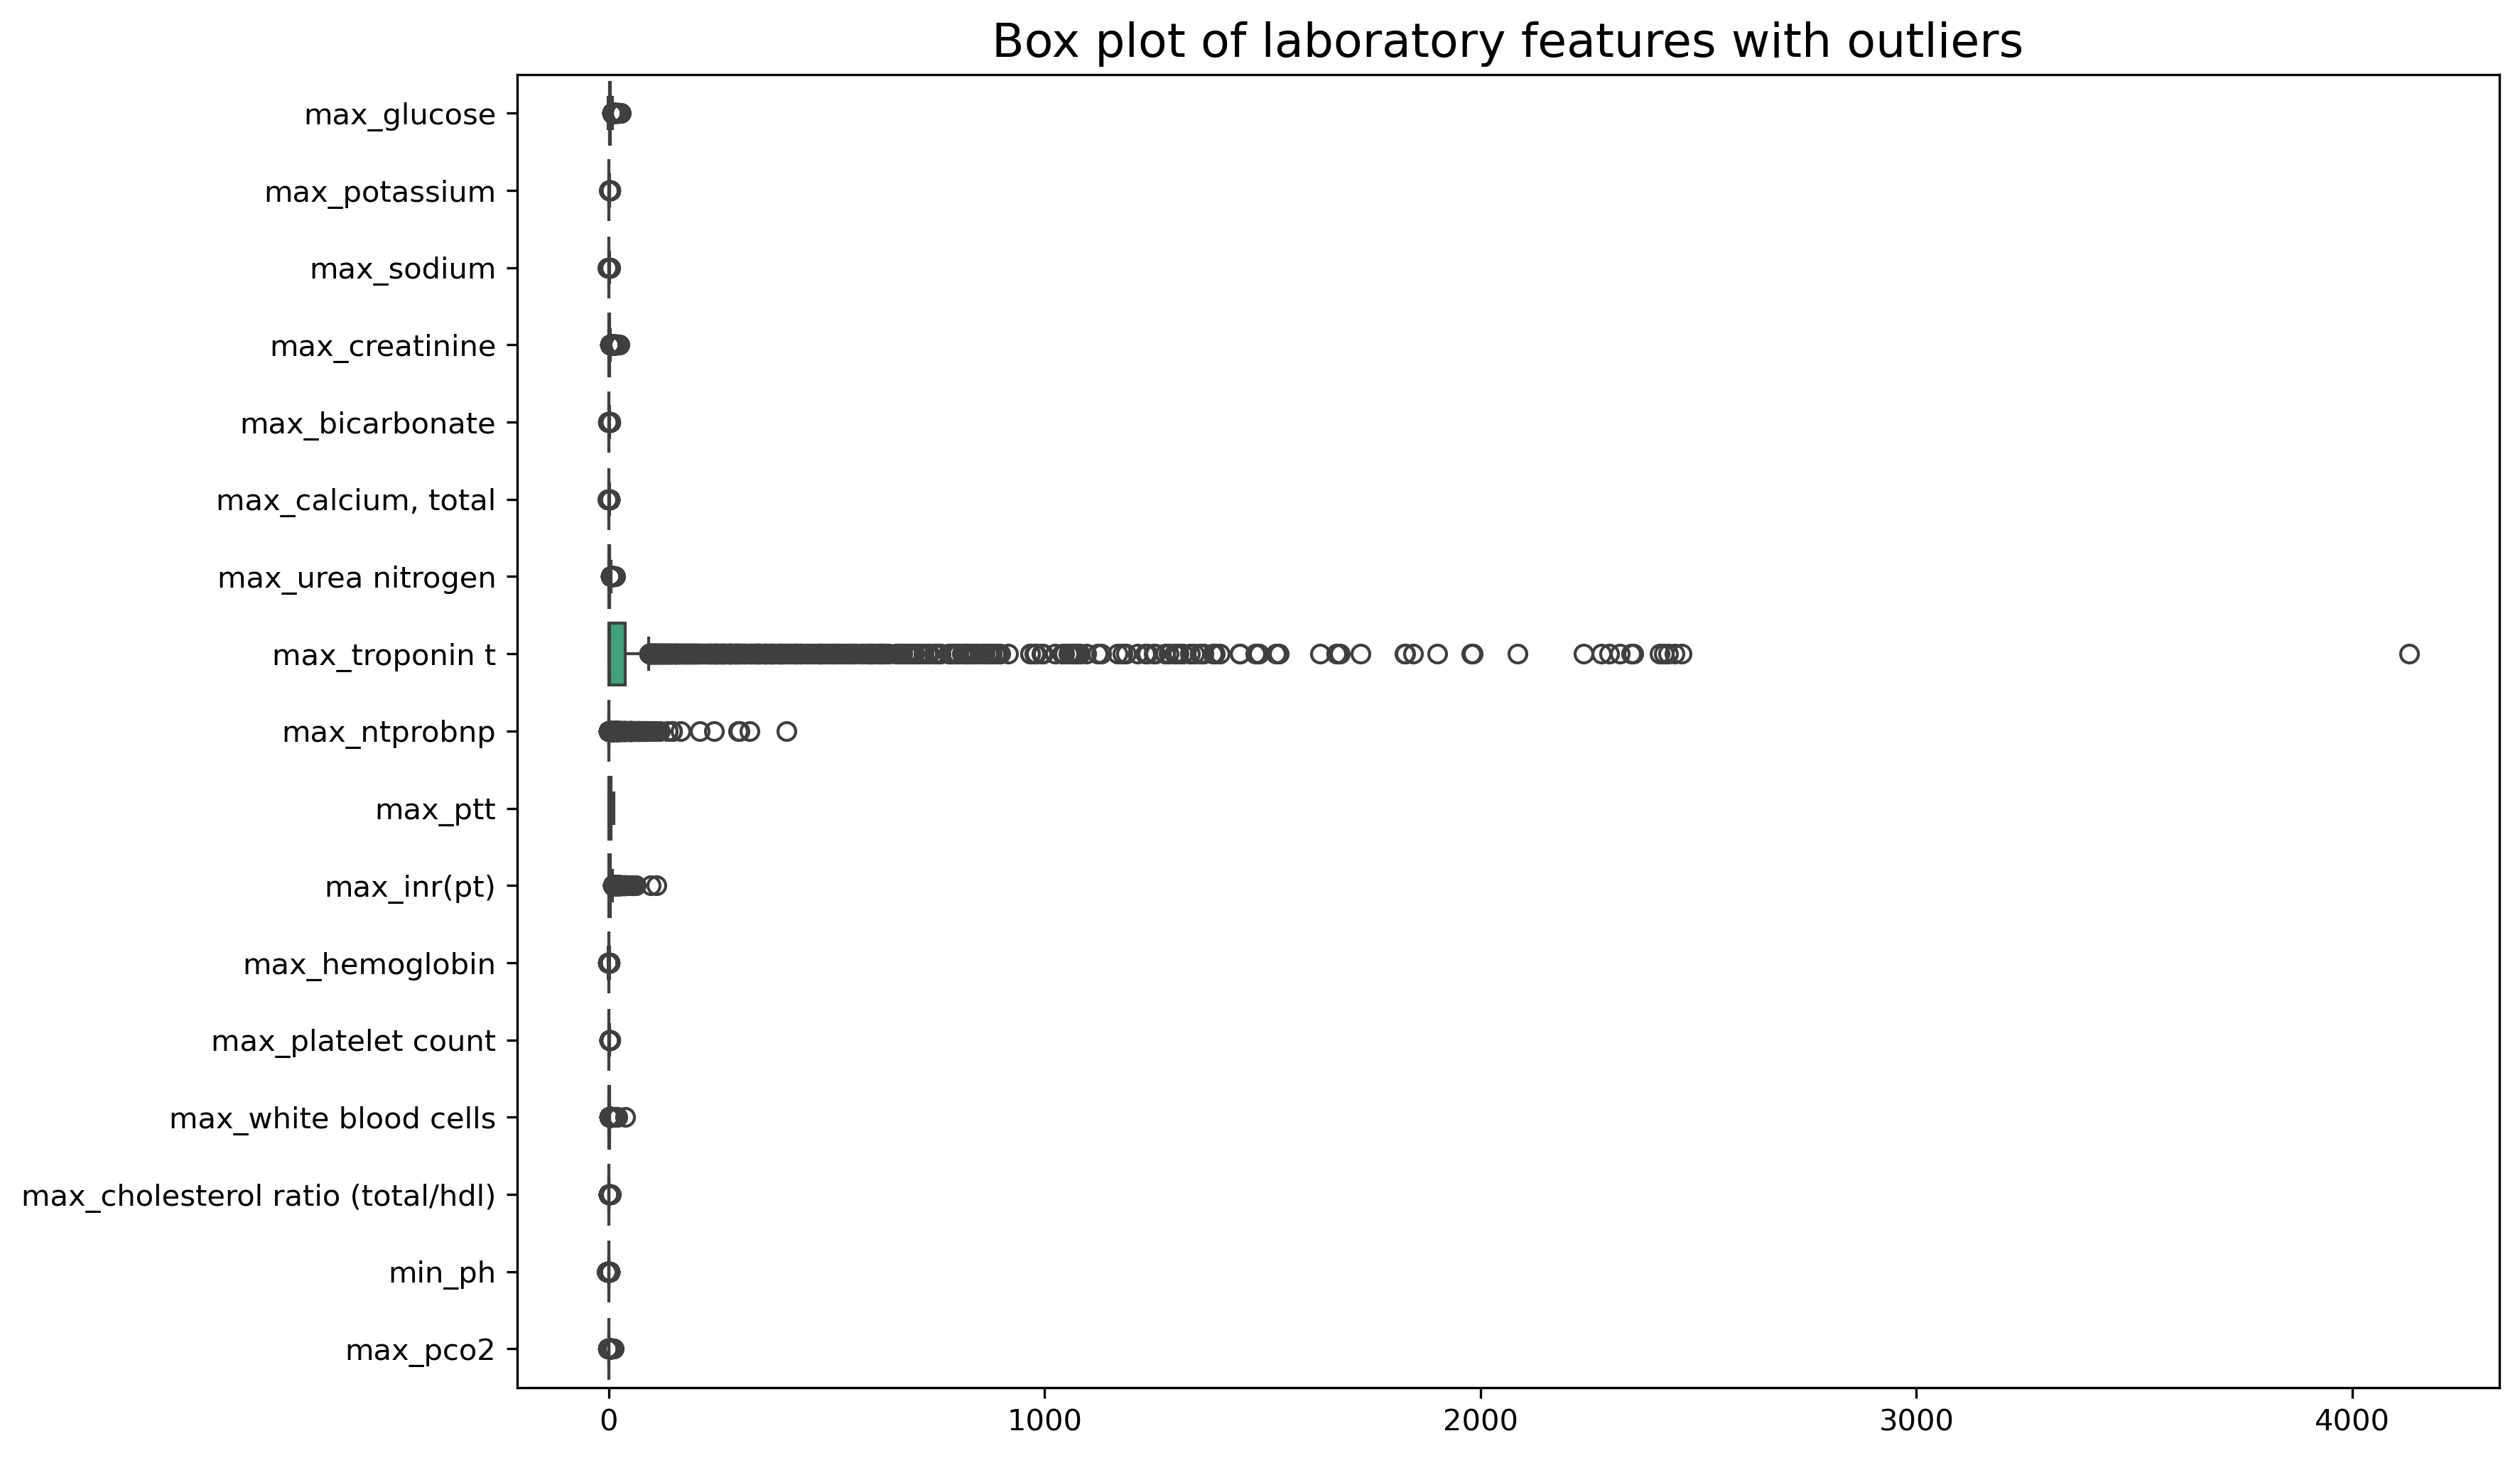

In [35]:
#boxplot of the laboratory features
lab_features = [
    'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine',
    'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen',
    'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)',
    'max_hemoglobin', 'max_platelet count', 'max_white blood cells',
    'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2'
]
plt.figure(figsize=(12,8), dpi=300)
sns.boxplot(data=profile_num[lab_features], orient="h", showfliers=True)
plt.title("Box plot of laboratory features with outliers", fontsize=16)  
plt.show()

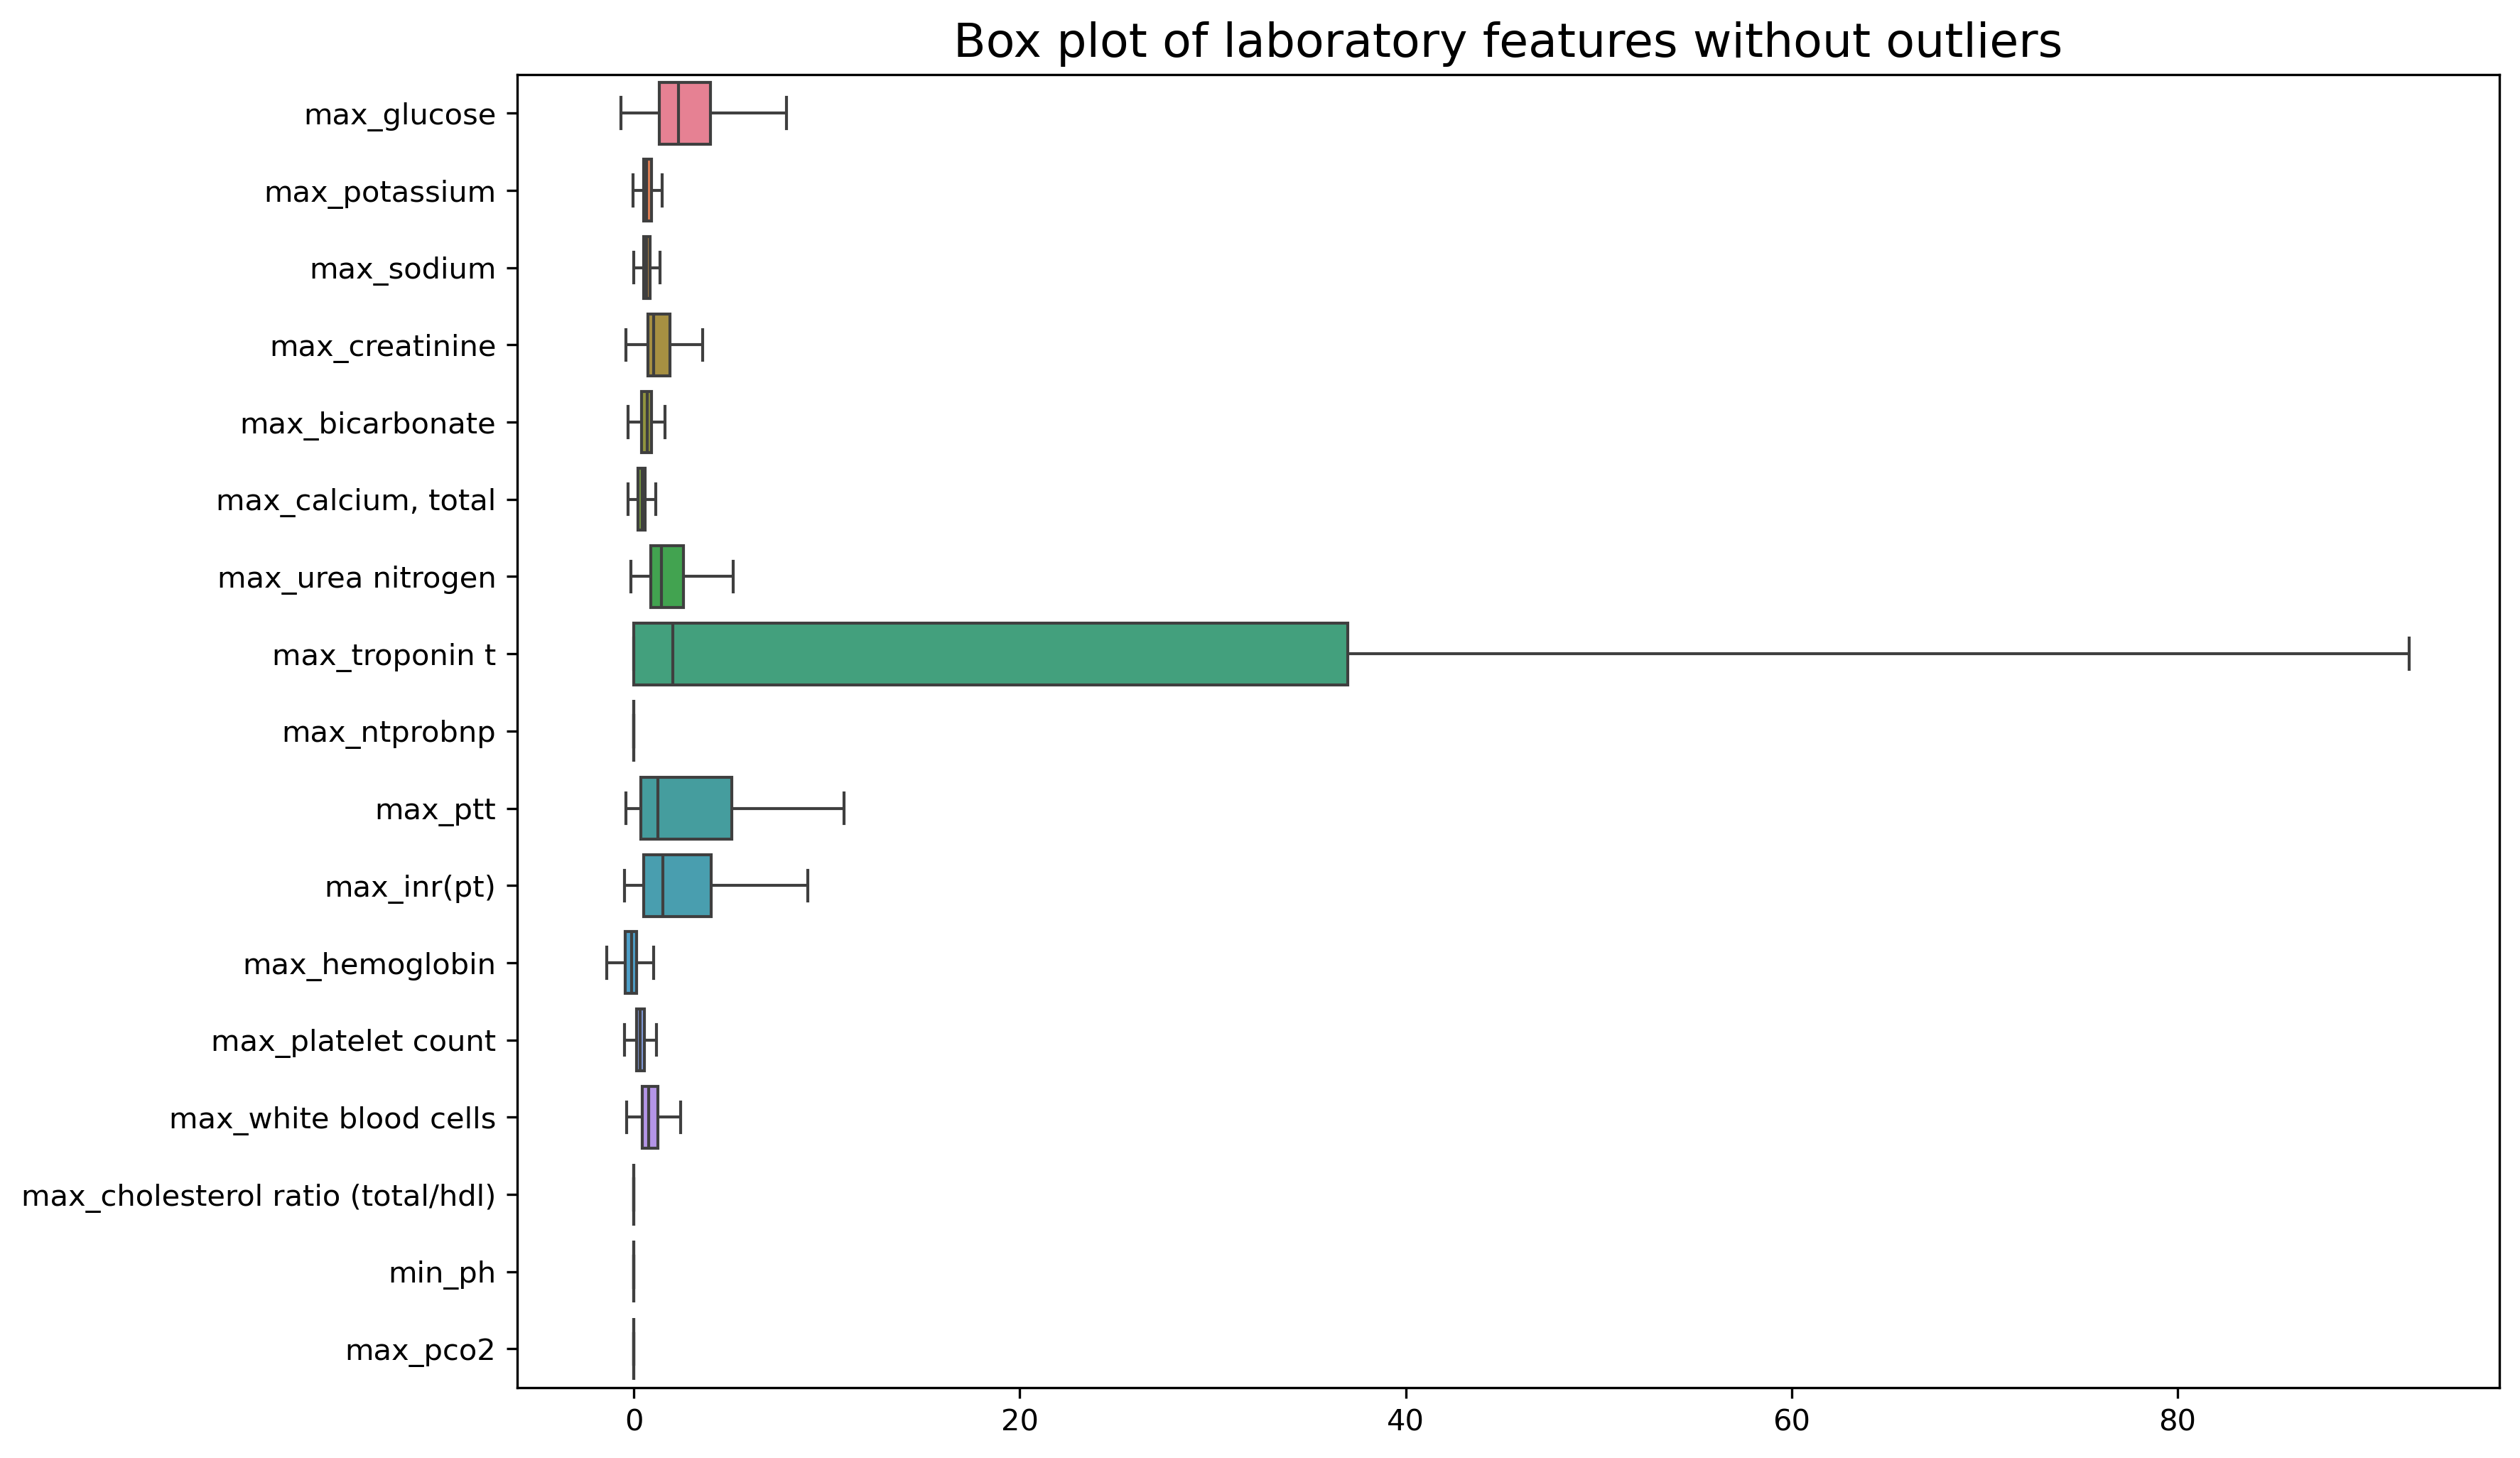

In [36]:
#boxplot of the laboratory features
lab_features = [
    'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine',
    'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen',
    'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)',
    'max_hemoglobin', 'max_platelet count', 'max_white blood cells',
    'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2'
]
plt.figure(figsize=(12,8), dpi=300)
sns.boxplot(data=profile_num[lab_features], orient="h", showfliers=False)
plt.title("Box plot of laboratory features without outliers", fontsize=16)  
plt.show()

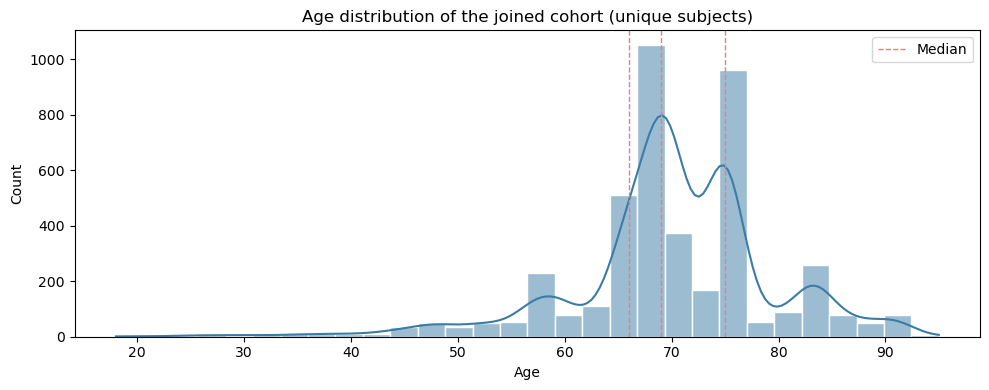

In [37]:
# Age distribution with KDE overlay and highlighted quartiles (unique subjects)

unique_subject_age = (
    profile_df[['subject_id', 'age']]
    .dropna(subset=['age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 4))
sns.histplot(
    data=unique_subject_age,
    x='age',
    bins=30,
    kde=True,
    color='#3A7CA5',
    edgecolor='white'
)
q1, q2, q3 = unique_subject_age['age'].quantile([0.25, 0.5, 0.75])
for q, label in zip([q1, q2, q3], ['Q1', 'Median', 'Q3']):
    plt.axvline(q, color='#E57F84', linestyle='--', linewidth=1, label=label if label == 'Median' else None)
plt.title('Age distribution of the joined cohort (unique subjects)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(loc='upper right')
plt.tight_layout()

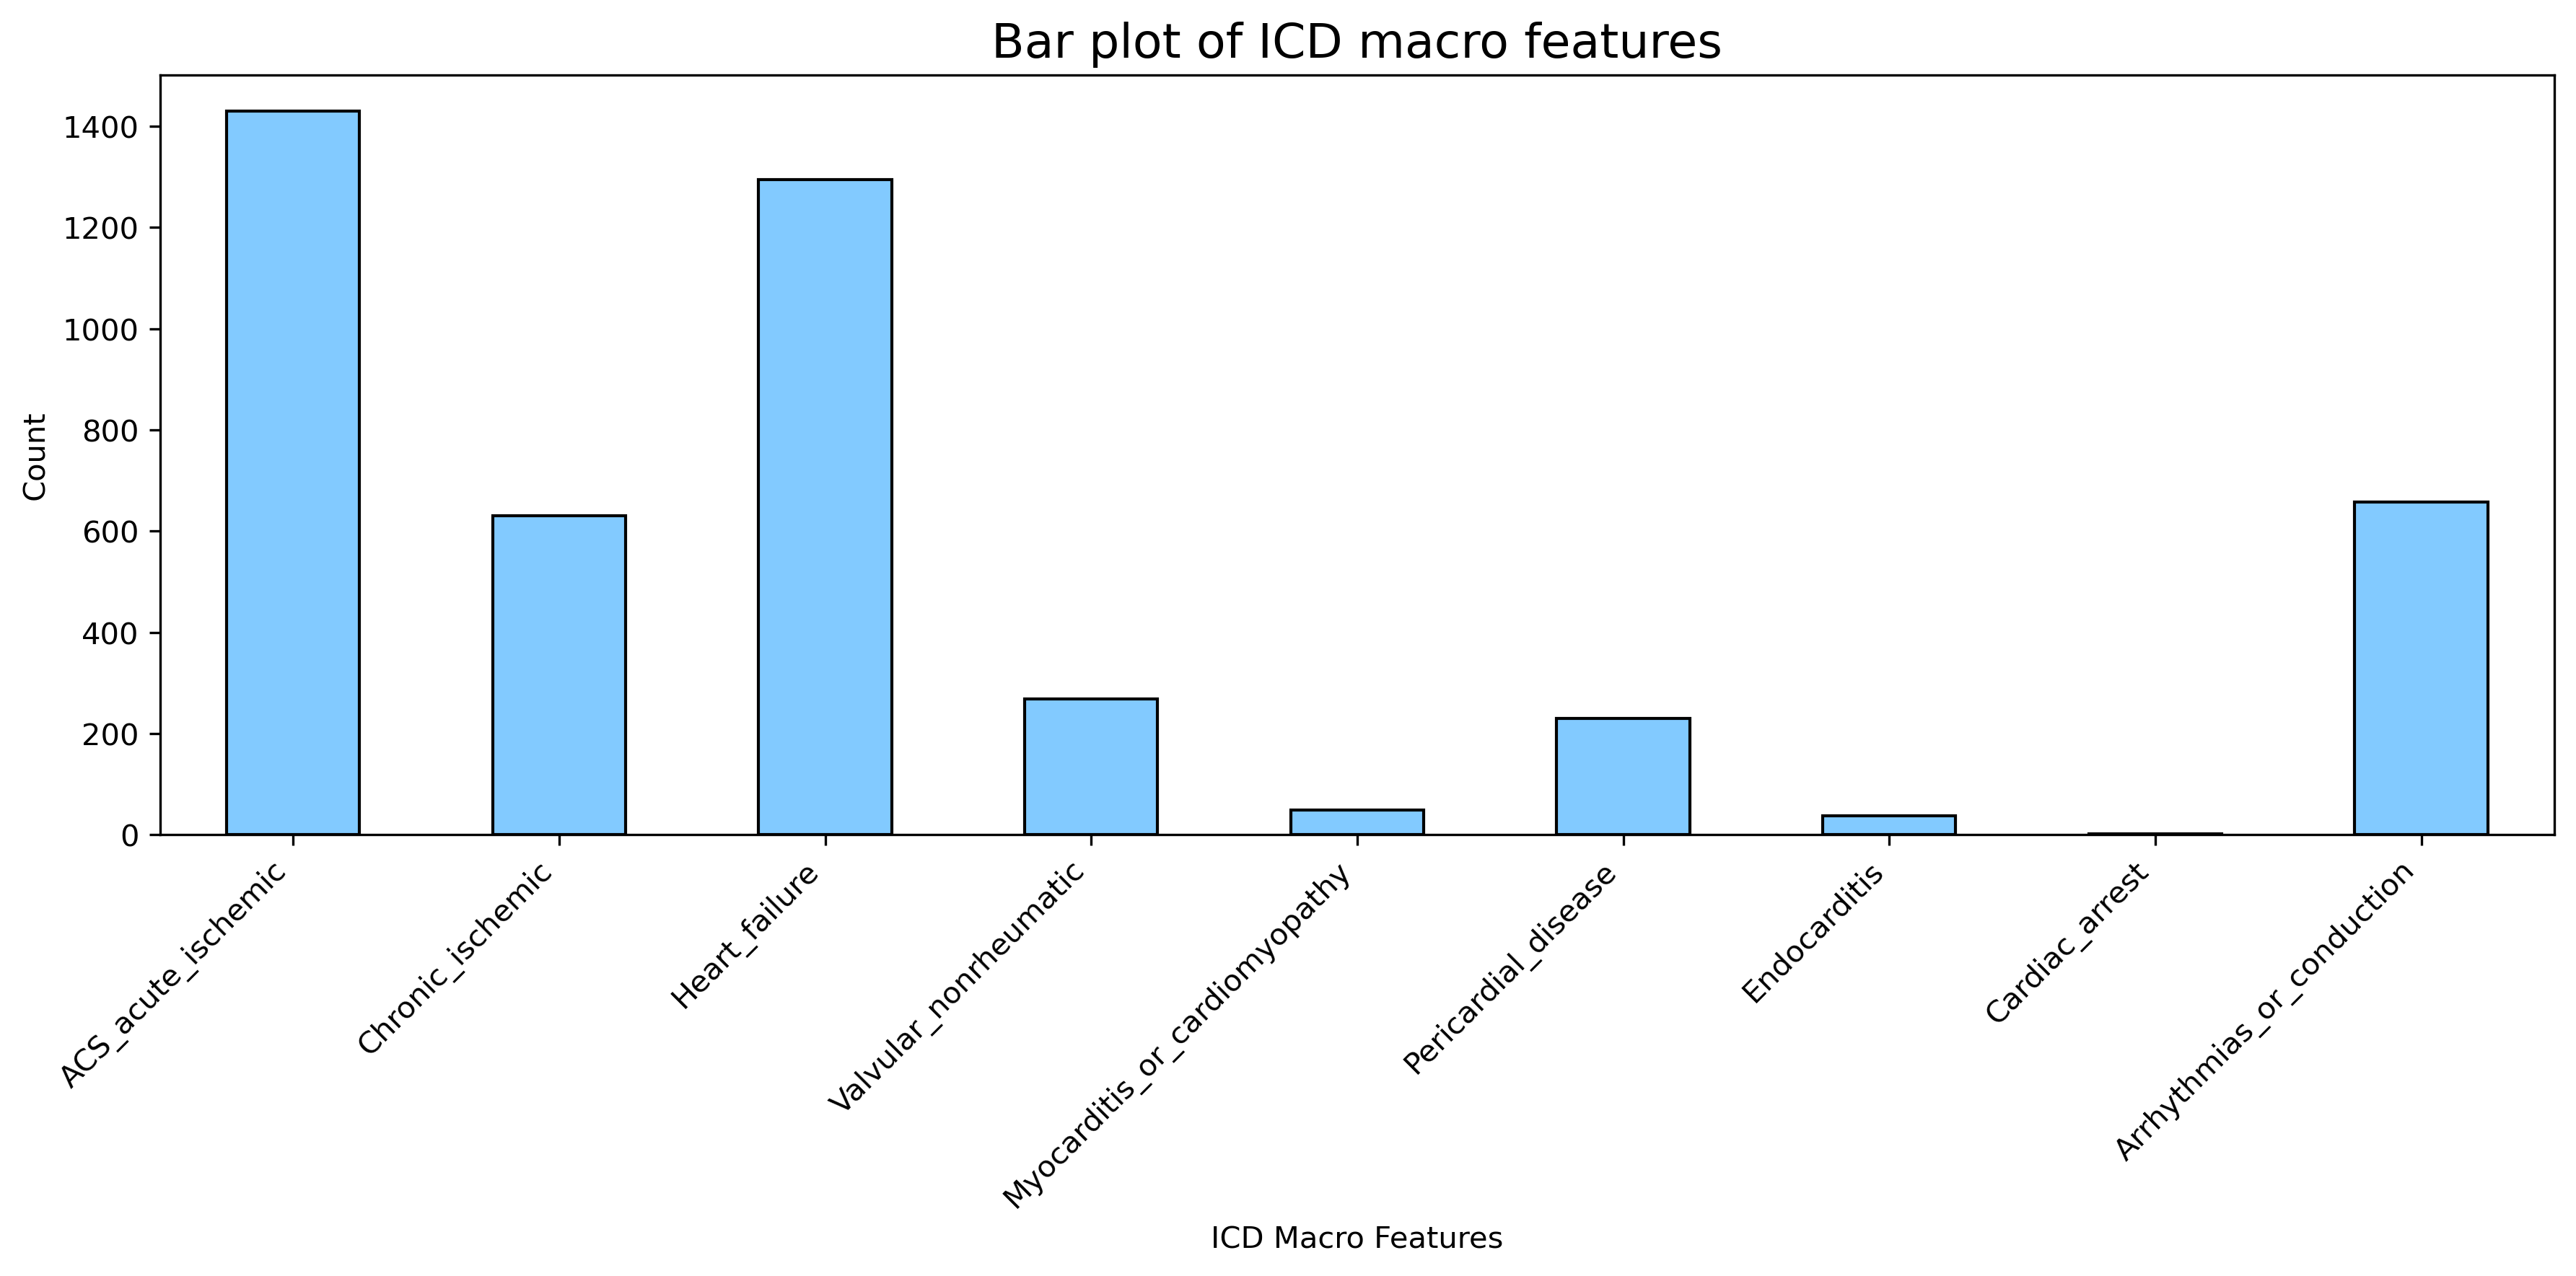

In [38]:
# Barplot of the icd macro features 
icd_macro_cols = ICD_MACRO_COLS
profile_icd_macro = profile_df[icd_macro_cols]
plt.figure(figsize=(12,6), dpi=300)
profile_icd_macro.sum().plot(kind='bar', color="#82caff", edgecolor="black")
plt.title("Bar plot of ICD macro features", fontsize=16)
plt.ylabel("Count")
plt.xlabel("ICD Macro Features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

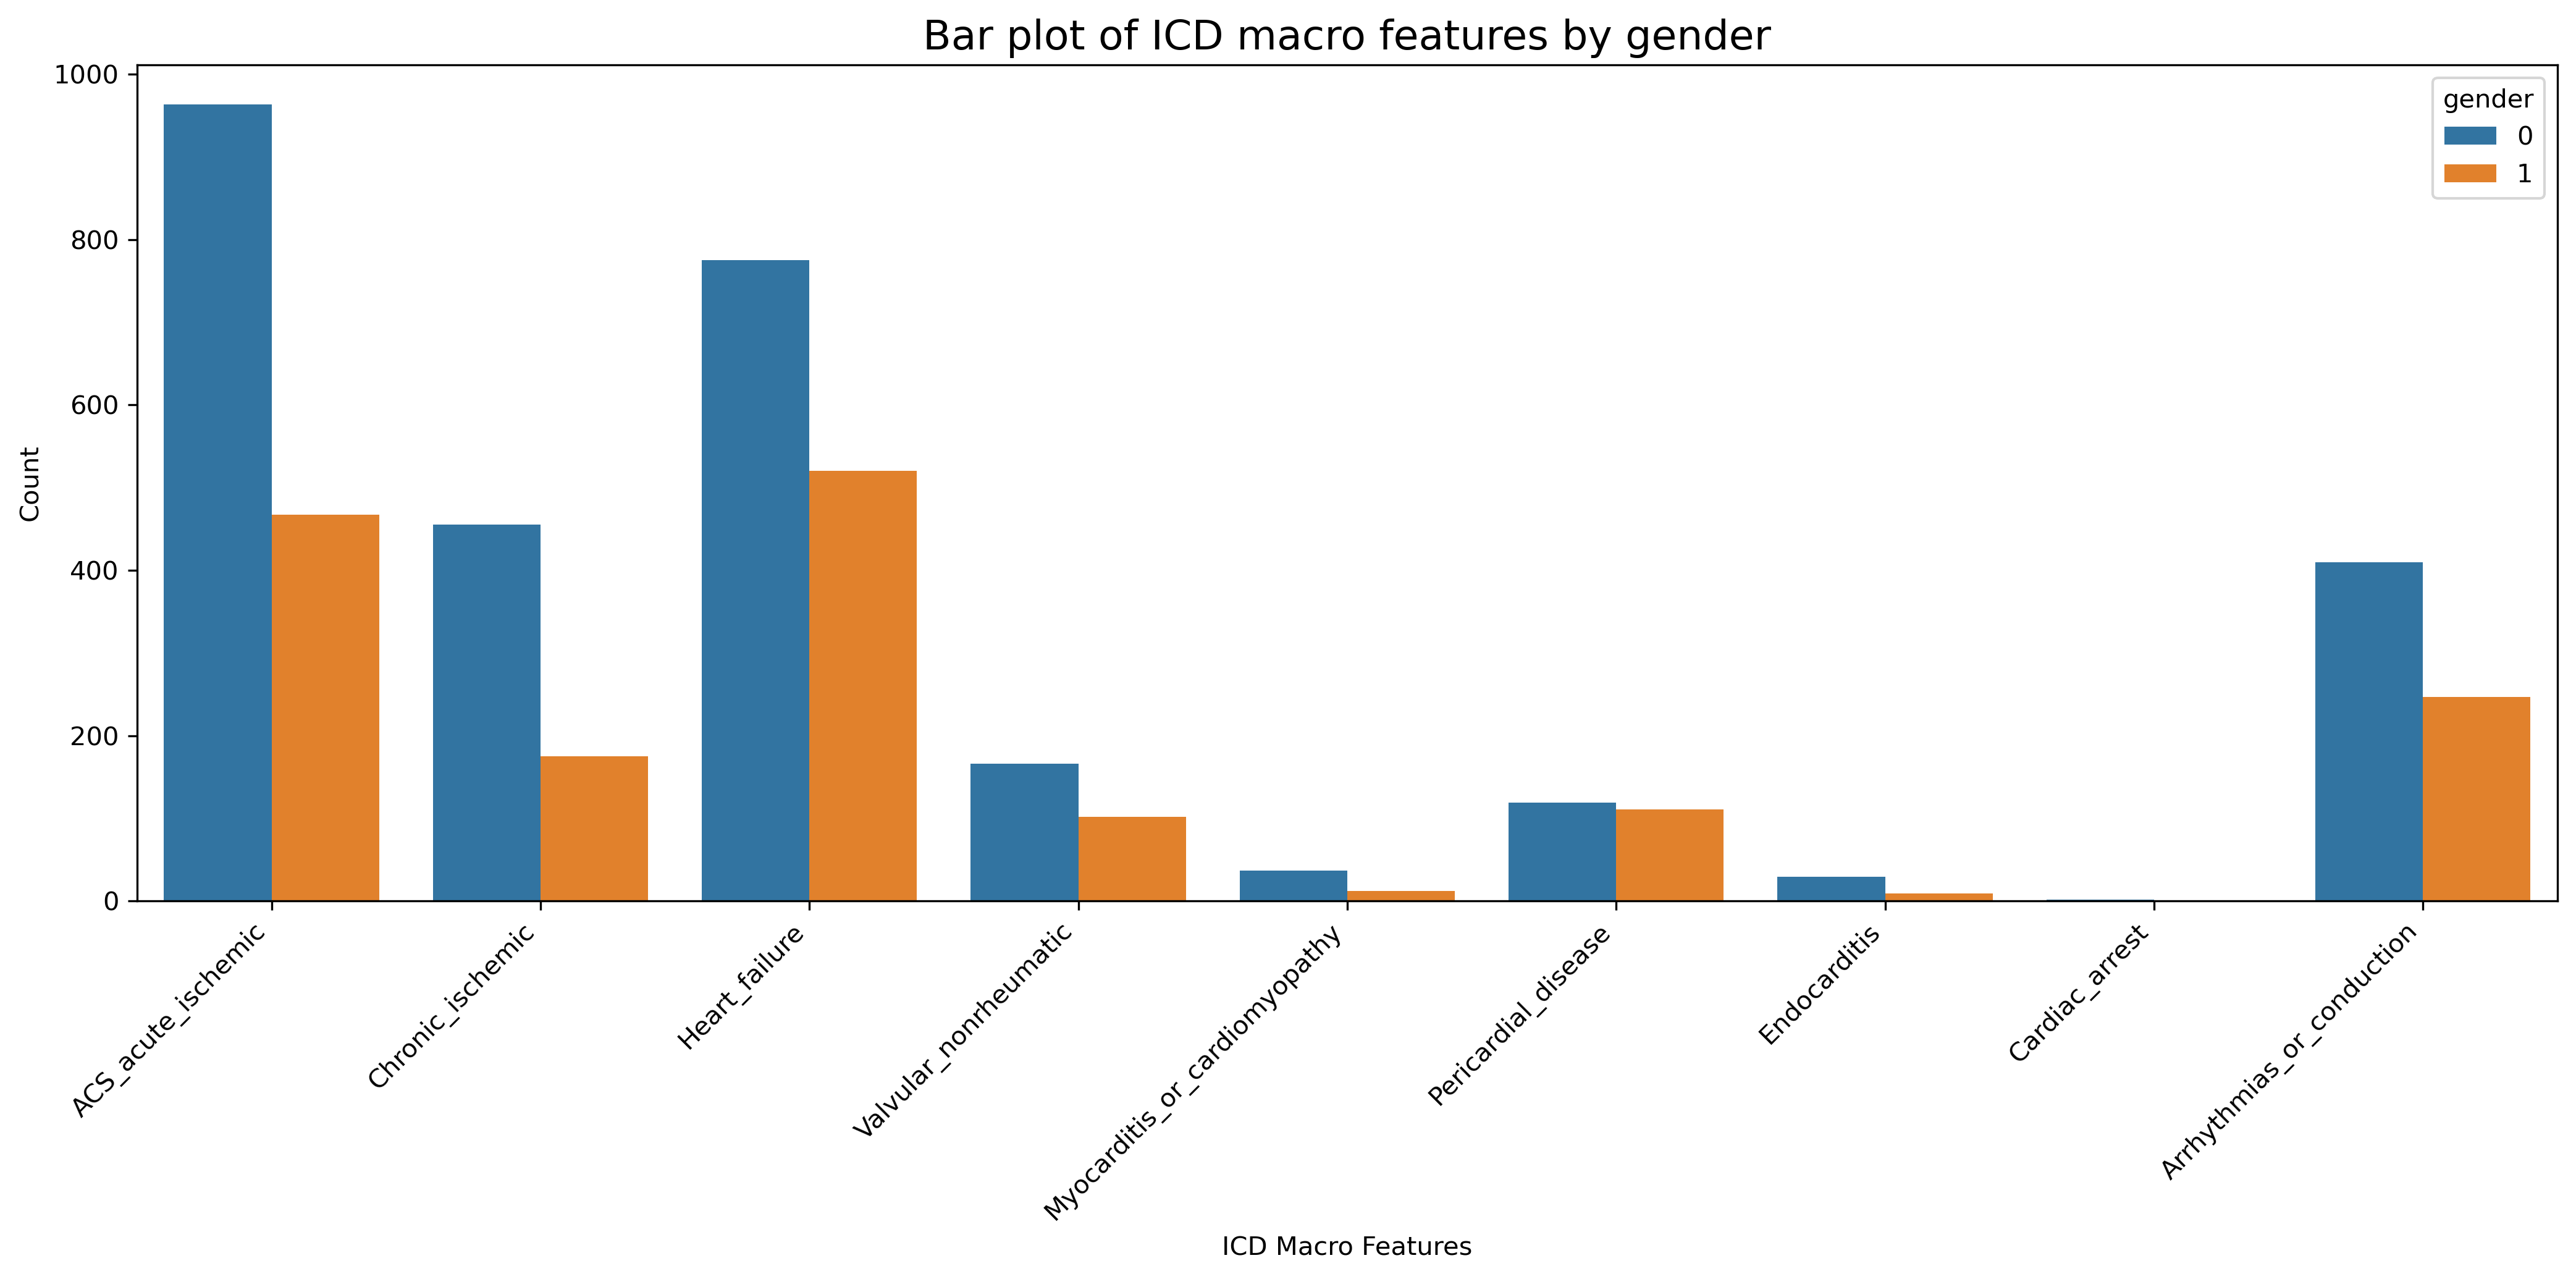

In [39]:
# Barplot of the gender per macro icd features
gender_icd = profile_df[['gender'] + ICD_MACRO_COLS]
gender_icd_grouped = gender_icd.groupby('gender').sum().reset_index()   
gender_icd_grouped_melted = gender_icd_grouped.melt(id_vars='gender', var_name='ICD_Macro_Feature', value_name='Count')
plt.figure(figsize=(14,7), dpi=300)
sns.barplot(data=gender_icd_grouped_melted, x='ICD_Macro_Feature', y='Count', hue='gender')
plt.title("Bar plot of ICD macro features by gender", fontsize=16)
plt.ylabel("Count")
plt.xlabel("ICD Macro Features")
plt.xticks(rotation=45, ha="right") 
plt.tight_layout()
plt.show()

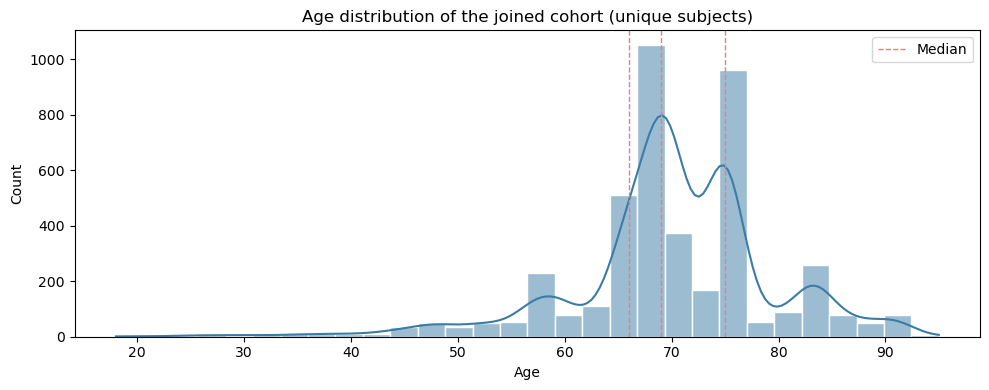

In [40]:
# Age distribution with KDE overlay and highlighted quartiles (unique subjects)

unique_subject_age = (
    joined_df[['subject_id', 'age']]
    .dropna(subset=['age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 4))
sns.histplot(
    data=unique_subject_age,
    x='age',
    bins=30,
    kde=True,
    color='#3A7CA5',
    edgecolor='white'
)
q1, q2, q3 = unique_subject_age['age'].quantile([0.25, 0.5, 0.75])
for q, label in zip([q1, q2, q3], ['Q1', 'Median', 'Q3']):
    plt.axvline(q, color='#E57F84', linestyle='--', linewidth=1, label=label if label == 'Median' else None)
plt.title('Age distribution of the joined cohort (unique subjects)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(loc='upper right')
plt.tight_layout()

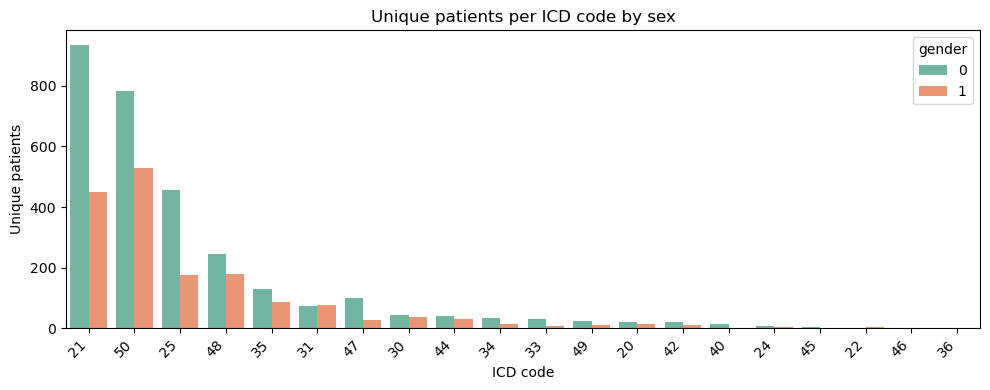

In [41]:
# Barplot of unique patients per ICD code split by gender

counts = (
    joined_df.groupby(['icd_code_joined', 'gender'])['subject_id']
    .nunique()
    .reset_index(name='unique_patients')
)

icd_order = (
    counts.groupby('icd_code_joined')['unique_patients']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=counts,
    x='icd_code_joined',
    y='unique_patients',
    hue='gender',
    palette='Set2',
    order=icd_order
)
plt.title('Unique patients per ICD code by sex')
plt.xlabel('ICD code')
plt.ylabel('Unique patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

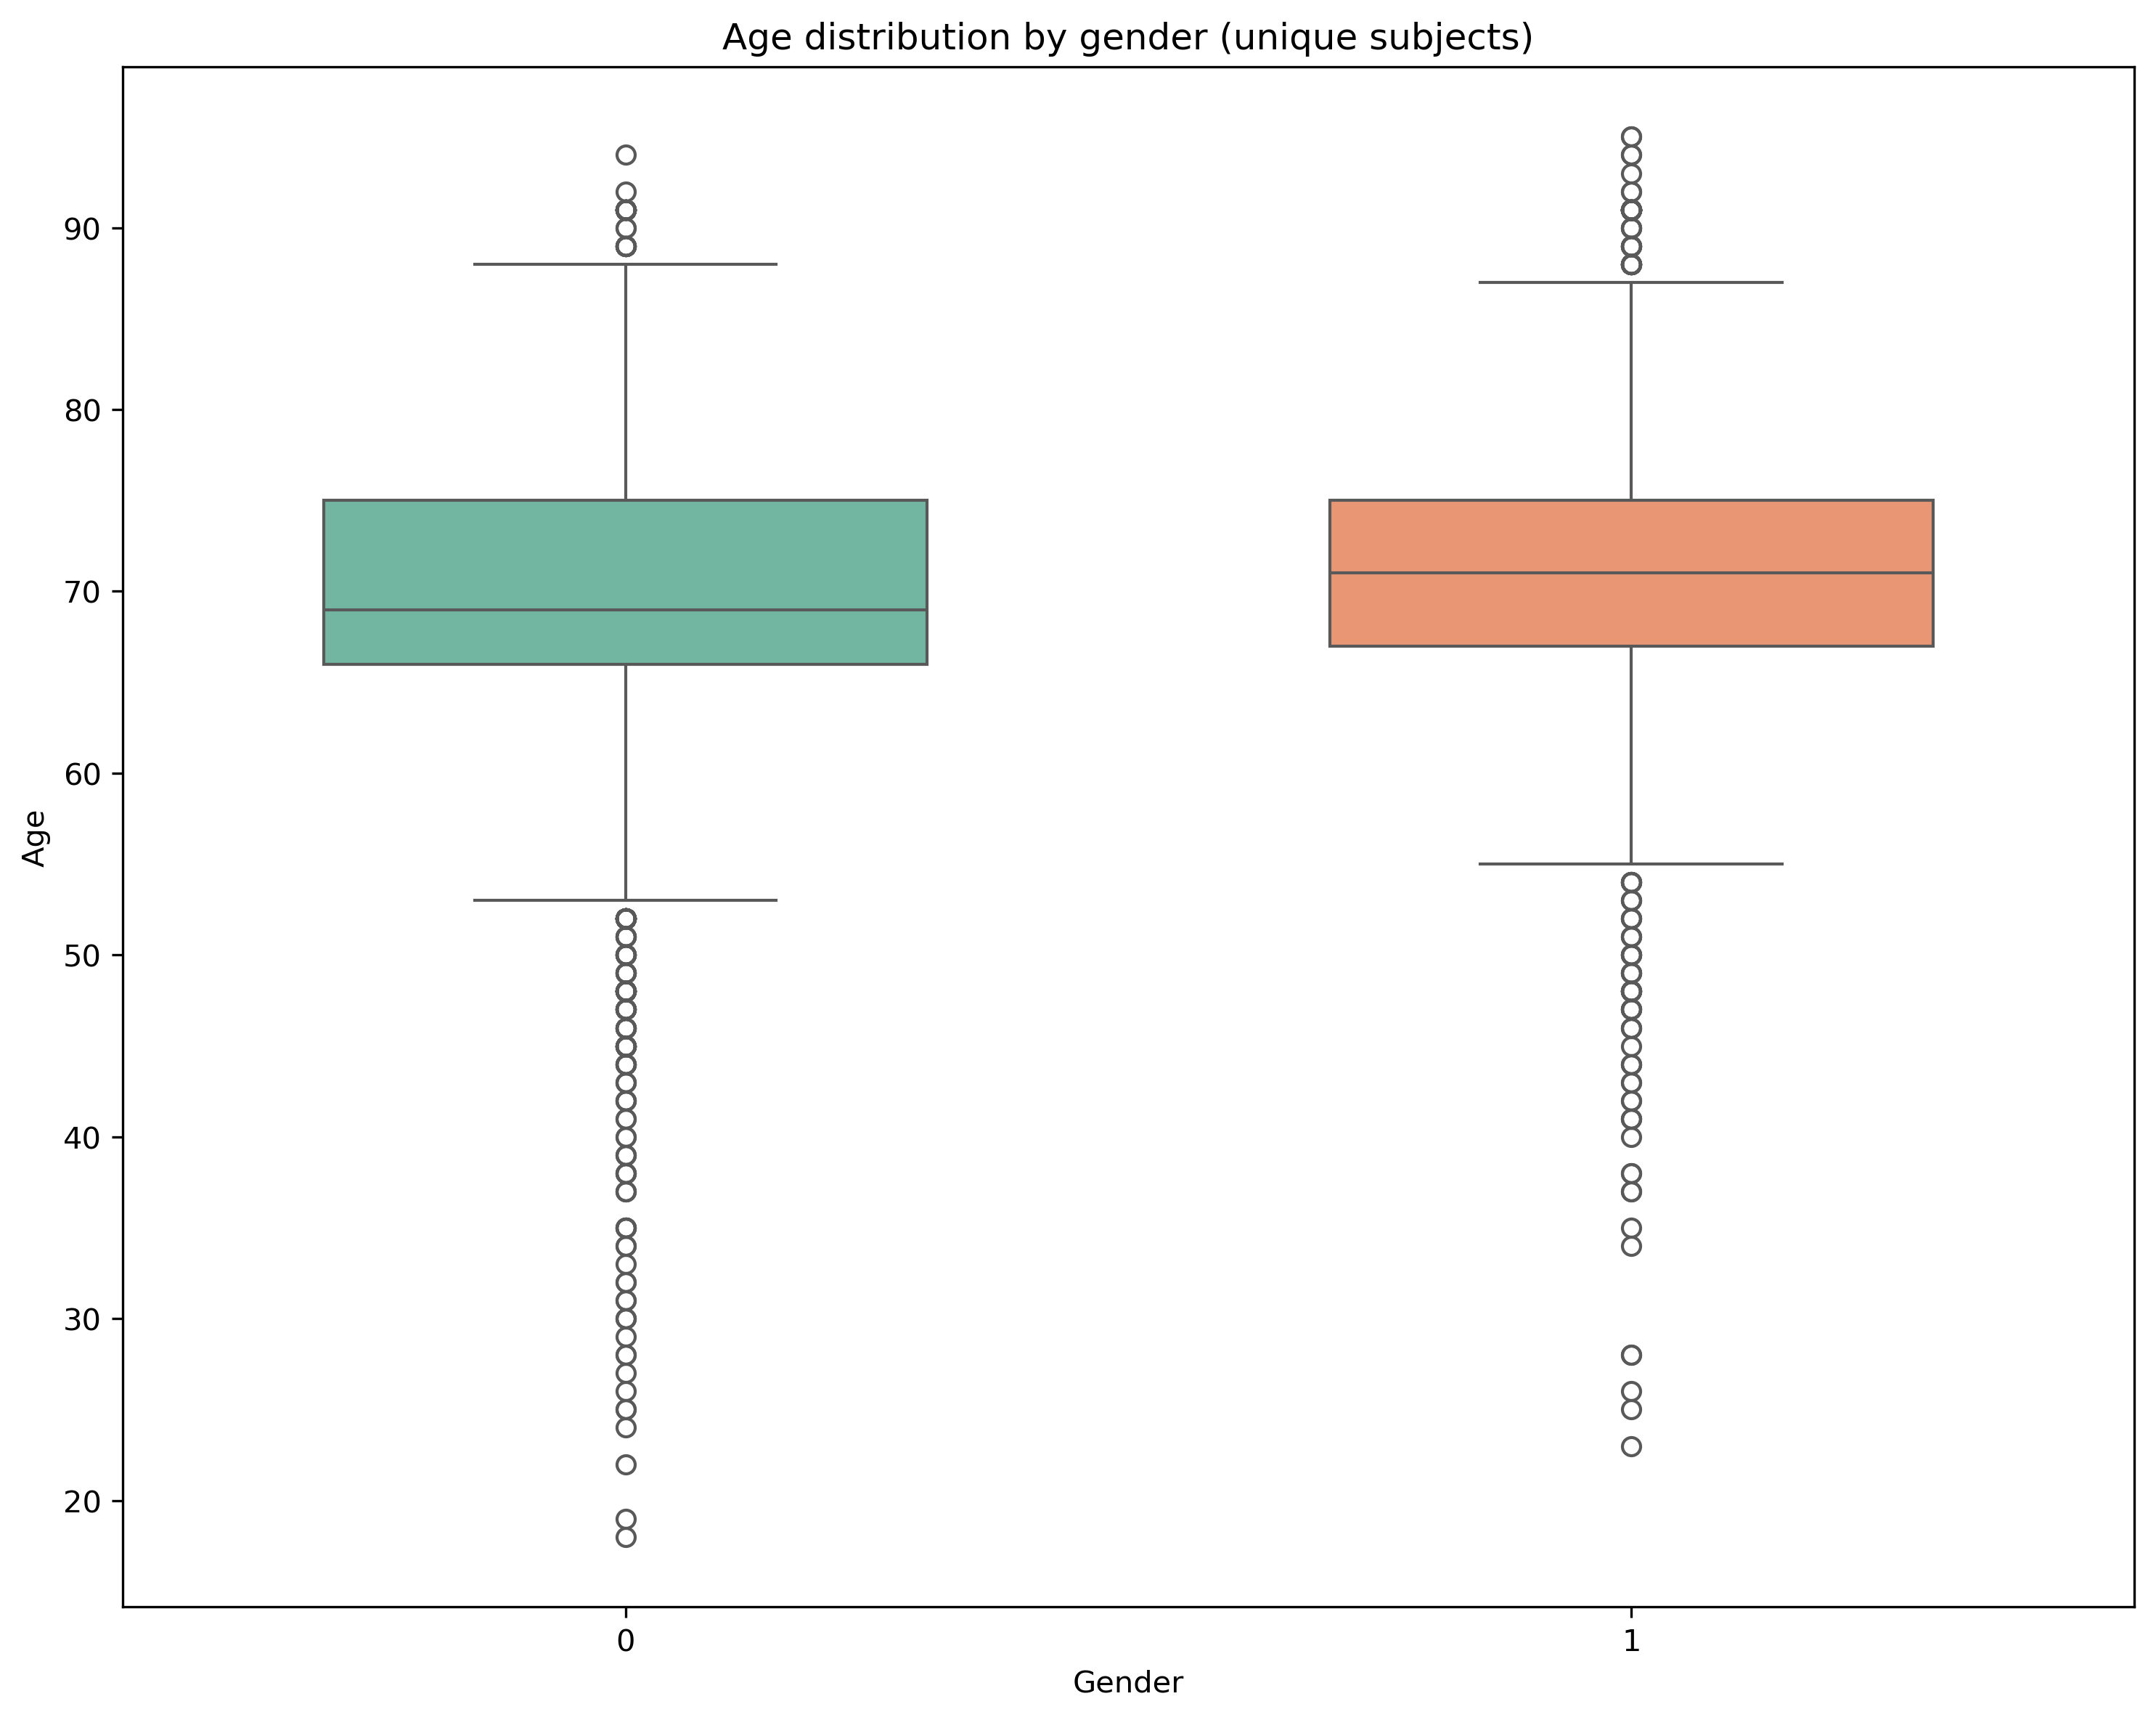

In [42]:
# Boxplot of age distribution by gender (unique subjects)

subject_age = (
    joined_df[['subject_id', 'gender', 'age']]
    .dropna(subset=['gender', 'age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=subject_age,
    x='gender',
    y='age',
    hue='gender',
    palette='Set2',
    width=0.6,
    dodge=False,
    legend=False
)
plt.title('Age distribution by gender (unique subjects)')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.tight_layout()

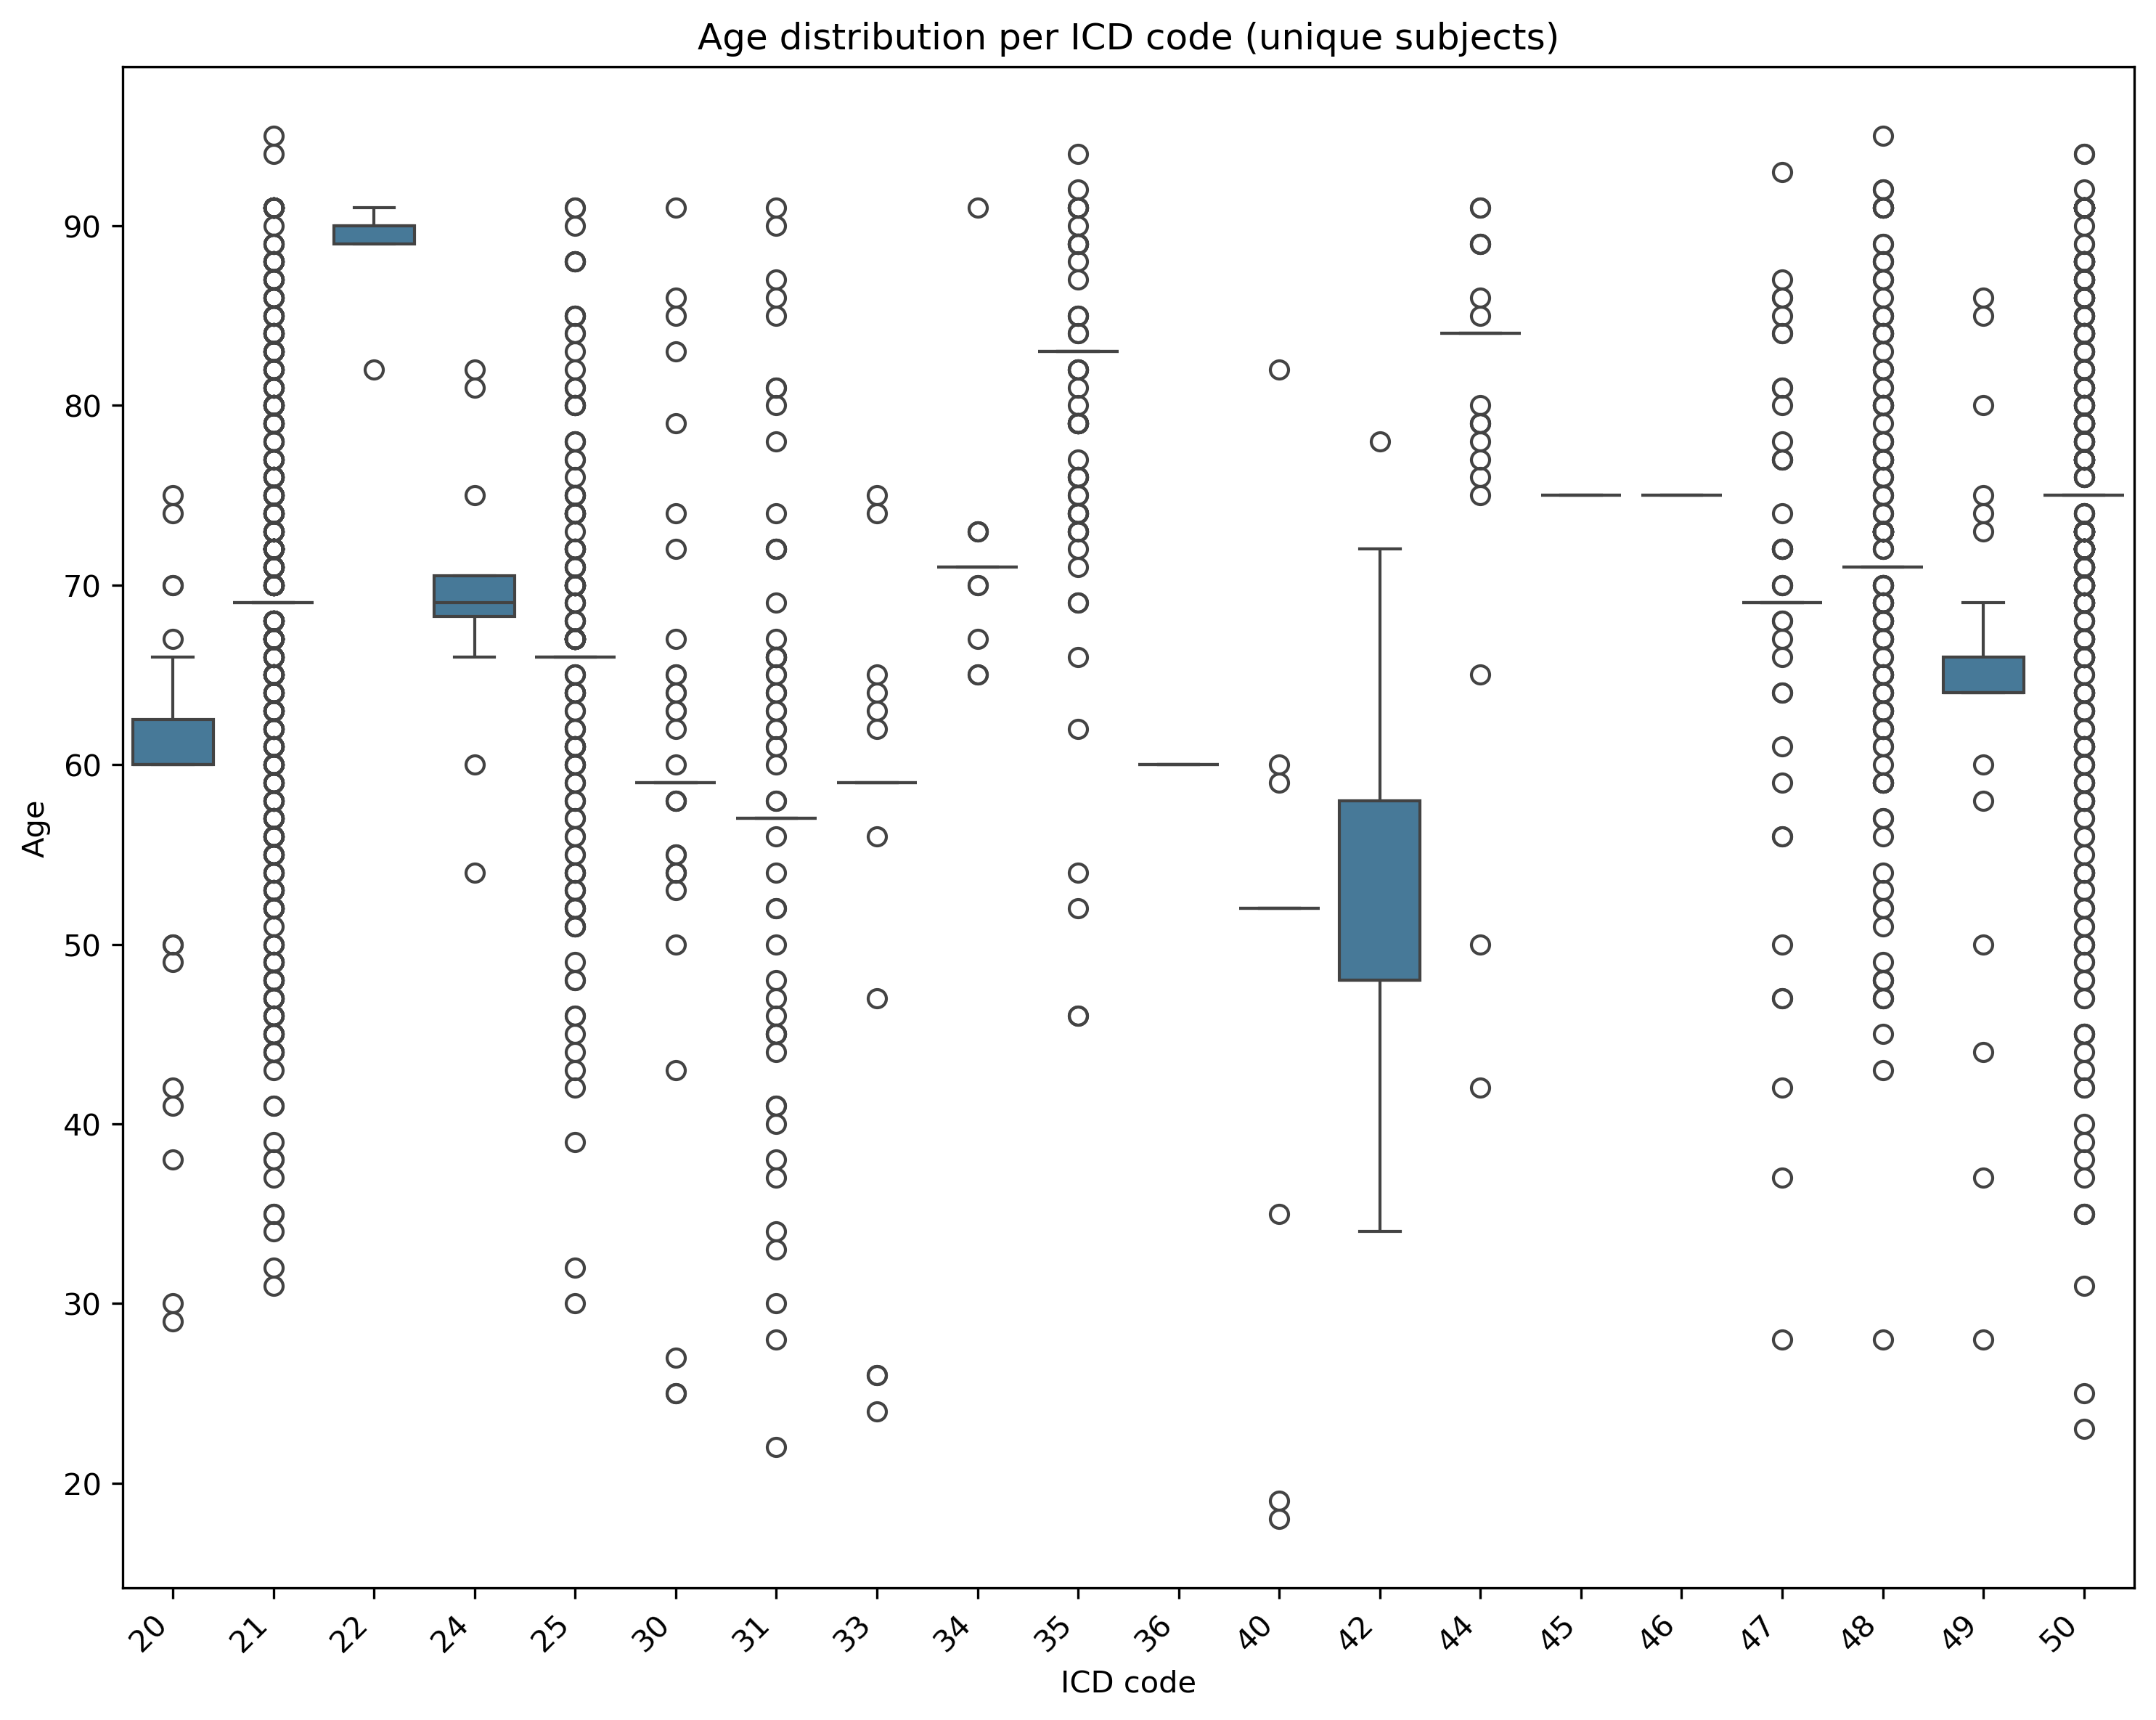

In [43]:
# Visualize for each icd_code the age of the patient 

icd_age = (
    joined_df[['subject_id', 'icd_code_joined', 'age']]
    .dropna(subset=['icd_code_joined', 'age'])
    .drop_duplicates(subset=['subject_id', 'icd_code_joined'])
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    color='#3A7CA5'
)
plt.title('Age distribution per ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

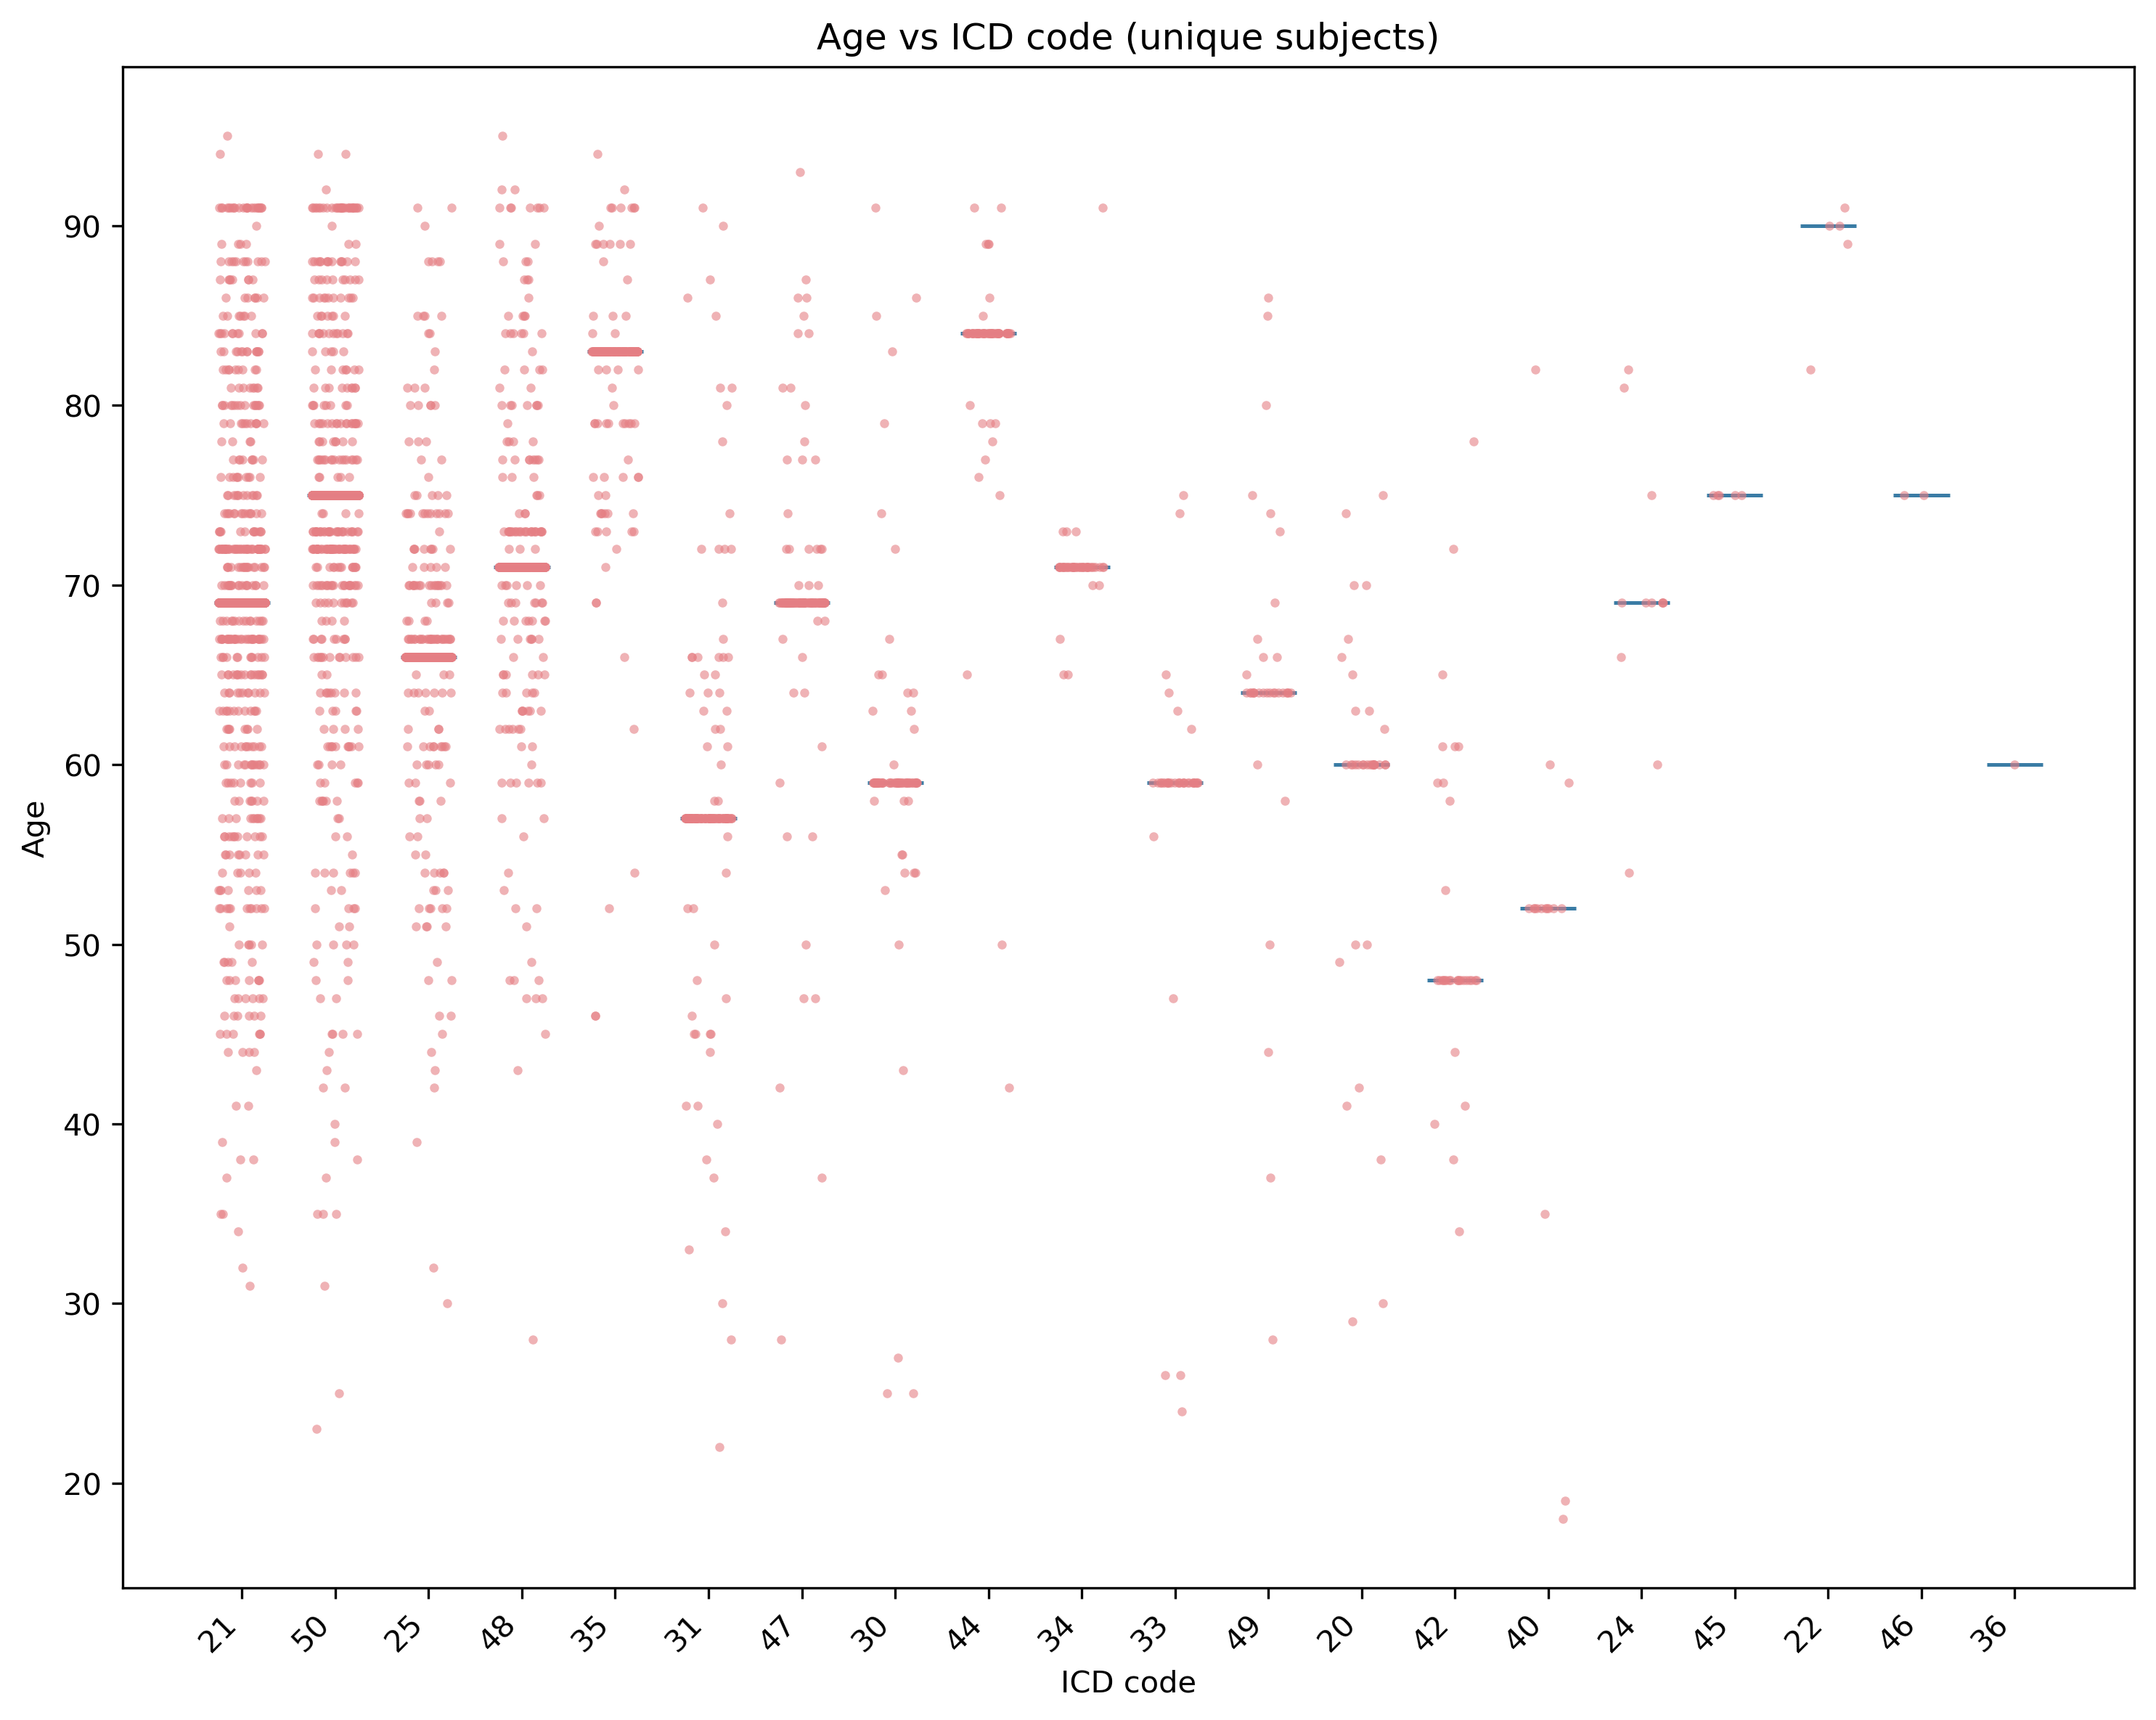

In [44]:
# Stripplot of ages per ICD code with median lines

icd_order = (
    icd_age.groupby('icd_code_joined')['subject_id']
    .nunique()
    .sort_values(ascending=False)
    .index
)

median_age_by_icd = (
    icd_age.groupby('icd_code_joined')['age']
    .median()
    .reindex(icd_order)
)

plt.figure(figsize=(10, 8), dpi=300)
sns.stripplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    order=icd_order,
    color='#E57F84',
    jitter=0.25,
    size=3,
    alpha=0.6
)

for idx, age in enumerate(median_age_by_icd):
    plt.hlines(age, idx - 0.3, idx + 0.3, color='#3A7CA5', linewidth=1.2)

plt.title('Age vs ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

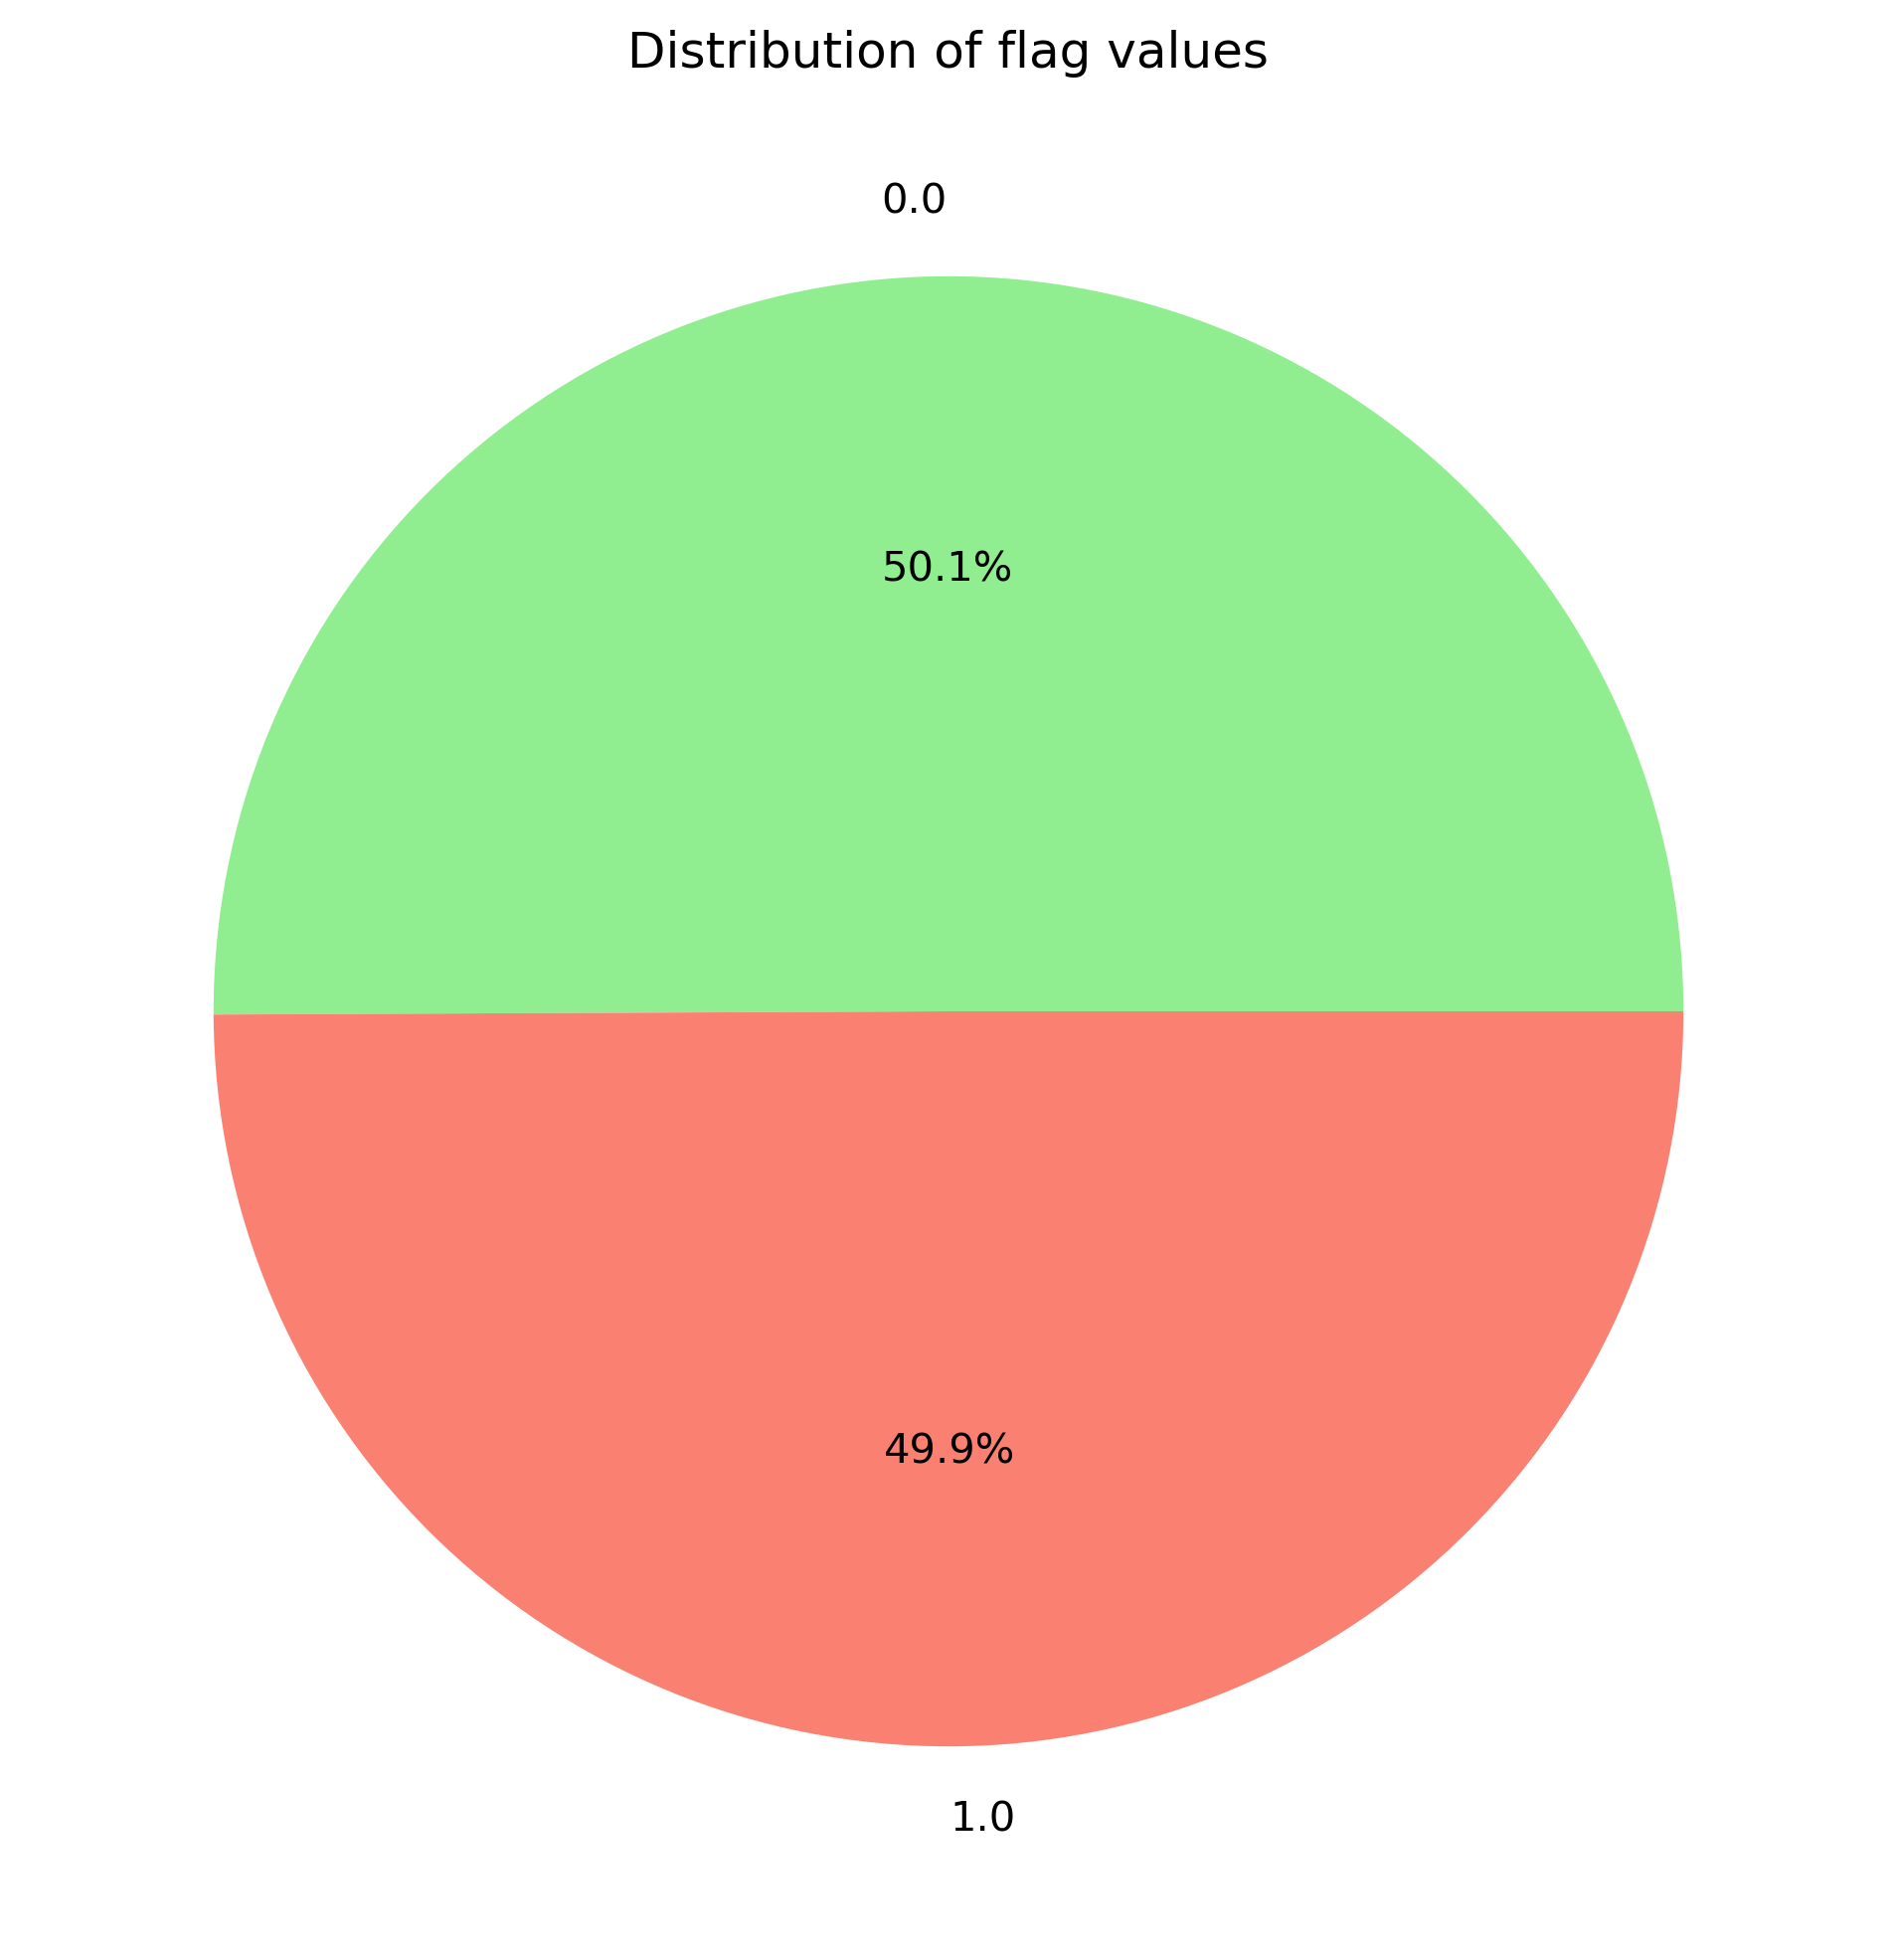

In [45]:
# Count the values of the 'flag' column

counts = joined_df['flag'].value_counts().sort_index()

plt.figure(figsize=(10, 8), dpi=300)
plt.pie(counts.values, 
        labels=counts.index,
        autopct='%1.1f%%',
        colors=['lightgreen', 'salmon'])
plt.title('Distribution of flag values')
plt.show()

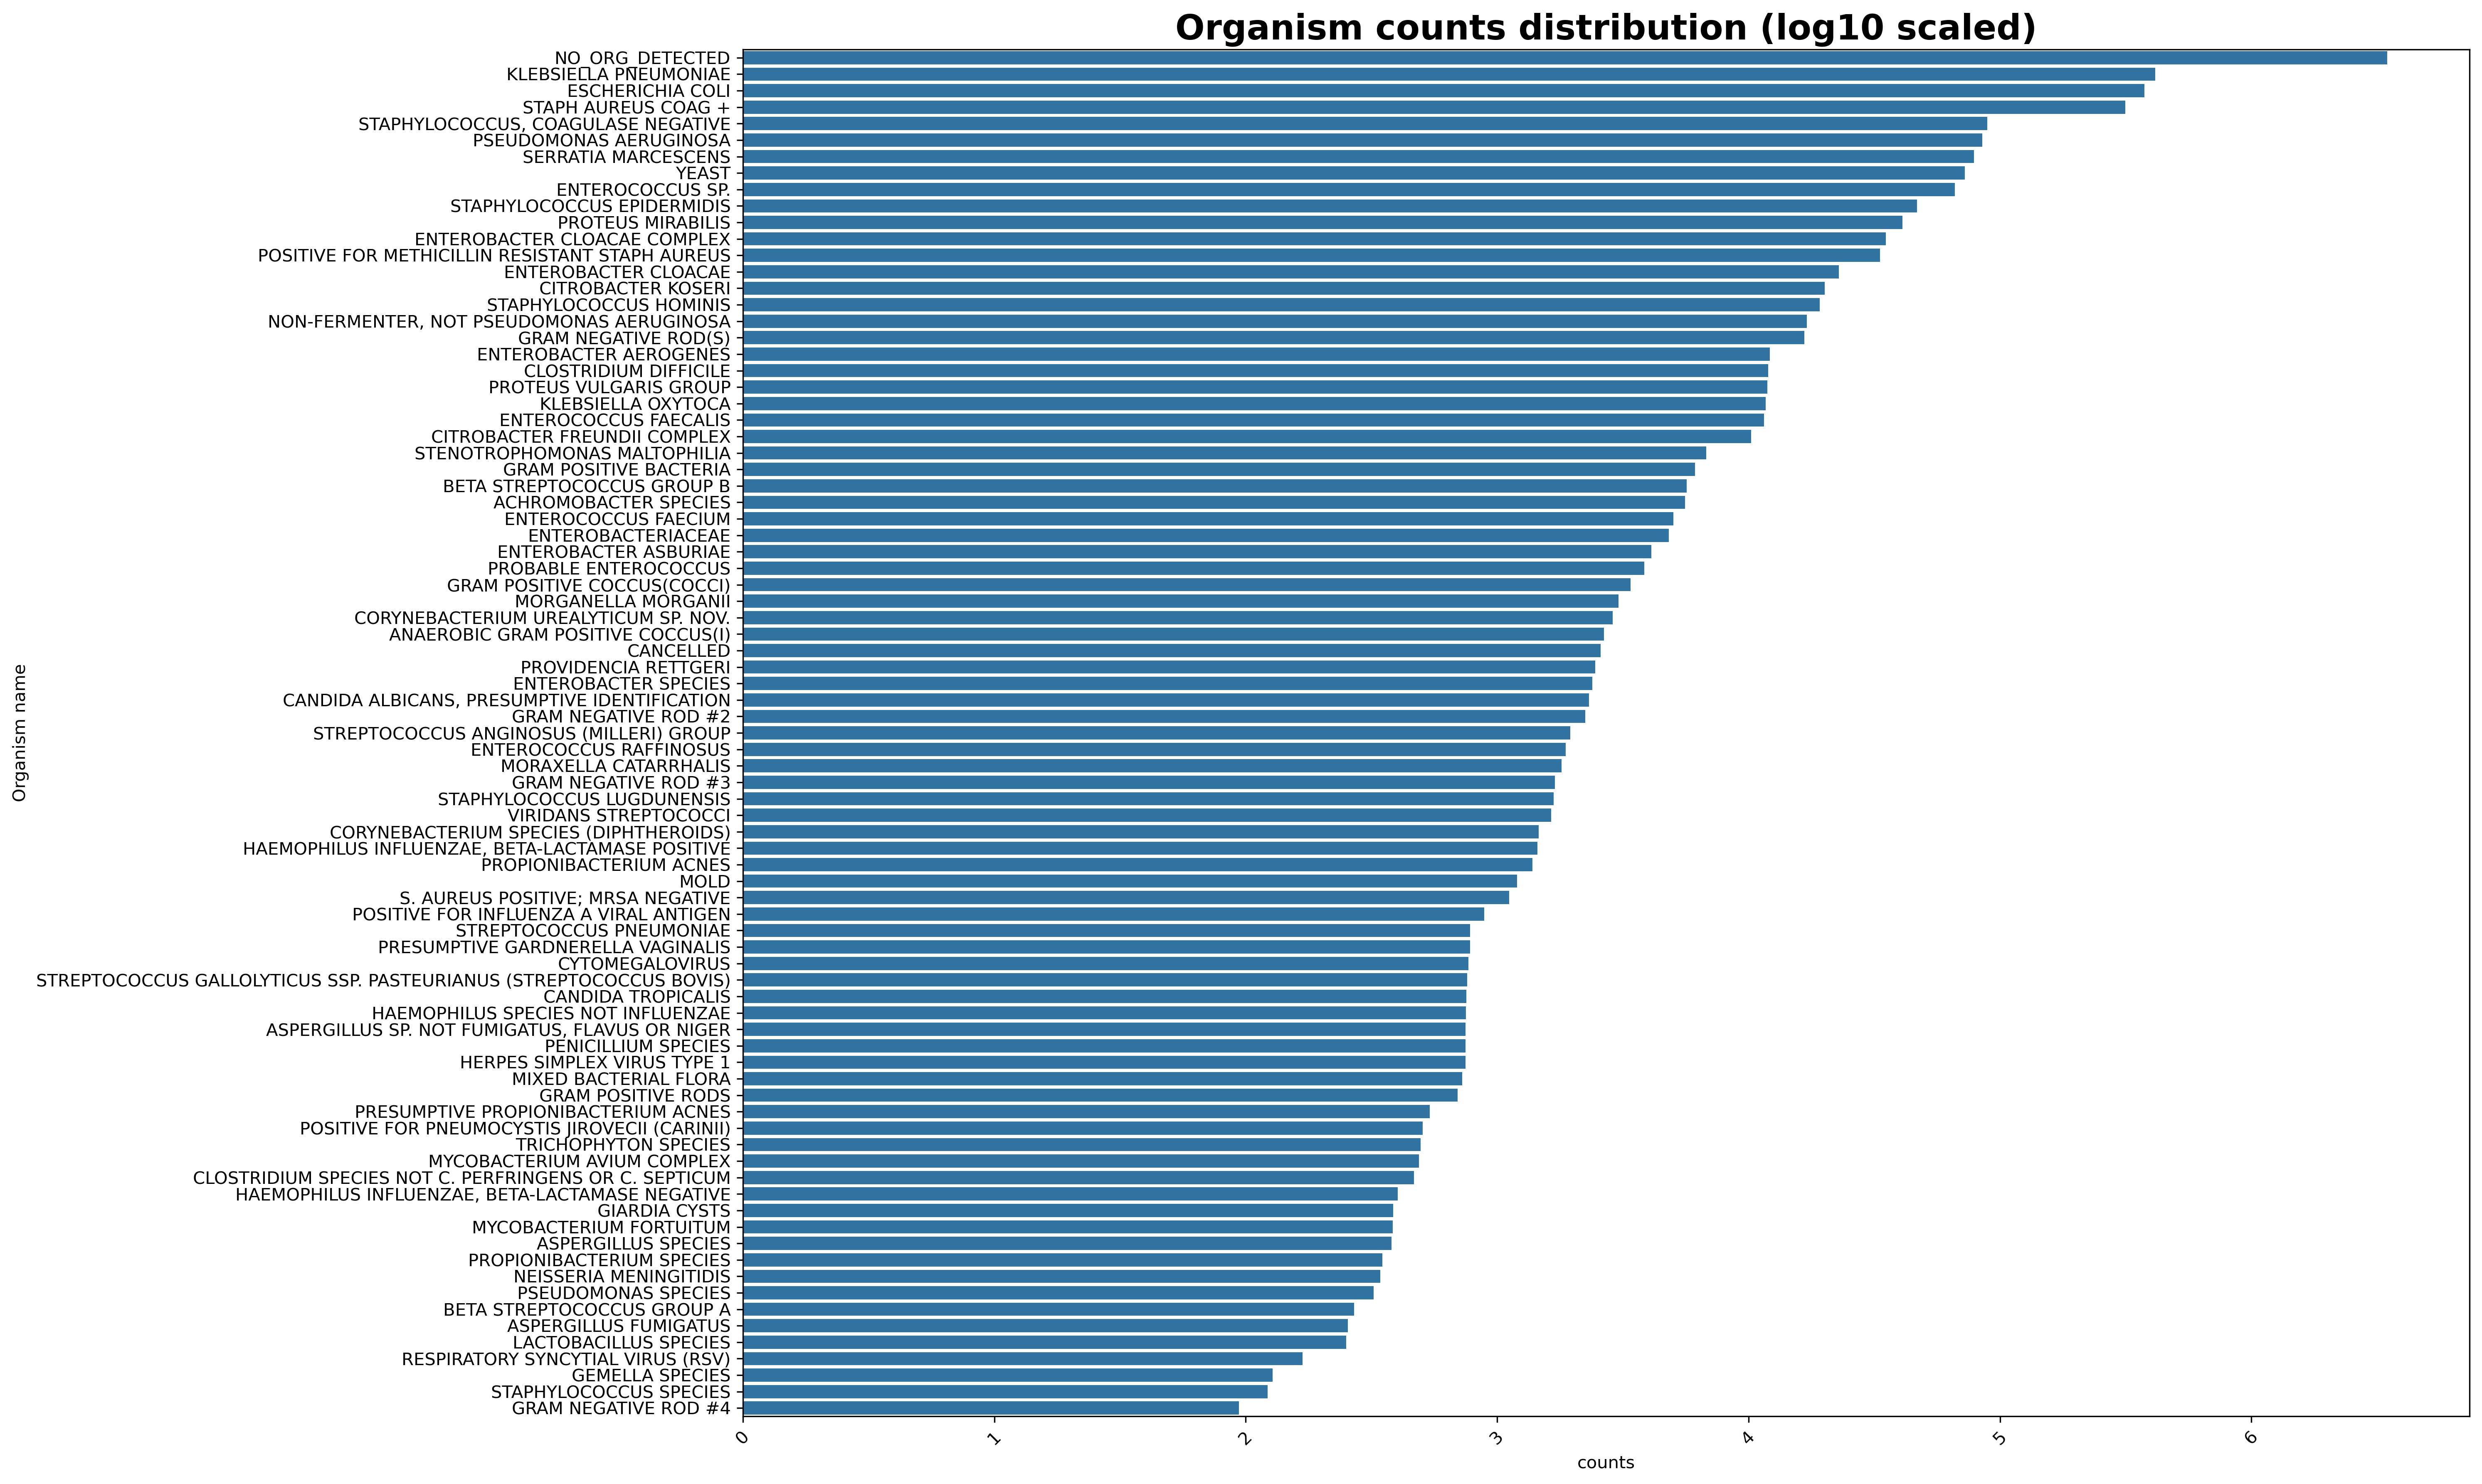

In [46]:
# Barplot of organism counts (log10 scaled)

org_count = np.log10(joined_df['org_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(y=org_count.index, x=org_count.values)
plt.title("Organism counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Organism name")
plt.xlabel("counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

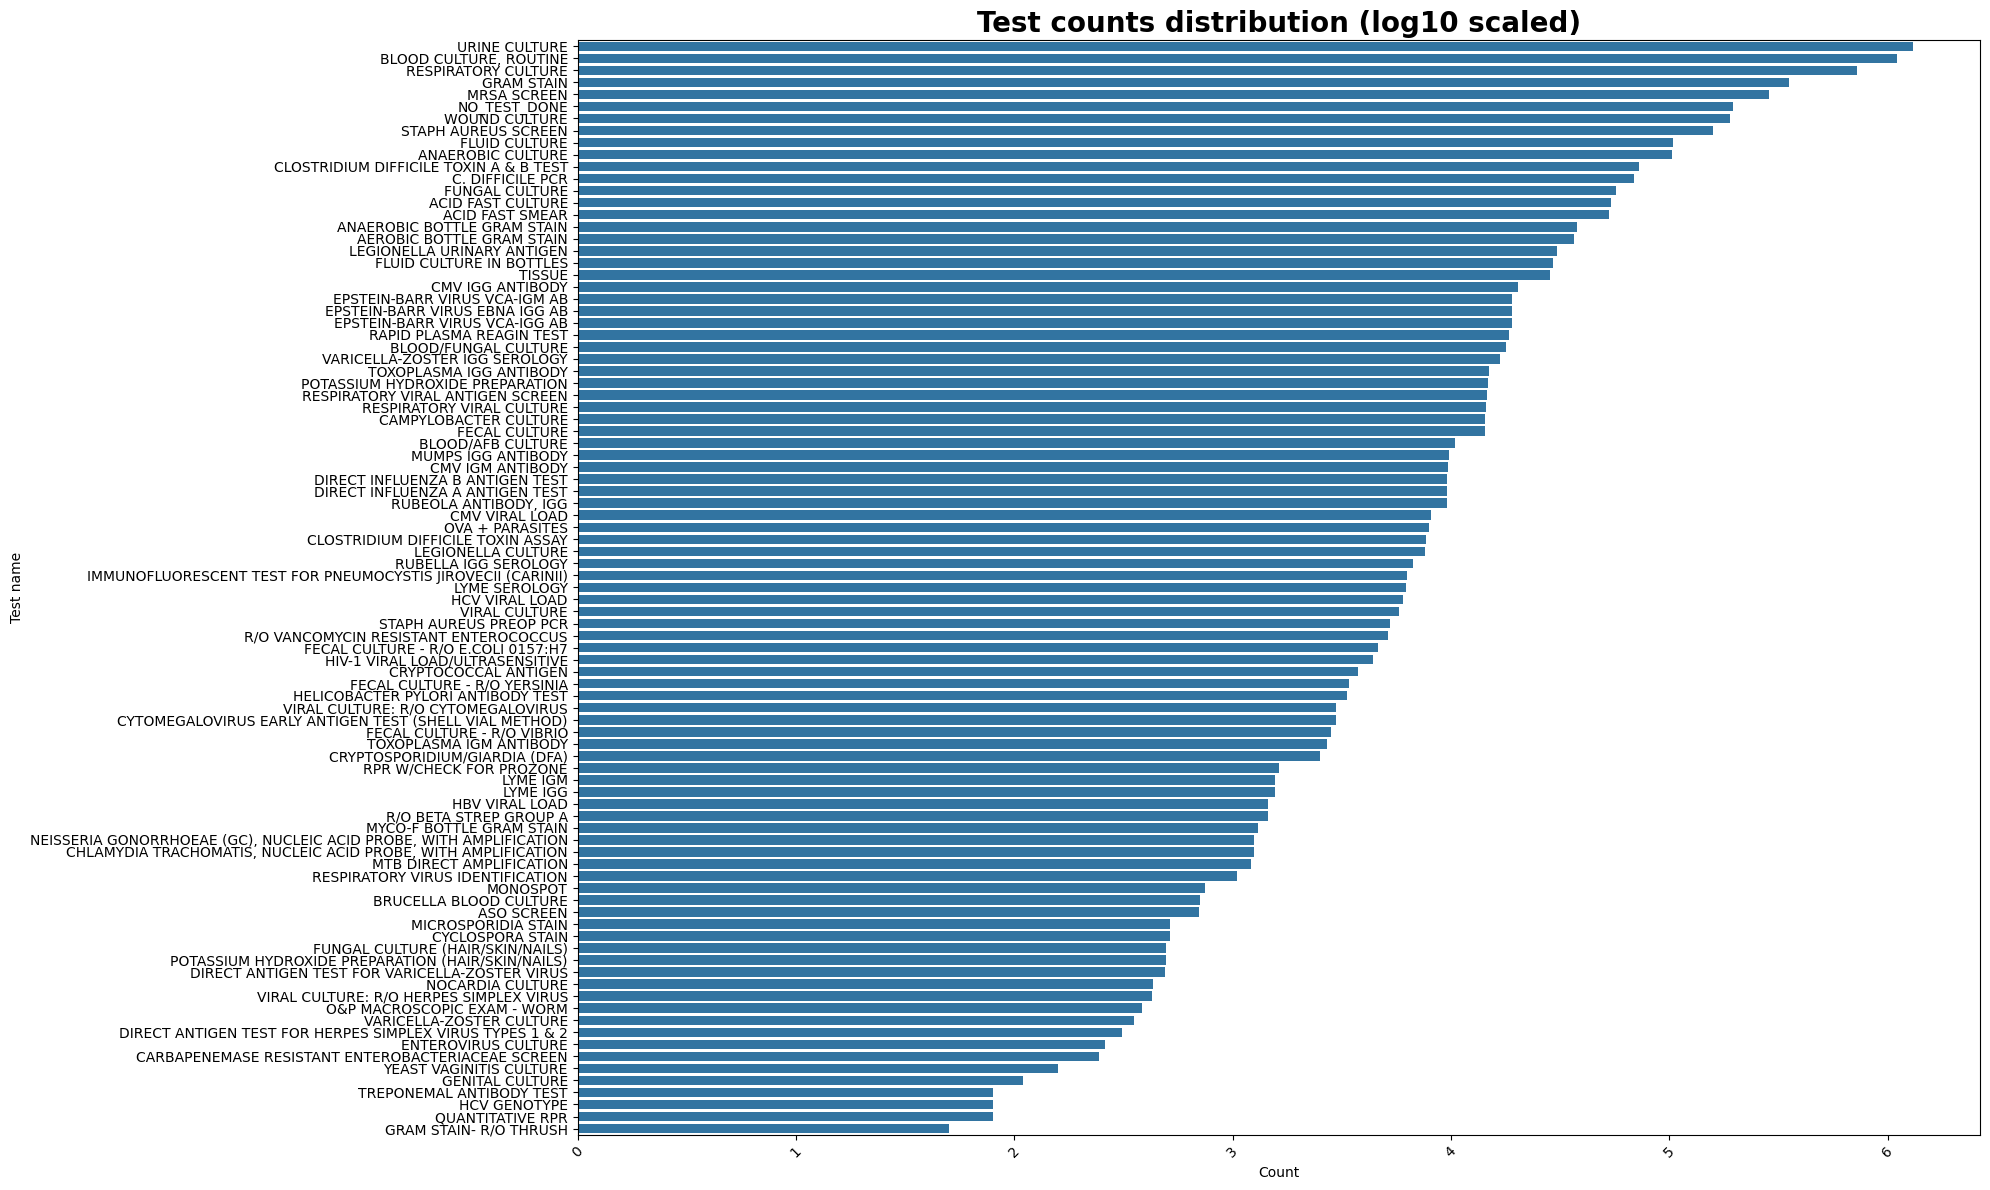

In [47]:
# Barplot of test name counts (log10 scaled)

test_count = np.log10(joined_df['test_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)
plt.title("Test counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Test name")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

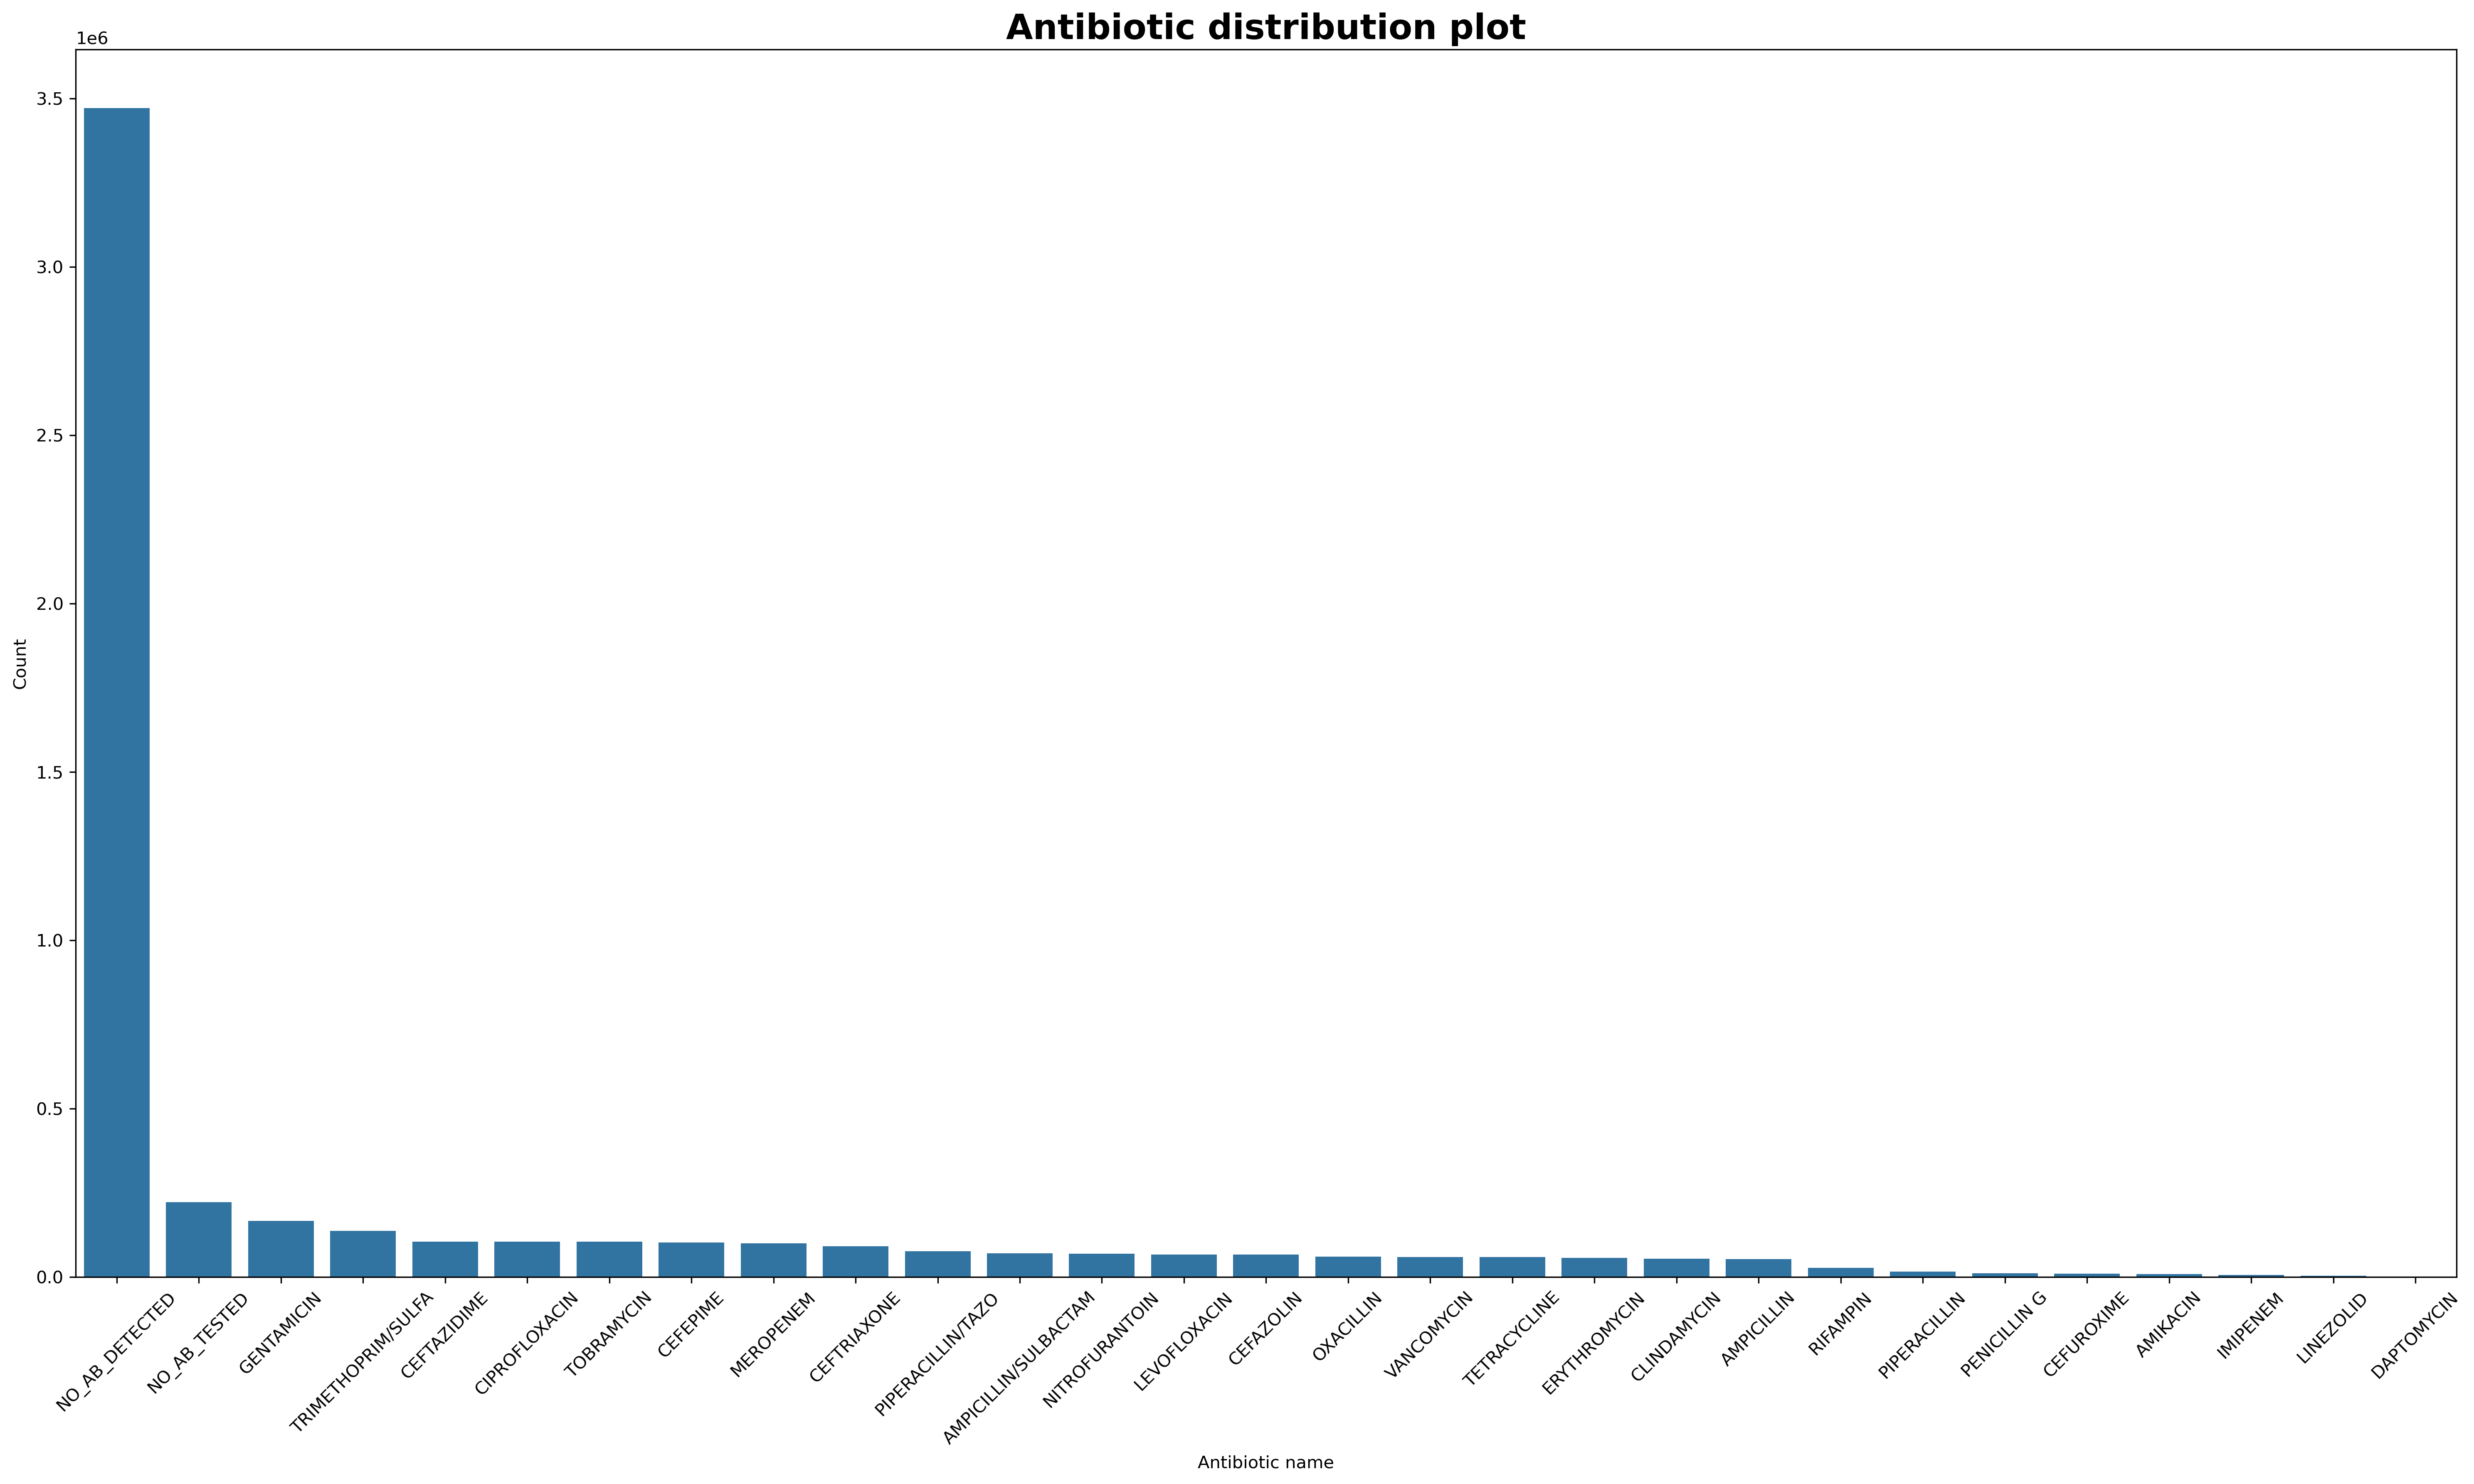

In [48]:
# Barplot of antibiotic name distribution

ab_count =joined_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(x=ab_count.index, y=ab_count.values)
plt.title("Antibiotic distribution plot", fontsize=20, fontweight="bold")
plt.xlabel("Antibiotic name")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

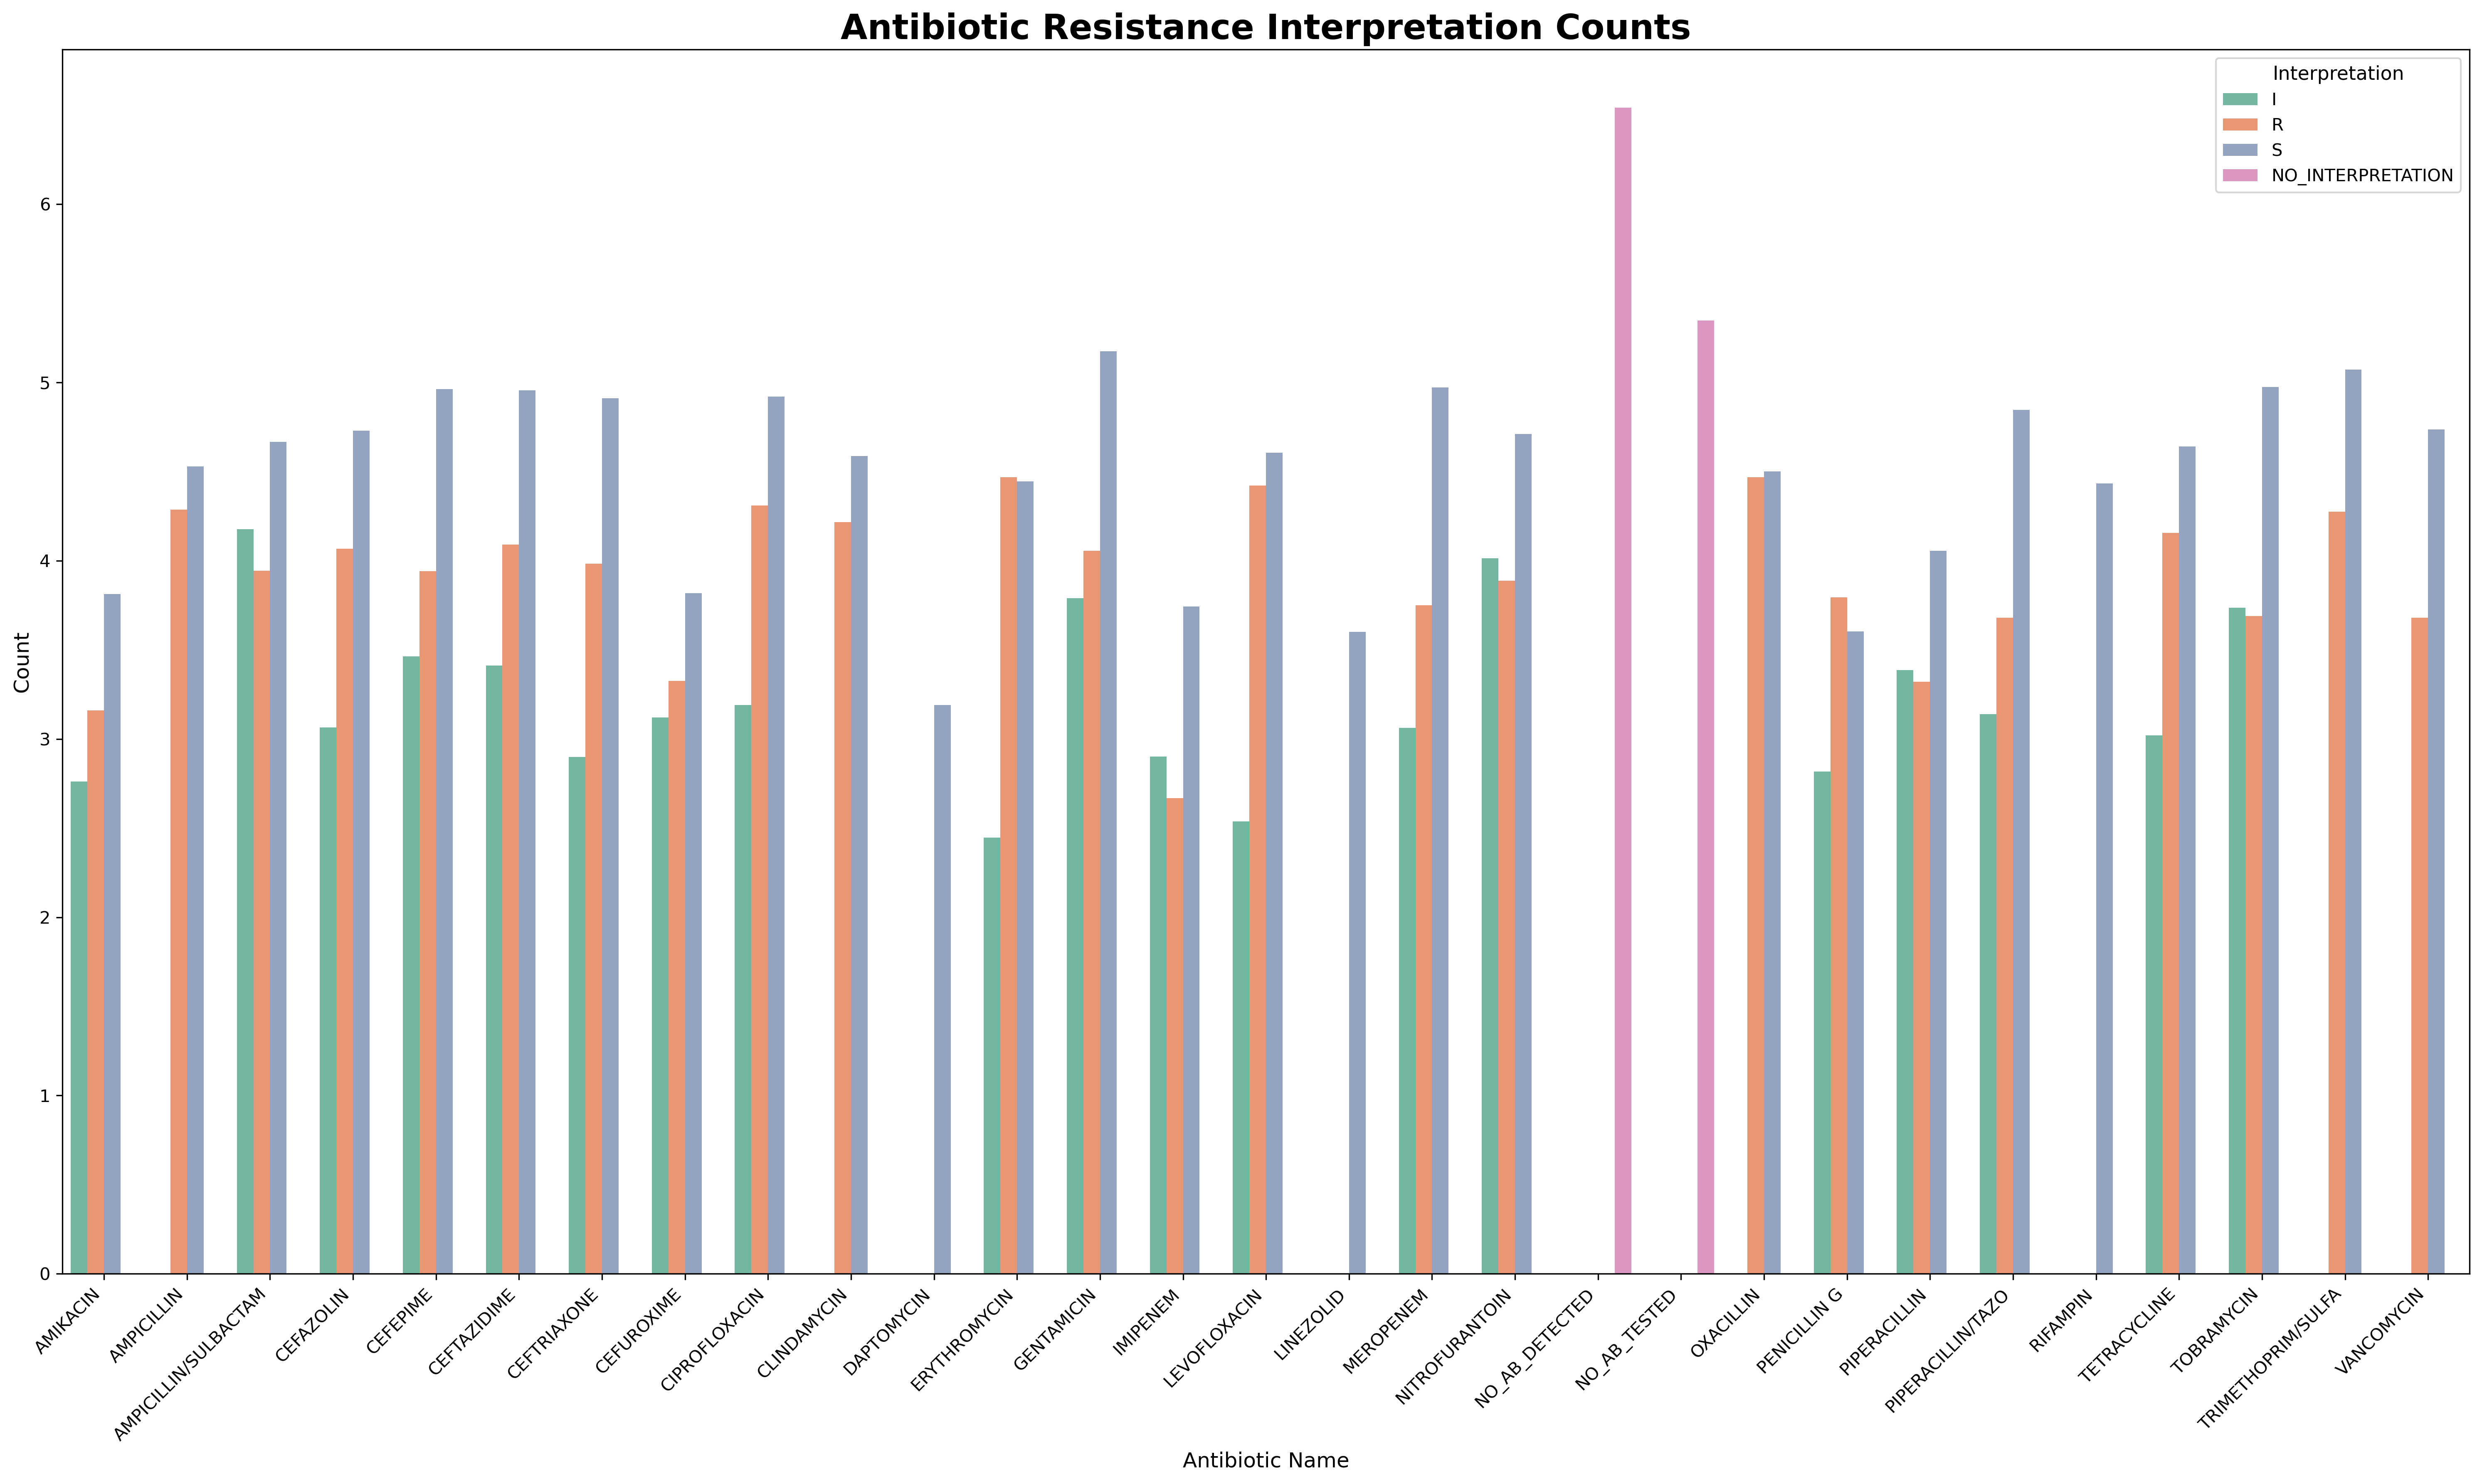

In [49]:
# Grouped barplot of antibiotic resistance interpretation counts

resistant_counts = np.log10(joined_df.groupby("ab_name")['interpretation'].value_counts().replace(0, np.nan))
counts_df = resistant_counts.reset_index(name='count')

interpretation_avg = counts_df.groupby('interpretation')['count'].mean().sort_values(ascending=True)
sorted_interpretations = interpretation_avg.index.tolist()

fig, ax = plt.subplots(figsize=(20,12), dpi=300)

sns.barplot(
    data=counts_df,
    x='ab_name',
    y='count',
    hue='interpretation',
    ax=ax,
    palette='Set2',
    hue_order=sorted_interpretations
)

ax.set_title('Antibiotic Resistance Interpretation Counts', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibiotic Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Interpretation', title_fontsize=11, fontsize=10)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

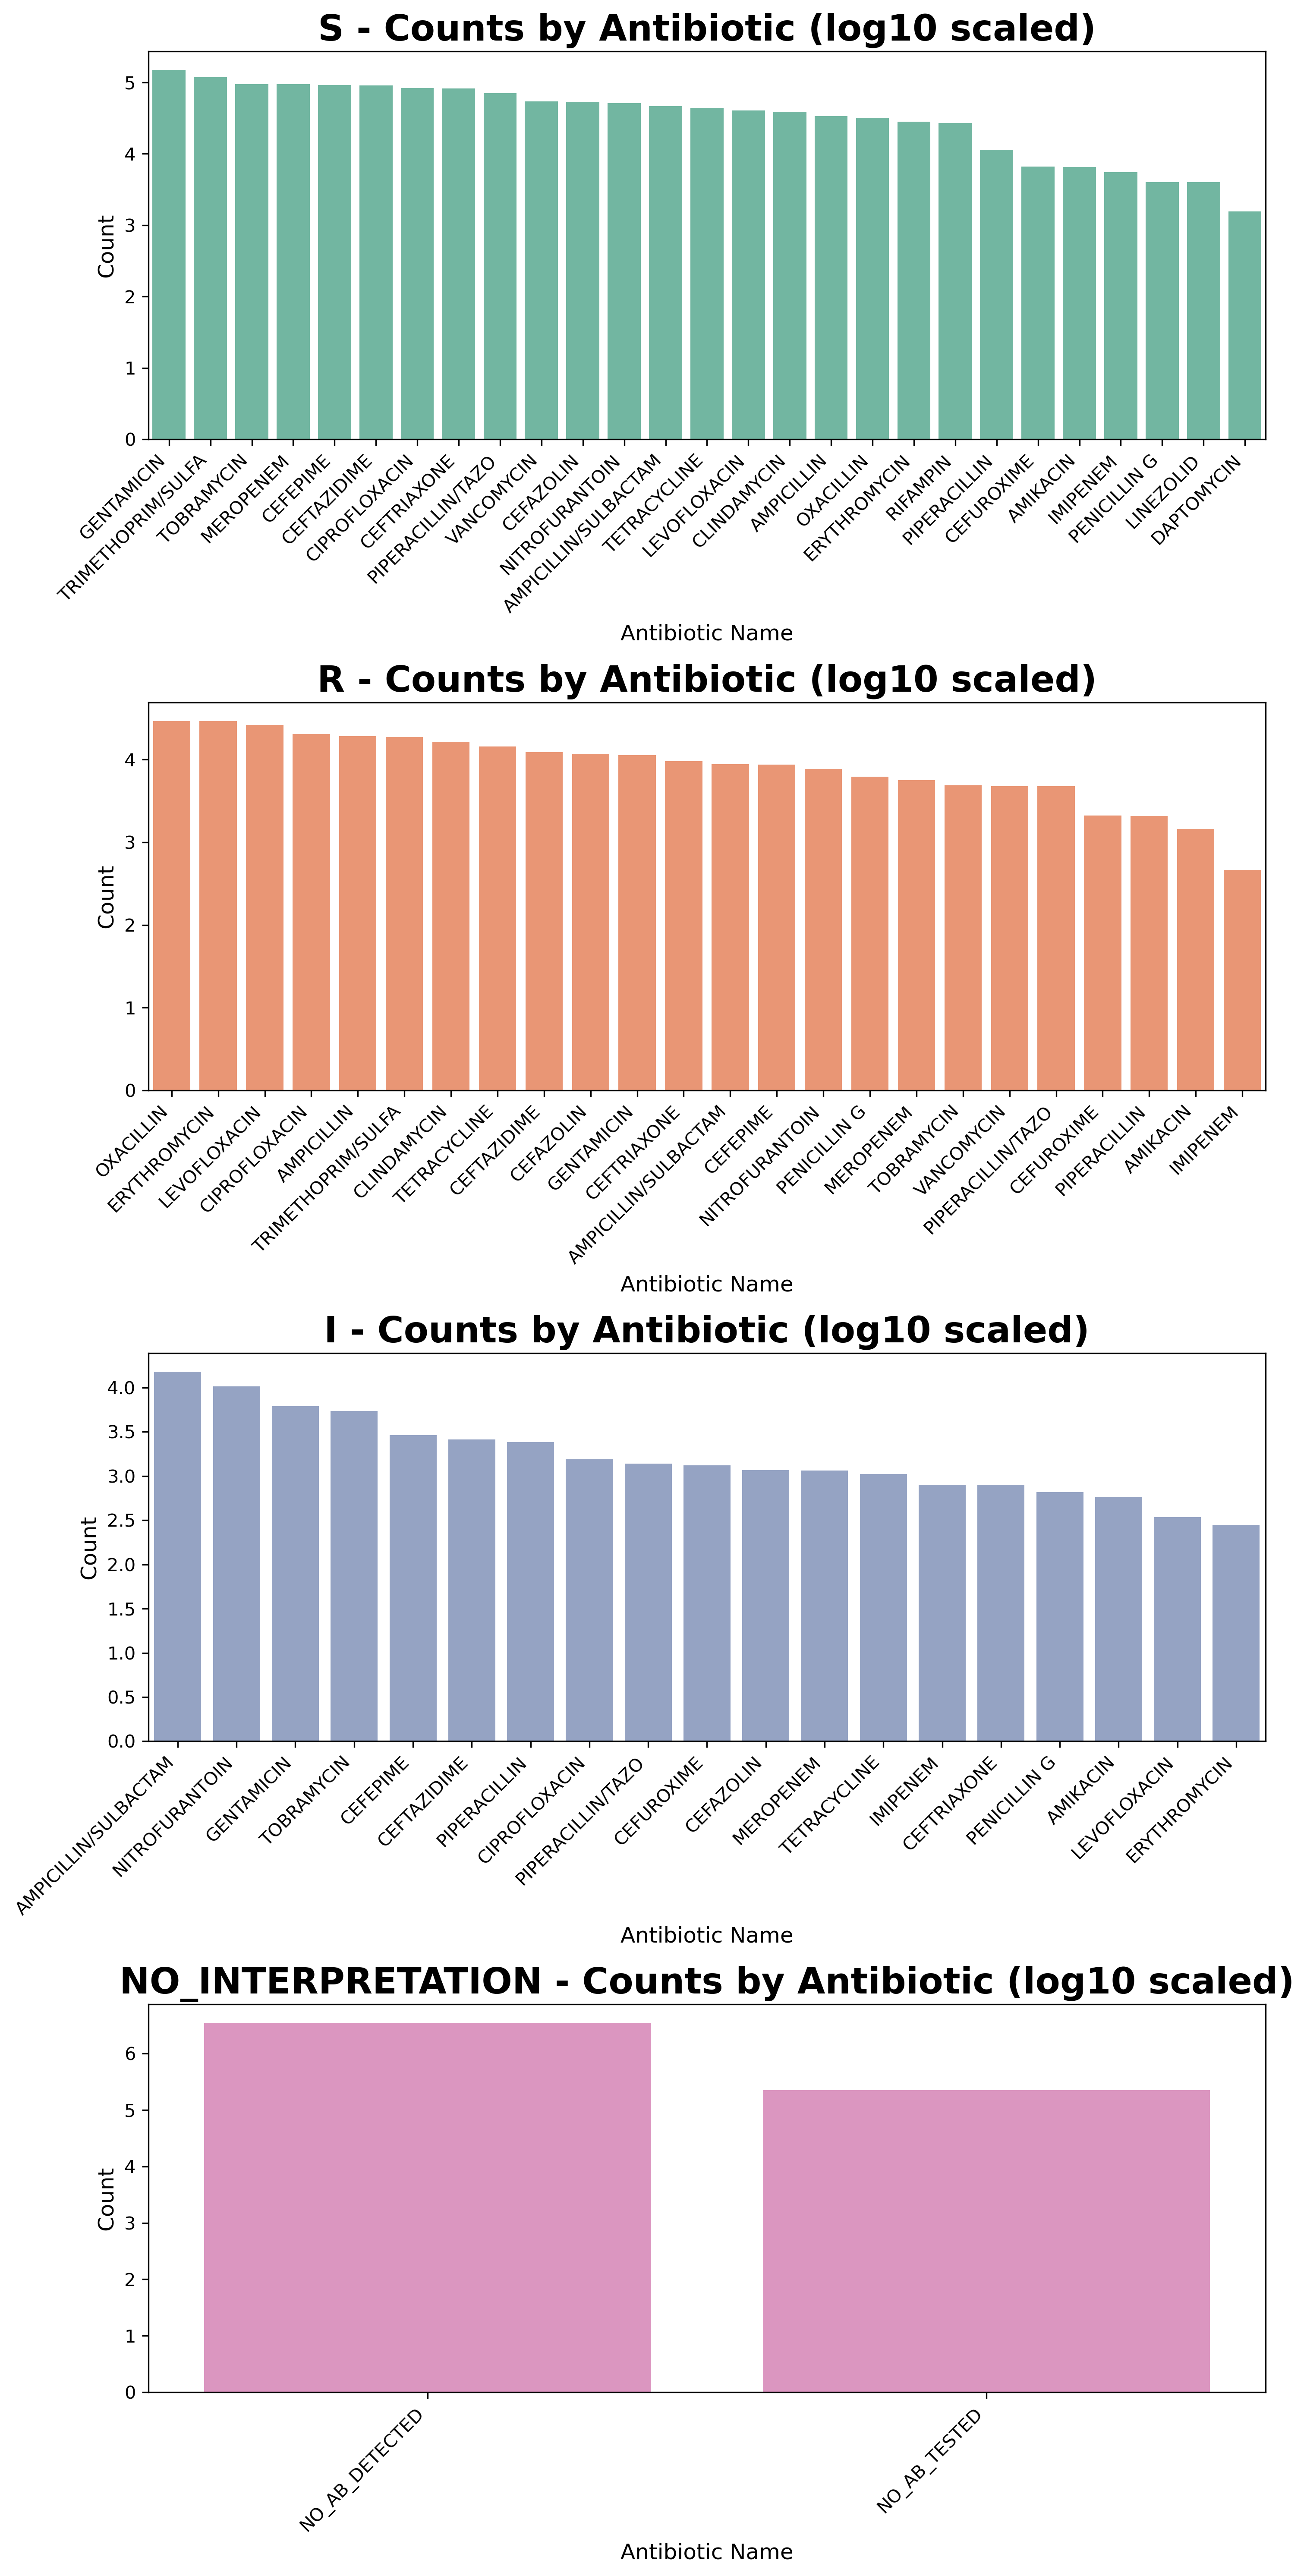

In [50]:
# Subplots of antibiotic resistance interpretation counts

interpretations = counts_df['interpretation'].unique()
n_interpretations = len(interpretations)

# Create subplots, one for each interpretation
fig, axes = plt.subplots(n_interpretations, 1, figsize=(10,  5* n_interpretations), dpi=300)

if n_interpretations == 1:
    axes = [axes]

for idx, interpretation in enumerate(interpretations):

    subset = counts_df[counts_df['interpretation'] == interpretation]
    
    subset = subset.sort_values('count', ascending=False)
    
    sns.barplot(
        data=subset,
        x='ab_name',
        y='count',
        ax=axes[idx],
        color=sns.color_palette('Set2')[idx % 10],
        order=subset['ab_name'] 
    )
    
    axes[idx].set_title(f'{interpretation} - Counts by Antibiotic (log10 scaled)', 
                        fontsize=20, fontweight='bold')
    axes[idx].set_xlabel('Antibiotic Name', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    
    axes[idx].tick_params(axis='x', rotation=45)
    plt.setp(axes[idx].xaxis.get_majorticklabels(), ha='right')

plt.tight_layout()
plt.show()